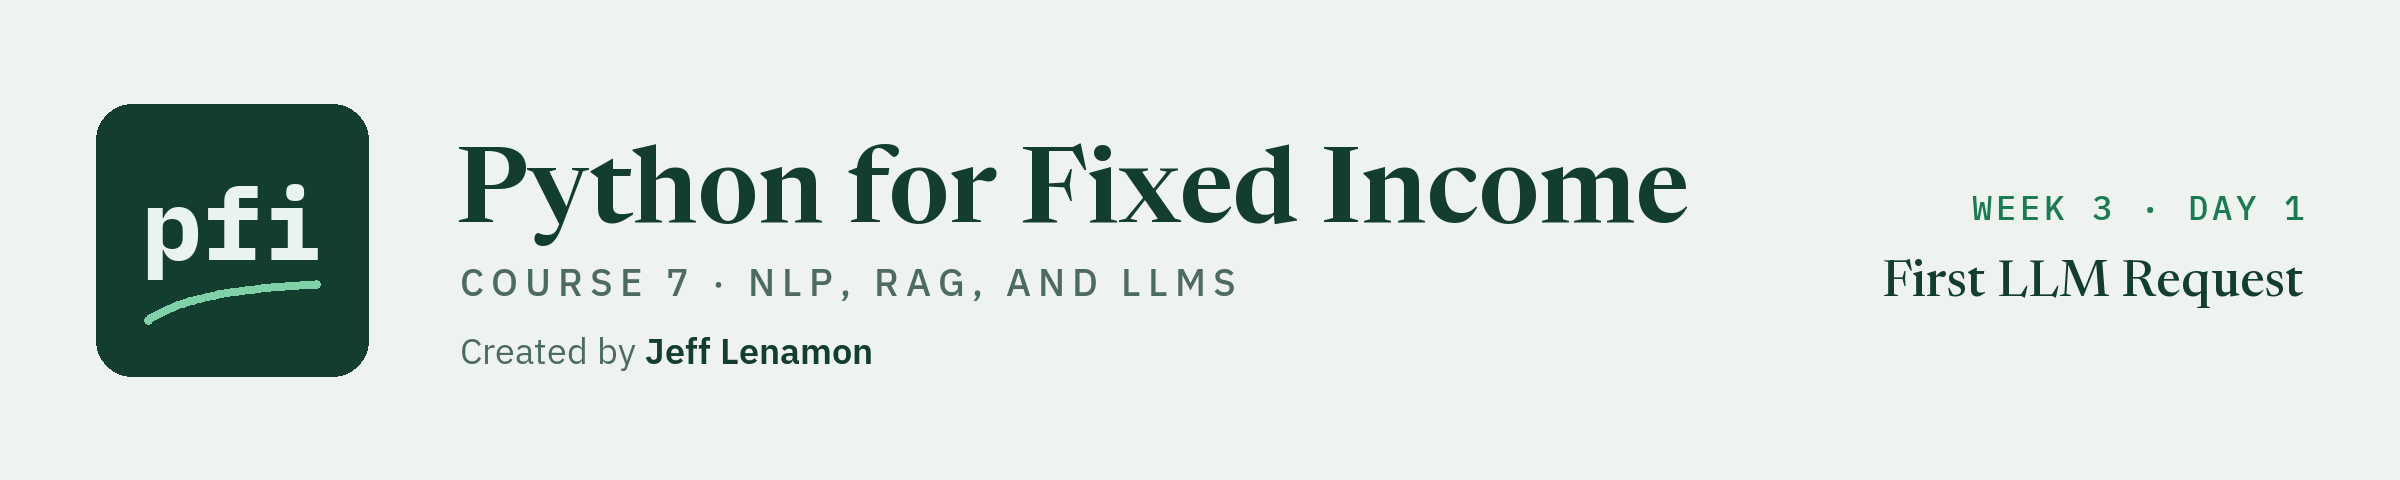

# First LLM Request

Week 3, Day 1. Today you send your first requests to a large language model from code: the key kept secret, the tokens counted, the cost priced, the answer checked against the document, and every response cached so the notebook replays without a key.

**Data:** `course7_fomc_statements.csv`, 226 FOMC post-meeting statements, 2000-02-02 to 2026-09-16: **real**, Board of Governors of the Federal Reserve System, public domain (federalreserve.gov).

**Data:** `course7_indentures/boyd_2021.txt`: Boyd Gaming Corporation, Indenture dated as of June 8, 2021, 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495: **real**, a public record on sec.gov, quoted for descriptive extraction only.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week3/day1/11_first_llm_call.ipynb)

Weeks 1 and 2 ran every model on your own machine. Today the model runs on someone else's: you send it text over the internet and it returns text. That is a **large language model** (LLM) reached through an **API**, and it is the tool of the rest of the course. Days 12 and 13 use it to pull covenant terms out of an indenture, and day 14 to answer questions from one with citations. Today is the plumbing: what a request is, where the key lives, what a response costs, why two runs of the same request can differ, and how a notebook replays saved responses.

**The rules for real documents, as on every day of this course.**

* **The documents are real.** The FOMC statements are the Board of Governors' own text, public domain. The indenture is a public record on sec.gov, filed by its issuer. A source line sits under every excerpt.
* **Every prompt asks what the document says.** Each request today asks for a quote, a summary of what a statement says, or "NOT IN TEXT". The system prompt that goes first in every request refuses anything else. No prompt asks for an opinion, a grade, a comparison of issuers, or a view about the future.
* **A response is text a model returned.** It is called "the response" or "the saved response", never the model's opinion or view, and every number about one is read from the saved file.
* **Issuer names appear only as the authors of the documents being read**: in the data lines and the source lines.

**Rows.** No model is fitted or scored in this notebook. Every response it prints is a **saved response**: the text a model returned to a request the course sent on 2026-10-08, stored in `data/course7_llm_responses/day11/` and replayed here. With your own key, a run of this notebook sends the requests again, and its text can differ from the saved responses; the line under each response says which it was.

Today you will:

1. Read what a request is: a model id, a list of messages, and parameters.
2. Meet OpenRouter: one key, many models, the free ones and their limits.
3. Load the key the way Course 3 did, and check Git ignores it before anything is sent.
4. Write `ask`, docstring first: the system prompt, the cache, live and replay.
5. Send the first request about an FOMC statement, and check the answer against day 1's regular expression.
6. Send one paragraph of the indenture with a question it answers and one it does not.
7. Read the token counts and price them with `usage_cost`, on the free model and on the paid fallback.
8. See why the course switches the model's reasoning off.
9. Put temperature 0 and temperature 1 side by side.
10. See what the cache stores and how replay works, make requests fail on purpose with a fake client, and switch the route to OpenAI.
11. Read every setting of the chat request, draw `top_p` by hand, and put four saved answers side by side.

Q. Set up today's work folder: the thread settings, the quiet-loading settings, the seed, and today's two data files.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course07_nlp_and_llms/requirements.txt
NEEDED = {
    "bs4": "beautifulsoup4==4.15.0",
    "huggingface_hub": "huggingface-hub==1.33.0",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "keras": "keras==3.15.1",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openai": "openai==3.26.0",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pydantic": "pydantic==2.13.5",
    "pypdf": "pypdf==6.19.0",
    "pypdfium2": "pypdfium2==5.14.0",
    "pytest": "pytest==9.1.1",
    "dotenv": "python-dotenv==1.2.4",
    "requests": "requests==2.34.2",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "sentence_transformers": "sentence-transformers==6.1.0",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "tensorflow": "tensorflow==2.21.0",
    "torch": "torch==2.14.1",
    "transformers": "transformers==5.19.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

28 packages checked, all present


In [2]:
# today's setup: thread settings, quiet model loading, the modules, the seed, the course data, a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These lines must run before numpy, pandas, scikit-learn, or PyTorch is imported: if you ran another cell first,
# restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

# the model libraries print download bars and notices; these lines must run before they are imported
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("sklearn", "scikit-learn"), ("torch", "torch"), ("transformers", "transformers"), ("sentence_transformers", "sentence-transformers"), ("openai", "openai"), ("pydantic", "pydantic"), ("bs4", "beautifulsoup4"), ("pypdf", "pypdf"), ("pypdfium2", "pypdfium2"), ("dotenv", "python-dotenv"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course07_nlp_and_llms/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "torch": "2.14.1", "transformers": "5.19.0", "sentence-transformers": "6.1.0", "openai": "3.26.0", "pydantic": "2.13.5", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name].split("+")[0] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "course7_fomc_statements.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course7_11_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["course7_fomc_statements.csv", "course7_indentures/boyd_2021.txt"]
for name in DATA_FILES:
    (work / name).parent.mkdir(parents=True, exist_ok=True)
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, torch 2.14.1, transformers 5.19.0, sentence-transformers 6.1.0, openai 3.26.0, pydantic 2.13.5, pytest 9.1.1
Work folder: pfi_course7_11_bckcecwn, in your temp folder
Data files from the data folder of the course repo: course7_fomc_statements.csv, course7_indentures/boyd_2021.txt
SEED = 42


* The setup cell is day 1's, line for line (day 1 explains each line). Today runs no Hugging Face model, so the cell has no PyTorch line.
* Two files are copied into the work folder: the FOMC statements and the Boyd indenture's text.
* **A live run differs from this notebook.** This notebook was saved in replay mode: no key was loaded, and every response is one the course saved. With your own key the requests go out again, and a model's text can change from run to run (section 11.9 shows how much). Every response cell ends with a line that says which mode printed it.

Q. Write the earlier courses' modules today needs, unchanged: `mlkit.py`, `plotkit.py`, `marketdata.py`, `bondmath.py`.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


In [4]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [5]:
%%writefile marketdata.py
"""marketdata: dated market series for fixed income, checked against Excel.

Written day by day in Python for Fixed Income, Course 3: Market Data and Time Series.

Conventions, the same in every function:
- A series has a DatetimeIndex named date: naive calendar dates (no time, no time zone), unique and ascending.
- Yields are in percent (5.29 means 5.29 percent), as Treasury and FRED publish them. Spreads are in basis points.
- Changes of yields and spreads are in basis points. Price changes are simple returns in percent.
- Windows are counted in observations (rows of the market calendar), trailing, and include the current row.
- A missing observation is NaN. It is dropped before any change or window is computed, never filled.
- A secret (an API key) is never printed, written to a file, or put in an error message.
"""
import os  # environment variables
from pathlib import Path  # file paths


def get_secret(name: str, env_file: str | Path) -> str:
    """Return a secret such as an API key, looked up in three places in a fixed order.

    Units: none; the secret is text. Convention: the first place that holds a non-empty value wins:
    1. the environment variable `name`;
    2. Colab's Secrets panel (google.colab.userdata), only when running in Colab;
    3. the .env file at `env_file`, read with dotenv.dotenv_values, which does not change os.environ.
    The value is returned and never printed. Raises RuntimeError naming the secret and the three places
    looked, never a value and never the full path of the file.
    """
    # 1. the environment: a variable set in PowerShell, or by the program that started Python
    value = os.environ.get(name)
    if value:
        return value

    # 2. Colab's Secrets panel: the import works only inside Colab
    try:
        from google.colab import userdata
    except ImportError:
        userdata = None
    if userdata is not None:
        try:
            value = userdata.get(name)
        # a secret that is not there, or one the notebook has not been given access to
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
            value = None
        if value:
            return value

    # 3. the .env file, imported here so Colab never needs python-dotenv
    env_path = Path(env_file)
    if env_path.is_file():
        from dotenv import dotenv_values
        value = dotenv_values(env_path).get(name)
        if value:
            return value

    # nothing found: say where we looked, with the file's name only (a full path shows a user name)
    raise RuntimeError(
        f"Secret {name} not found. Looked in: the environment variable {name}, "
        f"Colab's Secrets panel, and the file {env_path.name} given as env_file."
    )


import pandas as pd  # dated series, from day 2
import requests  # HTTP, from day 2

# FRED's endpoint for the observations of one series
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"


def fred_params(series_id: str, api_key: str, start: str | None = None, end: str | None = None) -> dict:
    """The query parameters for one request to FRED's series/observations endpoint.

    Units: start and end are dates as text, YYYY-MM-DD. Convention: JSON is asked for (file_type json);
    a start or end left as None is not sent, so FRED returns the series from its first or to its last date.
    Pure: builds a dict and sends nothing. The dict holds the key, so it is never printed.
    """
    # the three parameters every request needs
    params = {"series_id": series_id, "api_key": api_key, "file_type": "json"}
    # the optional date range
    if start is not None:
        params["observation_start"] = start
    if end is not None:
        params["observation_end"] = end
    return params


def parse_fred_observations(payload: dict, name: str) -> pd.Series:
    """Turn a FRED series/observations JSON answer into a float series.

    Units: as FRED publishes the series (percent for the Treasury and spread series).
    Convention: one value per observation, indexed by its date (a DatetimeIndex named date). FRED's
    missing marker "." becomes NaN and is kept: dropping it is a separate, visible step.
    Raises ValueError if the answer has no "observations" list.
    """
    # stop on an answer that is not a series/observations answer
    if "observations" not in payload:
        raise ValueError(f"the answer for {name} has no 'observations'; keys are {sorted(payload)}")
    observations = payload["observations"]
    # each date as a calendar date
    dates = pd.to_datetime([obs["date"] for obs in observations], format="%Y-%m-%d")
    # each value as a float; "." is FRED's mark for a day with no value, so it becomes NaN, never 0
    values = [float("nan") if obs["value"] == "." else float(obs["value"]) for obs in observations]
    series = pd.Series(values, index=dates, name=name, dtype="float64")
    series.index.name = "date"
    return series


def fred_series(series_id: str, api_key: str, start: str | None = None, end: str | None = None,
                timeout: float = 30) -> pd.Series:
    """Download one series from the FRED API: one GET with requests, then parse_fred_observations.

    Units: as FRED publishes the series. Convention: "." rows are kept as NaN, as parse_fred_observations.
    The only function in this module that uses the network.
    Errors never show the key or the URL (which holds the key):
    - it never calls response.raise_for_status(), whose message holds the full URL;
    - an answer other than HTTP 200 raises RuntimeError with the status and FRED's own error message;
    - a connection problem (requests.RequestException) raises RuntimeError naming only the exception class;
    - both are raised `from None`, so no chained traceback shows the original error and its URL.
    Raises RuntimeError if FRED answers with zero observations (FRED returns HTTP 200 with count 0 for a
    range the series does not cover).
    """
    # the request, sent once; the parameters (and the key) stay inside requests
    try:
        response = requests.get(FRED_URL, params=fred_params(series_id, api_key, start, end), timeout=timeout)
    except requests.RequestException as error:
        # the original message holds the URL with the key, so only the class name is kept
        raise RuntimeError(f"Request for {series_id} failed: {type(error).__name__}") from None

    # an answer other than 200: FRED puts its reason in "error_message"
    status = response.status_code
    if status != 200:
        try:
            error_message = response.json().get("error_message", "no error message")
        except ValueError:
            error_message = "the answer was not JSON"
        # FRED's messages do not echo the key; replace it anyway in case one ever does
        error_message = error_message.replace(api_key, "***")
        raise RuntimeError(f"FRED returned HTTP {status} for {series_id}: {error_message}") from None

    # parse, and stop on an empty answer
    series = parse_fred_observations(response.json(), series_id)
    if series.empty:
        raise RuntimeError(f"FRED returned no observations for {series_id} (start {start}, end {end})")
    return series


def _check_index(index: pd.Index, what: str) -> None:
    """Stop unless `index` is a DatetimeIndex with unique dates in ascending order.

    A helper for the functions below (the leading underscore marks it as not part of the module's API).
    """
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{what} must have a DatetimeIndex, not {type(index).__name__}")
    if not index.is_unique:
        raise ValueError(f"{what} has repeated dates, for example {index[index.duplicated()][0].date()}")
    if not index.is_monotonic_increasing:
        raise ValueError(f"{what} dates are not in ascending order")


def missing_weekdays(index: pd.DatetimeIndex) -> pd.DatetimeIndex:
    """The weekdays from the first date to the last that have no row.

    Units: dates. Convention: a weekday is Monday to Friday; no holiday calendar is used, so the result is
    every weekday the data skipped (holidays and any other closure). Weekends are never counted.
    Raises ValueError on an index that is not unique and ascending dates.
    """
    _check_index(index, "index")
    # every Monday to Friday in the span
    weekdays = pd.bdate_range(index[0], index[-1])
    # the ones with no row
    missing = weekdays.difference(index)
    missing.name = "date"
    return missing


def align(series: dict[str, pd.Series], how: str = "inner") -> pd.DataFrame:
    """Put several dated series side by side, one column each, joined on date.

    Units: each column keeps its own units. Convention: how="inner" keeps the dates every series has;
    how="outer" keeps every date any series has and leaves NaN where a series has no row. Nothing is filled.
    Raises ValueError for any other `how`, or for a series whose index is not unique ascending dates.
    """
    # stop on a join the course does not use
    if how not in ("inner", "outer"):
        raise ValueError(f"how must be 'inner' or 'outer', not {how!r}")
    for name, values in series.items():
        _check_index(values.index, name)
    # one column per series, named by its key
    frame = pd.concat(series, axis=1, join=how)
    # an outer join can mix the order of dates, so sort them
    frame = frame.sort_index()
    frame.index.name = "date"
    return frame


def stale_runs(series: pd.Series, min_length: int = 3) -> pd.DataFrame:
    """Runs of the same value repeated on consecutive observations: a sign of a value that stopped updating.

    Units: `value` has the series' units, `length` counts observations. Convention: consecutive means
    consecutive rows, whatever the calendar gap. One row per run of at least `min_length` identical values,
    with columns start, end, length, value.
    Raises ValueError if min_length is below 2, the series has missing values (drop them first), or its index
    is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if min_length < 2:
        raise ValueError(f"min_length must be at least 2, not {min_length}")
    if series.isna().any():
        raise ValueError(f"series has {series.isna().sum()} missing values; drop them first with .dropna()")
    # a new run starts wherever the value differs from the row before
    run_id = (series != series.shift()).cumsum()
    runs = []
    for _, run in series.groupby(run_id):
        # keep runs long enough to report
        if len(run) >= min_length:
            runs.append({"start": run.index[0], "end": run.index[-1], "length": len(run), "value": run.iloc[0]})
    return pd.DataFrame(runs, columns=["start", "end", "length", "value"])


def _check_series(series: pd.Series, what: str) -> None:
    """Stop unless `series` has unique ascending dates and no missing values (a helper, not part of the API)."""
    _check_index(series.index, what)
    if series.isna().any():
        raise ValueError(f"{what} has {series.isna().sum()} missing values; drop them first with .dropna()")


def last_per_period(data: pd.Series | pd.DataFrame, freq: str) -> pd.Series | pd.DataFrame:
    """The last observation in each week or month, labelled by the date of that observation.

    Units: unchanged. Convention: freq "W-FRI" is the week ending Friday, "ME" the calendar month. Each
    period's row is the last row the data has in it, kept with its own date: September 2026 is labelled
    2026-09-30, and the week of Good Friday 2025 (no row on Friday 2025-04-18) is labelled Thursday 2025-04-17.
    pandas' resample(freq).last() labels by the period end instead. A Series must have no missing values;
    a DataFrame's rows are taken as they are, so a tenor with no value that day stays NaN.
    Raises ValueError for any other freq, or for an index that is not unique ascending dates.
    """
    # the two periods the course uses, with pandas' name for each period
    periods = {"W-FRI": "W-FRI", "ME": "M"}
    if freq not in periods:
        raise ValueError(f"freq must be 'W-FRI' or 'ME', not {freq!r}")
    if isinstance(data, pd.Series):
        _check_series(data, "data")
    else:
        _check_index(data.index, "data")
    # the period each row belongs to
    period_of_row = data.index.to_period(periods[freq])
    # the position of the last row in each period
    positions = pd.Series(range(len(data)), index=data.index).groupby(period_of_row).max()
    # those rows, with their own dates
    return data.iloc[positions.to_numpy()]


def value_as_of(series: pd.Series, as_of) -> tuple[pd.Timestamp, float]:
    """The date and value of the last observation on or before `as_of`.

    Units: the value has the series' units. Convention: the as-of value; on a holiday or weekend it is
    the previous market day's value. Excel: =XLOOKUP(as_of, dates, values, , -1).
    Raises ValueError if as_of is before the first observation, the series has missing values, or its
    index is not unique ascending dates.
    """
    _check_series(series, "series")
    as_of = pd.Timestamp(as_of)
    # stop before the start: there is no value to carry
    if as_of < series.index[0]:
        raise ValueError(f"{as_of.date()} is before the first observation, {series.index[0].date()}")
    # the position of the last date on or before as_of
    position = series.index.searchsorted(as_of, side="right") - 1
    return series.index[position], float(series.iloc[position])


from datetime import date, datetime  # the cache file's date, from day 5

# FRED's Treasury constant maturity series and the Treasury file's column for each
FRED_TREASURY = {
    "DGS1MO": "1 Mo", "DGS3MO": "3 Mo", "DGS6MO": "6 Mo", "DGS1": "1 Yr", "DGS2": "2 Yr", "DGS3": "3 Yr",
    "DGS5": "5 Yr", "DGS7": "7 Yr", "DGS10": "10 Yr", "DGS20": "20 Yr", "DGS30": "30 Yr",
}

# series IDs whose data the provider licenses: never cached, never written to a file
LICENSED_PREFIXES = ("BAML", "BAA", "AAA", "DBAA", "DAAA")


def write_cache(series: pd.Series, cache_dir: Path) -> Path:
    """Write a series to cache_dir / "<series name>.csv" and return the path.

    Units: unchanged. Convention: one row per date, the dates as YYYY-MM-DD and every float at full
    precision (no float_format), so read_cache gives back exactly the same numbers. NaN rows are kept, empty.
    Raises ValueError if the series has no name or its index is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if series.name is None:
        raise ValueError("series must have a name: it becomes the file name")
    # the folder is created the first time
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    path = cache_dir / f"{series.name}.csv"
    # LF line endings, so the file is the same on Windows and in Colab
    series.to_csv(path, index_label="date", lineterminator="\n")
    return path


def read_cache(series_id: str, cache_dir: Path) -> pd.Series:
    """Read a series written by write_cache.

    Units: as written. Convention: a float series named series_id with a DatetimeIndex named date. The file
    is read with float_precision="round_trip": pandas' default number parser is fast but can miss the last
    digit (1.5666666666666667 comes back as 1.5666666666666669), and a cache must give back what it was given.
    Raises FileNotFoundError if the cache has no file for series_id.
    """
    path = Path(cache_dir) / f"{series_id}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"no cache file {path.name} in the folder {Path(cache_dir).name}")
    frame = pd.read_csv(path, parse_dates=["date"], index_col="date", float_precision="round_trip")
    return frame[series_id].astype("float64")


def cached_fred_series(series_id: str, api_key: str, cache_dir: Path, start: str | None = None) -> pd.Series:
    """A FRED series from today's cache file if there is one, otherwise from FRED, then cached.

    Units: as FRED publishes the series. Convention: the cache file counts as fresh if it was written today
    (the computer's local date); otherwise fred_series downloads the series from `start` and write_cache
    saves it. A fresh file is returned as it is, whatever `start` it was downloaded with.
    Raises ValueError for a series ID that starts with one of LICENSED_PREFIXES: those providers' terms do
    not allow storing their data. The list covers this course's licensed series; it is not a general
    licence check, and any other series' terms are yours to read.
    """
    # refuse a licensed series before anything is downloaded or written
    if series_id.startswith(LICENSED_PREFIXES):
        raise ValueError(f"{series_id} is licensed data (prefix in LICENSED_PREFIXES): its terms do not allow "
                         f"storing it, so it is never cached. Use fred_series and keep it in memory.")
    path = Path(cache_dir) / f"{series_id}.csv"
    # today's file is fresh: no request at all
    if path.is_file() and datetime.fromtimestamp(path.stat().st_mtime).date() == date.today():
        return read_cache(series_id, cache_dir)
    # otherwise one request, then save it for the rest of the day
    series = fred_series(series_id, api_key, start=start)
    write_cache(series, cache_dir)
    return series


def change_bp(series: pd.Series, periods: int = 1, percent_units: bool = True) -> pd.Series:
    """Change over `periods` observations, in basis points.

    Units: the result is in bp. percent_units=True for a series in percent (a yield): (x_t - x_{t-k}) x 100.
    percent_units=False for a series already in bp (a spread): x_t - x_{t-k}.
    Convention: k rows back, whatever the calendar gap (the Tuesday after a Monday holiday is a change from
    Friday). The first `periods` values are NaN. Never a percent change of a yield or spread level.
    Excel: =(B3-B2)*100 for a yield in percent.
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # the difference from k rows back
    difference = series - series.shift(periods)
    # percent to basis points: 1 percent is 100 bp
    return difference * 100 if percent_units else difference


def return_pct(series: pd.Series, periods: int = 1) -> pd.Series:
    """Simple return over `periods` observations, in percent, for a price series.

    Units: prices in, percent out. Convention: (P_t / P_{t-k} - 1) x 100, k rows back; no log returns.
    The first `periods` values are NaN. Excel: =(C3/C2-1)*100
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # price now over price k rows back, less one, in percent
    return (series / series.shift(periods) - 1) * 100


def change_since_bp(series: pd.Series, as_of, since, percent_units: bool = True) -> float:
    """Change from the as-of value at `since` to the as-of value at `as_of`, in basis points.

    Units: the result is in bp; percent_units as change_bp. Convention: each end is the last observation
    on or before its date (value_as_of), so a `since` on a holiday or weekend uses the market day before it.
    One week back is as_of - 7 days; one month back is as_of - pd.DateOffset(months=1).
    Excel: =(XLOOKUP(as_of,A:A,B:B,,-1)-XLOOKUP(since,A:A,B:B,,-1))*100
    Raises ValueError if since is after as_of or before the first observation.
    """
    if pd.Timestamp(since) > pd.Timestamp(as_of):
        raise ValueError(f"since ({pd.Timestamp(since).date()}) must not be after as_of ({pd.Timestamp(as_of).date()})")
    # the as-of value at each end
    _, value_now = value_as_of(series, as_of)
    _, value_then = value_as_of(series, since)
    difference = value_now - value_then
    return difference * 100 if percent_units else difference


import math  # the annualising factor, from day 7

# the course's annualising convention for daily figures; other desks use other factors
TRADING_DAYS_PER_YEAR = 252


def rolling_vol_bp(changes_bp: pd.Series, window: int = 63, annualise: bool = False) -> pd.Series:
    """Rolling volatility of daily changes in bp: the sample standard deviation over a trailing window.

    Units: changes in bp in, bp out (per day; per year when annualise=True).
    Convention: the window ending on date t holds t and the window - 1 rows before it (rows, not calendar
    days); min_periods = window, so the first window - 1 values are NaN; sample standard deviation (ddof=1,
    Excel STDEV.S). annualise=True multiplies by sqrt(252), a convention.
    Excel: =STDEV.S(F2:F64) filled down, and =STDEV.S(F2:F64)*SQRT(252)
    Raises ValueError if window is below 2, the changes have missing values (the first change is NaN, so pass
    change_bp(...).dropna()), or the index is not unique ascending dates.
    """
    _check_series(changes_bp, "changes_bp")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # trailing window of `window` rows, full windows only, sample standard deviation
    vol = changes_bp.rolling(window, min_periods=window).std(ddof=1)
    # per year only when asked for
    if annualise:
        vol = vol * math.sqrt(TRADING_DAYS_PER_YEAR)
    return vol


def rolling_zscore(series: pd.Series, window: int = 252) -> pd.Series:
    """Where each value sits in its own trailing window, in standard deviations from the window's mean.

    Units: none (a number of standard deviations). Convention: z_t = (x_t - mean) / sample standard deviation,
    both over the trailing window that includes x_t (window rows, min_periods = window, ddof=1). NaN where the
    window's standard deviation is 0 (a flat, stale stretch). Describes position only; it is not a signal.
    Excel: =STANDARDIZE(B253,AVERAGE(B2:B253),STDEV.S(B2:B253)) filled down
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # the trailing window's mean and sample standard deviation, today included
    mean = series.rolling(window, min_periods=window).mean()
    std = series.rolling(window, min_periods=window).std(ddof=1)
    # a flat window has no spread to measure against
    std = std.where(std != 0)
    return (series - mean) / std


def rolling_percentile_rank(series: pd.Series, window: int = 252) -> pd.Series:
    """The share of the trailing window at or below each value, in percent.

    Units: percent, above 0 up to 100. Convention: 100 x (number of window values at or below x_t) / window,
    over the trailing window that includes x_t (min_periods = window). Ties count as at or below.
    Values are compared at 15 significant digits, as Excel's COUNTIF compares them: in binary arithmetic
    (4.13 - 3.81) x 100 is 31.999999999999986 and (4.12 - 3.80) x 100 is 32.00000000000003, and the two count
    as a tie at 32 bp.
    Excel: =COUNTIF(B2:B253,"<="&B253)/COUNT(B2:B253)*100 filled down. Excel's PERCENTRANK.INC is a
    different measure (values strictly below over n - 1, cut to 3 digits).
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # 15 significant digits, so arithmetic noise in the last binary digit does not break a tie
    rounded = series.map(lambda value: float(f"{value:.15g}"))
    # method="max" gives each value the count of window values at or below it; pct=True divides by the count
    return rounded.rolling(window, min_periods=window).rank(pct=True, method="max") * 100


def slope_bp(curve: pd.DataFrame, short: str, long: str) -> pd.Series:
    """A curve slope in basis points: the long tenor's yield less the short tenor's.

    Units: yields in percent in, bp out. Convention: (curve[long] - curve[short]) x 100, named short then
    long: 2s10s is slope_bp(curve, "2 Yr", "10 Yr"). Positive when the longer yield is higher.
    Excel: =(M2-I2)*100 on the Treasury file opened in Excel, with the 10 Yr in M and the 2 Yr in I.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # long less short, percent to bp
    return ((curve[long] - curve[short]) * 100).rename(f"{short} to {long} slope, bp")


def butterfly_bp(curve: pd.DataFrame, short: str, belly: str, long: str) -> pd.Series:
    """A butterfly in basis points: twice the belly's yield less both wings.

    Units: yields in percent in, bp out. Convention: (2 x belly - short - long) x 100, named short, belly,
    long: 2s5s10s is butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr"). Positive when the belly yields more than
    the average of the wings. Some desks quote the opposite sign.
    Excel: =(2*K2-I2-M2)*100 on the Treasury file, with the 5 Yr in K.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, belly, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # twice the belly, less each wing, percent to bp
    return ((2 * curve[belly] - curve[short] - curve[long]) * 100).rename(f"{short} {belly} {long} fly, bp")


def fly_weights(dv01_short: float, dv01_belly: float, dv01_long: float) -> tuple[float, float, float]:
    """Face amounts for a DV01-neutral butterfly, per 1 of belly face.

    Units: DV01s in any one unit (price points per 100 of face per bp from bondmath.dv01); weights are face
    per 1 of belly face. Convention: the belly's face is 1; each wing's face is set so its DV01 is half the
    belly's: w_short = 0.5 x dv01_belly / dv01_short and w_long = 0.5 x dv01_belly / dv01_long. With the
    belly on one side and both wings on the other, the DV01s net to zero. Arithmetic, not a position.
    Returns (w_short, 1.0, w_long). Raises ValueError if a DV01 is not positive.
    """
    # a DV01 of zero or less cannot be balanced
    for label, dv01 in (("dv01_short", dv01_short), ("dv01_belly", dv01_belly), ("dv01_long", dv01_long)):
        if dv01 <= 0:
            raise ValueError(f"{label} must be positive, not {dv01}")
    # half the belly's DV01 on each wing
    w_short = 0.5 * dv01_belly / dv01_short
    w_long = 0.5 * dv01_belly / dv01_long
    return w_short, 1.0, w_long


def summary_table(data: pd.DataFrame, as_of, units: dict[str, str], window: int = 252) -> pd.DataFrame:
    """One row per column of `data`: the level and every measure as of one date, from rows on or before it.

    Units: units[column] is "pct" for a series in percent (a yield) or "bp" for a series in bp (a spread,
    slope, or fly). level is in that unit; chg_1d_bp, chg_1w_bp, chg_1m_bp are in bp; zscore has no unit;
    pct_rank is in percent.
    Convention: each column's missing values are dropped and only rows on or before as_of are used, so a later
    row can never change the table. level is the as-of value; chg_1d_bp is the change from the previous
    observation; chg_1w_bp and chg_1m_bp are change_since_bp from as_of - 7 days and as_of - 1 month;
    zscore and pct_rank are rolling_zscore and rolling_percentile_rank over `window` rows, today included.
    Raises ValueError if a column has no unit or a unit other than "pct" or "bp", or the index is not unique
    ascending dates.
    """
    _check_index(data.index, "data")
    as_of = pd.Timestamp(as_of)
    rows = {}
    for column in data.columns:
        # the unit decides whether changes are multiplied by 100
        unit = units.get(column)
        if unit not in ("pct", "bp"):
            raise ValueError(f"units[{column!r}] must be 'pct' or 'bp', not {unit!r}")
        percent_units = unit == "pct"
        # only what was known on the as-of date, missing values dropped
        series = data[column].loc[:as_of].dropna()
        _, level = value_as_of(series, as_of)
        rows[column] = {
            "unit": unit,
            "level": level,
            "chg_1d_bp": change_bp(series, 1, percent_units).iloc[-1],
            "chg_1w_bp": change_since_bp(series, as_of, as_of - pd.Timedelta(days=7), percent_units),
            "chg_1m_bp": change_since_bp(series, as_of, as_of - pd.DateOffset(months=1), percent_units),
            "zscore": rolling_zscore(series, window).iloc[-1],
            "pct_rank": rolling_percentile_rank(series, window).iloc[-1],
        }
    # one row per series
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "series"
    return table


import sqlite3  # a database in one file, from day 11
from contextlib import closing  # closes a connection at the end of a with block, from day 11


def load_tables(db_path: Path, tables: dict[str, Path]) -> dict[str, int]:
    """Write each CSV file to a table of the SQLite database at db_path, and return each table's row count.

    Units: unchanged; dates stay ISO text (YYYY-MM-DD), which SQLite sorts and compares in date order.
    Convention: tables maps a table name to a CSV path; an existing table of that name is replaced. Each
    count is read back from the database with SELECT COUNT(*) and checked against the CSV's rows.
    Raises ValueError for a table name that is not a plain identifier (letters, digits, underscore), and
    RuntimeError if a table's count differs from its CSV's.
    """
    counts = {}
    # sqlite3's own `with` commits but does not close, so closing() closes the file at the end
    with closing(sqlite3.connect(db_path)) as connection:
        for name, csv_path in tables.items():
            # a table name cannot be a ? parameter, so only plain names are allowed
            if not name.isidentifier():
                raise ValueError(f"table name {name!r} must be letters, digits, and underscores")
            frame = pd.read_csv(csv_path)
            frame.to_sql(name, connection, if_exists="replace", index=False)
            connection.commit()
            # read the count back from the database and check it
            count = connection.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0]
            if count != len(frame):
                raise RuntimeError(f"table {name} has {count} rows but {Path(csv_path).name} has {len(frame)}")
            counts[name] = count
    return counts


def run_query(db_path: Path, sql: str, params: tuple = ()) -> pd.DataFrame:
    """Run one SQL query against the SQLite database at db_path and return the result.

    Units: as stored. Convention: values go in through ? parameters (`params`), never pasted into the SQL
    text with an f-string. The connection is closed when the query is done.
    Raises FileNotFoundError if db_path does not exist (sqlite3 would otherwise create an empty database).
    """
    if not Path(db_path).is_file():
        raise FileNotFoundError(f"no database file {Path(db_path).name}")
    with closing(sqlite3.connect(db_path)) as connection:
        return pd.read_sql_query(sql, connection, params=params)


def assert_same_rows(left: pd.DataFrame, right: pd.DataFrame, sort_by: list[str]) -> None:
    """Check that two tables hold the same rows, in any order: a SQL result against its pandas equivalent.

    Units: unchanged. Convention: the same column names; both sorted by `sort_by`, index reset, columns in
    left's order; text and whole numbers equal exactly, floats within rtol=1e-12 and atol=1e-9 (SQLite and
    pandas may add in a different order). An integer column on one side may be a float column on the other.
    Raises AssertionError with pandas' message on the first difference.
    """
    # the same columns, whatever their order
    if set(left.columns) != set(right.columns):
        raise AssertionError(f"columns differ: left only {sorted(set(left.columns) - set(right.columns))}, "
                             f"right only {sorted(set(right.columns) - set(left.columns))}")
    # the same order of rows and columns on both sides
    left_sorted = left.sort_values(sort_by).reset_index(drop=True)
    right_sorted = right[list(left.columns)].sort_values(sort_by).reset_index(drop=True)
    pd.testing.assert_frame_equal(left_sorted, right_sorted, check_dtype=False, rtol=1e-12, atol=1e-9)


import json  # an assistant's JSON reply, from day 13


def parse_json_reply(text: str, required: list[str]) -> dict:
    """Read an AI assistant's reply that was asked to answer in JSON, and check it has the fields asked for.

    Units: none. Convention: the whole reply must be one JSON object (json.loads); extra fields are kept.
    Raises ValueError if the text is not JSON, is JSON but not an object, or lacks any field in `required`
    (the message names every missing field).
    """
    # parse the reply; a reply with prose around the JSON fails here
    try:
        reply = json.loads(text)
    except json.JSONDecodeError as error:
        raise ValueError(f"the reply is not valid JSON: {error.msg} at line {error.lineno}, column {error.colno}") from error
    # an object, not a list or a bare number
    if not isinstance(reply, dict):
        raise ValueError(f"the reply is JSON but not an object: it is a {type(reply).__name__}")
    # every field asked for
    missing = [field for field in required if field not in reply]
    if missing:
        raise ValueError(f"the reply is missing {', '.join(missing)}")
    return reply


import base64  # charts embedded in the HTML, from day 14
import html  # safe text in the HTML, from day 14
import io  # a chart written to memory, from day 14

from matplotlib.figure import Figure  # the type of a chart, from day 14

import bondmath  # the book section, from day 14

# the Treasury file's tenor labels and their years
TENOR_YEARS = {"1 Mo": 1 / 12, "1.5 Month": 1.5 / 12, "2 Mo": 2 / 12, "3 Mo": 0.25, "4 Mo": 4 / 12, "6 Mo": 0.5,
               "1 Yr": 1.0, "2 Yr": 2.0, "3 Yr": 3.0, "5 Yr": 5.0, "7 Yr": 7.0, "10 Yr": 10.0, "20 Yr": 20.0,
               "30 Yr": 30.0}
# the slopes (short, long) and flies (short, belly, long) on the snapshot
SLOPES = {"2s10s": ("2 Yr", "10 Yr"), "5s30s": ("5 Yr", "30 Yr"), "3m10y": ("3 Mo", "10 Yr")}
FLIES = {"2s5s10s": ("2 Yr", "5 Yr", "10 Yr"), "5s10s30s": ("5 Yr", "10 Yr", "30 Yr")}
DISCLAIMER = ("This course is educational content created in a personal capacity. Nothing here is investment "
              "advice or a recommendation to buy or sell any security. All portfolio data is synthetic.")
SOURCES = ("Treasury yields: U.S. Department of the Treasury, Daily Treasury Par Yield Curve Rates (public domain). "
           "Credit spreads: course3_synthetic_spreads.csv, synthetic, invented for this course, not ICE, Moody's, "
           "or any index. Book: holdings.csv, a synthetic book of invented issuers.")


def _book_section(book: pd.DataFrame, curve: pd.DataFrame) -> pd.DataFrame:
    """The book's position DV01 and the mechanical change in market value from the day's curve change, by
    sector and by rating bucket, then the total (a helper for snapshot_tables, not part of the API)."""
    settlement_dates = book["as_of_date"].unique()
    if len(settlement_dates) != 1:
        raise ValueError(f"the book must have one as_of_date, not {len(settlement_dates)}")
    settlement = date.fromisoformat(settlement_dates[0])
    # the day's curve change in bp, by tenor in years, for interpolation
    tenors_years = curve["years"].tolist()
    changes_bp = curve["chg_bp"].tolist()
    rows = []
    for bond in book.itertuples():
        maturity = date.fromisoformat(bond.maturity)
        # position DV01 in dollars per bp: DV01 per 100 of face times face / 100
        dv01_usd = bondmath.dv01(settlement, maturity, bond.coupon, bond.yield_pct) * bond.par_held / 100
        # the day's curve change at the bond's maturity, applied to its yield: a what-if, not a forecast
        shift_bp = bondmath.interpolate_yield(bondmath.years_to_maturity(settlement, maturity), tenors_years, changes_bp)
        before = bondmath.dirty_price(settlement, maturity, bond.coupon, bond.yield_pct)
        after = bondmath.dirty_price(settlement, maturity, bond.coupon, bond.yield_pct + shift_bp / 100)
        rows.append({"sector": bond.sector, "bucket": bond.rating.rstrip("+-"), "face_usd": bond.par_held,
                     "market_value_usd": bond.market_value, "dv01_usd": dv01_usd,
                     "mv_change_usd": (after - before) * bond.par_held / 100})
    positions = pd.DataFrame(rows)
    sums = {"bonds": ("face_usd", "size"), "face_usd": ("face_usd", "sum"),
            "market_value_usd": ("market_value_usd", "sum"), "dv01_usd": ("dv01_usd", "sum"),
            "mv_change_usd": ("mv_change_usd", "sum")}
    # by sector, then by rating bucket, then the whole book
    by_sector = positions.groupby("sector").agg(**sums).reset_index(names="group").assign(by="sector")
    by_bucket = positions.groupby("bucket").agg(**sums).reset_index(names="group").assign(by="rating bucket")
    total = pd.DataFrame([{"by": "total", "group": "book"} | {k: positions[c].agg(f) for k, (c, f) in sums.items()}])
    table = pd.concat([by_sector, by_bucket, total], ignore_index=True)
    return table[["by", "group", "bonds", "face_usd", "market_value_usd", "dv01_usd", "mv_change_usd"]]


def snapshot_tables(market: pd.DataFrame, book: pd.DataFrame, as_of, units: dict[str, str],
                    window: int = 252) -> dict[str, pd.DataFrame]:
    """The tables of a one-page daily market snapshot for `as_of`, from rows on or before it only.

    Units: yields in percent, spreads, slopes, flies, and changes in bp, dollars in the book table.
    Convention:
    - levels: summary_table of the columns named in `units`;
    - curve: each tenor's yield on as_of and on the previous observation, and the change in bp;
    - slopes_flies: summary_table of 2s10s, 5s30s, 3m10y, 2s5s10s, and 5s10s30s (all in bp);
    - book: the book's position DV01 (bondmath.dv01 at the book's own as_of_date) and the mechanical change
      in market value if each bond's yield moved by the day's change in the par curve, interpolated at its
      maturity with bondmath.interpolate_yield; by sector, by rating bucket, and in total. A what-if.
    Each table's attrs["as_of"] holds the date as YYYY-MM-DD, for the writers.
    Raises ValueError if as_of is not a market date (a date with a row in `market`).
    """
    _check_index(market.index, "market")
    as_of = pd.Timestamp(as_of)
    if as_of not in market.index:
        raise ValueError(f"{as_of.date()} is not a market date: market has no row for it")
    # only what was known on the as-of date
    known = market.loc[:as_of]
    levels = summary_table(known[list(units)], as_of, units, window)

    # the curve on as_of and on the previous observation
    tenors = [column for column in known.columns if column in TENOR_YEARS]
    previous_date = known.index[-2]
    curve = pd.DataFrame({"years": [TENOR_YEARS[t] for t in tenors],
                          "previous_pct": known.loc[previous_date, tenors].to_numpy(),
                          "as_of_pct": known.loc[as_of, tenors].to_numpy()}, index=pd.Index(tenors, name="tenor"))
    curve["chg_bp"] = (curve["as_of_pct"] - curve["previous_pct"]) * 100
    # a tenor with no value on either day is left out; the rest in order of years
    curve = curve.dropna().sort_values("years")

    # slopes and flies, then their summary
    shapes = pd.DataFrame({name: slope_bp(known, short, long) for name, (short, long) in SLOPES.items()}
                          | {name: butterfly_bp(known, *legs) for name, legs in FLIES.items()})
    slopes_flies = summary_table(shapes, as_of, {name: "bp" for name in shapes.columns}, window)

    tables = {"levels": levels, "curve": curve, "slopes_flies": slopes_flies, "book": _book_section(book, curve)}
    for table in tables.values():
        table.attrs["as_of"] = as_of.strftime("%Y-%m-%d")
    return tables


def write_snapshot_html(tables: dict[str, pd.DataFrame], figures: dict[str, Figure], path: Path, title: str) -> Path:
    """Write the snapshot as one self-contained HTML file and return its path.

    Units: as in the tables (numbers shown to 2 decimals). Convention: the title, the as-of date (from the
    tables' attrs, set by snapshot_tables), the disclaimer, each table as DataFrame.to_html, each chart as a
    PNG embedded in base64 (no separate image files), the data sources, and the synthetic label. Describes the
    data; it contains no forecast and no recommendation. Uses no template library.
    Raises ValueError if the tables carry no as-of date.
    """
    as_of = tables["levels"].attrs.get("as_of")
    if as_of is None:
        raise ValueError("the tables carry no as-of date; build them with snapshot_tables")
    parts = [f"<h1>{html.escape(title)}</h1>", f"<p>As of {as_of}.</p>",
             f"<p><em>{html.escape(DISCLAIMER)}</em></p>"]
    # each table, numbers to 2 decimals with thousands separators
    for name, table in tables.items():
        parts.append(f"<h2>{html.escape(name)}</h2>")
        parts.append(table.to_html(float_format="{:,.2f}".format))
    # each chart as a PNG held inside the file
    for name, figure in figures.items():
        buffer = io.BytesIO()
        figure.savefig(buffer, format="png", dpi=100)
        encoded = base64.b64encode(buffer.getvalue()).decode("ascii")
        parts.append(f"<h2>{html.escape(name)}</h2>")
        parts.append(f'<img alt="{html.escape(name)}" src="data:image/png;base64,{encoded}">')
    parts.append(f"<p>{html.escape(SOURCES)}</p>")
    parts.append("<p>The credit spreads and the book are synthetic.</p>")
    page = ("<!DOCTYPE html>\n<html lang=\"en\">\n<head>\n<meta charset=\"utf-8\">\n"
            f"<title>{html.escape(title)}</title>\n</head>\n<body>\n" + "\n".join(parts) + "\n</body>\n</html>\n")
    path = Path(path)
    path.write_text(page, encoding="utf-8", newline="\n")
    return path


def write_snapshot_excel(tables: dict[str, pd.DataFrame], path: Path) -> Path:
    """Write the snapshot tables to one Excel workbook and return its path.

    Units: as in the tables. Convention: pd.ExcelWriter with openpyxl. The first sheet, about, holds the as-of
    date (from the tables' attrs, set by snapshot_tables), the data sources, the synthetic label, and the
    disclaimer, so the workbook describes itself as the HTML page does. Then one sheet per table, named by its
    key, holding the table with its index.
    Raises ValueError if the tables carry no as-of date.
    """
    as_of = tables["levels"].attrs.get("as_of")
    if as_of is None:
        raise ValueError("the tables carry no as-of date; build them with snapshot_tables")
    # what the workbook is, on its first sheet
    about = pd.DataFrame({"value": [as_of, SOURCES, "The credit spreads and the book are synthetic.", DISCLAIMER]},
                         index=pd.Index(["as_of", "sources", "synthetic", "disclaimer"], name="item"))
    path = Path(path)
    with pd.ExcelWriter(path, engine="openpyxl") as writer:
        about.to_excel(writer, sheet_name="about")
        for name, table in tables.items():
            table.to_excel(writer, sheet_name=name)
    return path

Writing marketdata.py


In [6]:
%%writefile bondmath.py
"""bondmath: bond math for fixed-rate bullet bonds, checked against Excel.

Written day by day in Python for Fixed Income, Course 2: Bond Math.

Units, the same in every function:
- coupon_pct and yield_pct are annual rates in percent: 7.0 means 7 percent. Excel takes decimals (0.07).
- Prices and accrued interest are per 100 of face.
- Durations are in years, convexity in years squared, spreads in basis points.
- frequency is the number of coupons (or compounding periods) a year: 1, 2, or 4.
- basis is the day count: "30/360" (Excel basis 0) or "ACT/ACT" (Excel basis 1).
- Dates are datetime.date values.
"""
import calendar  # month lengths, used from week 2
from datetime import date  # calendar dates, used from week 2


def future_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Grow an amount at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount x (1 + rate / frequency) ** (frequency x years).
    Excel: =FV(rate_pct/100/frequency, frequency*years, 0, -amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # grow the amount over every period
    return amount * (1 + period_rate) ** periods


def present_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Discount an amount due in `years` at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount / (1 + rate / frequency) ** (frequency x years).
    Returns a positive number for a positive amount. Excel's PV returns the same number with a
    minus sign: =-PV(rate_pct/100/frequency, frequency*years, 0, amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # discount the amount over every period
    return amount / (1 + period_rate) ** periods


def cash_flows(coupon_pct: float, years: float, frequency: int = 2) -> list[tuple[float, float]]:
    """The cash flows of a bullet bond bought on a coupon date.

    Units: coupon_pct in percent of face a year, years in years. Each cash flow is per 100 of face.
    Convention: one coupon of coupon_pct / frequency every 1 / frequency years, and 100 back with
    the last coupon. Returns a list of (time in years, cash flow) pairs, earliest first.
    Raises ValueError unless years x frequency is a whole number of periods.
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # count the coupon periods and check they are whole
    periods = years * frequency
    if periods <= 0 or abs(periods - round(periods)) > 1e-9:
        raise ValueError(f"{years} years is not a whole number of periods at frequency {frequency}")
    periods = round(periods)
    # each coupon is the annual coupon split into equal parts
    coupon = coupon_pct / frequency
    flows = []
    for k in range(1, periods + 1):
        # the time of payment k, in years
        time_years = k / frequency
        # the last payment also returns the face of 100
        amount = coupon + 100 if k == periods else coupon
        flows.append((time_years, amount))
    return flows


def price_from_yield(coupon_pct: float, yield_pct: float, years: float, frequency: int = 2) -> float:
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    On a coupon date there is no accrued interest, so this is both the clean and the dirty price.
    Excel: =-PV(yield_pct/100/frequency, frequency*years, coupon_pct/frequency, 100)
    """
    # the yield for one period, as a decimal
    period_yield = yield_pct / 100 / frequency
    price = 0.0
    for time_years, amount in cash_flows(coupon_pct, years, frequency):
        # discount each cash flow by one factor per period until it is paid
        price += amount / (1 + period_yield) ** (time_years * frequency)
    return price


def convert_yield(yield_pct: float, from_frequency: int, to_frequency: int) -> float:
    """The same yield restated at another compounding frequency.

    Units: yield_pct in percent a year; the result is in percent a year.
    Convention: both rates grow 100 to the same amount in one year.
    Excel: convert_yield(y, f, 1) is =EFFECT(y/100, f)*100, and convert_yield(y, 1, f) is =NOMINAL(y/100, f)*100.
    """
    # stop on a frequency the course does not use
    for frequency in (from_frequency, to_frequency):
        if frequency not in (1, 2, 4):
            raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # how much 1 grows to in one year at the original frequency
    growth_one_year = (1 + yield_pct / 100 / from_frequency) ** from_frequency
    # the rate per period at the new frequency that gives the same growth
    period_rate = growth_one_year ** (1 / to_frequency) - 1
    # back to an annual rate in percent
    return period_rate * to_frequency * 100


def yield_from_price(coupon_pct: float, price: float, years: float, frequency: int = 2) -> float:
    """Yield of a bullet bond on a coupon date, from its price, by bisection.

    Units: coupon_pct in percent a year, price per 100 of face, years in years; the result is in percent.
    Convention: the yield, compounded `frequency` times a year, at which price_from_yield equals price.
    The search runs between -5 and 100 percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Excel: =RATE(frequency*years, coupon_pct/frequency, -price, 100)*frequency, then x 100.
    """
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price_from_yield(coupon_pct, low_pct, years, frequency)
    lowest_price = price_from_yield(coupon_pct, high_pct, years, frequency)
    if not lowest_price <= price <= highest_price:
        raise ValueError(f"price {price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price_from_yield(coupon_pct, mid_pct, years, frequency) > price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def add_months(d: date, months: int) -> date:
    """Move a date by whole months, keeping the day of the month where the month allows it.

    Units: d is a date, months a whole number (negative moves back).
    Convention: the day is clamped to the length of the new month, so 31 August minus 6 months is
    28 February (29 February in a leap year). Excel: =EDATE(d, months)
    """
    # count months from year 0 so the year and month come out of one division
    month_index = d.year * 12 + (d.month - 1) + months
    year, month_zero_based = divmod(month_index, 12)
    month = month_zero_based + 1
    # the number of days in the new month
    days_in_month = calendar.monthrange(year, month)[1]
    # keep the day, or use the last day of a shorter month
    return date(year, month, min(d.day, days_in_month))


def coupon_dates(settlement: date, maturity: date, frequency: int = 2) -> list[date]:
    """The previous coupon date, then every coupon date left through maturity.

    Units: dates. Convention: coupon dates are counted back from maturity in steps of 12 / frequency
    months, each one computed from maturity directly, so a 31st never drifts to the 28th. If maturity
    is the last day of its month, every coupon date is the last day of its month (Excel's rule).
    The previous coupon date is the last one on or before settlement.
    So [0] is Excel's COUPPCD, [1] is COUPNCD, and len - 1 is COUPNUM.
    """
    # stop on bad input
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # months between coupons
    step_months = 12 // frequency
    # does the bond mature on the last day of a month?
    month_end = maturity.day == calendar.monthrange(maturity.year, maturity.month)[1]
    dates = []
    k = 0
    while True:
        # coupon k steps back from maturity, computed from maturity itself
        coupon_date = add_months(maturity, -k * step_months)
        if month_end:
            # the month-end rule: move to the last day of that month
            last_day = calendar.monthrange(coupon_date.year, coupon_date.month)[1]
            coupon_date = date(coupon_date.year, coupon_date.month, last_day)
        dates.append(coupon_date)
        # stop once we reach the previous coupon date
        if coupon_date <= settlement:
            break
        k += 1
    # earliest first
    dates.reverse()
    return dates


def days_30_360(start: date, end: date) -> int:
    """Days from start to end on the US 30/360 basis, as Excel's COUPDAYBS and YEARFRAC(..., 0) count them.

    Units: dates in, whole days out. Every month counts as 30 days and every year as 360.
    Convention, with D1 the start day and D2 the end day:
    1. If start is the last day of February, D1 = 30.
    2. If start and end are both the last day of February, D2 = 30.
    3. If D1 is 31, D1 = 30.
    4. If D2 is 31 and the start day was 30 or 31, D2 = 30. (Excel looks at the start date's own
       day here, so a start on 28 February and an end on the 31st keeps D2 = 31.)
    Days = 360 x (Y2 - Y1) + 30 x (M2 - M1) + (D2 - D1).
    Excel's DAYS360 uses different February rules and is not the same count.
    """
    d1, d2 = start.day, end.day
    start_is_feb_end = start.month == 2 and start.day == calendar.monthrange(start.year, 2)[1]
    end_is_feb_end = end.month == 2 and end.day == calendar.monthrange(end.year, 2)[1]
    # rule 1: the last day of February counts as the 30th
    if start_is_feb_end:
        d1 = 30
    # rule 2: both dates on the last day of February
    if start_is_feb_end and end_is_feb_end:
        d2 = 30
    # rule 3: a 31st start counts as the 30th
    if start.day == 31:
        d1 = 30
    # rule 4: a 31st end counts as the 30th when the start day was 30 or 31
    if end.day == 31 and start.day >= 30:
        d2 = 30
    return 360 * (end.year - start.year) + 30 * (end.month - start.month) + (d2 - d1)


def coupon_period_days(settlement: date, maturity: date, frequency: int = 2,
                       basis: str = "30/360") -> tuple[int, int, int]:
    """Day counts of the coupon period that holds settlement: (A, E, DSC).

    Units: whole days.
    A is days from the previous coupon to settlement (Excel COUPDAYBS).
    E is days in the coupon period: 360 / frequency under 30/360 (Excel COUPDAYS), and the actual days
    from the previous to the next coupon under ACT/ACT.
    DSC is days from settlement to the next coupon, as Excel's PRICE uses it: E - A under 30/360
    (this can differ from COUPDAYSNC near the end of February), actual days under ACT/ACT.
    """
    # stop on a basis the course does not use (coupon_dates checks frequency and dates)
    if basis not in ("30/360", "ACT/ACT"):
        raise ValueError(f'basis must be "30/360" or "ACT/ACT", not {basis!r}')
    # the previous and next coupon dates
    dates = coupon_dates(settlement, maturity, frequency)
    previous_coupon, next_coupon = dates[0], dates[1]
    if basis == "30/360":
        # 30/360: A by the 30/360 rules, a fixed period length, and DSC as what is left of it
        days_accrued = days_30_360(previous_coupon, settlement)
        days_in_period = 360 // frequency
        days_to_next = days_in_period - days_accrued
    else:
        # ACT/ACT: every count is actual calendar days
        days_accrued = (settlement - previous_coupon).days
        days_in_period = (next_coupon - previous_coupon).days
        days_to_next = (next_coupon - settlement).days
    return days_accrued, days_in_period, days_to_next


def accrued_interest(settlement: date, maturity: date, coupon_pct: float, frequency: int = 2,
                     basis: str = "30/360") -> float:
    """Accrued interest the buyer pays the seller, per 100 of face.

    Units: coupon_pct in percent a year; the result is per 100 of face.
    Convention: coupon_pct / frequency x A / E, with A and E from coupon_period_days.
    Excel (30/360): =100*coupon_pct/100/frequency*COUPDAYBS(...)/COUPDAYS(...)
    """
    # A and E for this settlement
    days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
    # one coupon, times the share of the period that has passed
    return coupon_pct / frequency * days_accrued / days_in_period


def price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
          basis: str = "30/360") -> float:
    """Clean price per 100 of face on any settlement date, as Excel's PRICE.

    Units: coupon_pct and yield_pct in percent a year; the result is a clean price per 100 of face.
    Convention: yield compounded `frequency` times a year. w = DSC / E is the part of a period left
    until the next coupon. Dirty price = sum over the N coupons left of CF_k / (1 + y/f) ** (w + k).
    In the final coupon period (N = 1) Excel uses simple interest: dirty = (100 + CF) / (1 + w x y/f).
    Clean = dirty - accrued interest.
    Excel: =PRICE(settlement, maturity, coupon_pct/100, yield_pct/100, 100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    days_accrued, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    # coupons left, the fraction of a period to the next one, the period yield, and one coupon
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    if coupons_left == 1:
        # final period: simple interest on the last coupon and the face
        dirty = (100 + coupon) / (1 + w * period_yield)
    else:
        dirty = 0.0
        for k in range(coupons_left):
            # the last cash flow also returns the face
            cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
            dirty += cash_flow / (1 + period_yield) ** (w + k)
    # the quote is clean: take off the accrued interest
    return dirty - accrued_interest(settlement, maturity, coupon_pct, frequency, basis)


def dirty_price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                basis: str = "30/360") -> float:
    """Dirty (full, invoice) price per 100 of face: the clean price plus accrued interest.

    Units and convention as price(). Excel: =PRICE(...) + the accrued formula.
    """
    # clean price plus accrued interest
    return (price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
            + accrued_interest(settlement, maturity, coupon_pct, frequency, basis))


def yield_to_maturity(settlement: date, maturity: date, coupon_pct: float, clean_price: float,
                      frequency: int = 2, basis: str = "30/360") -> float:
    """Yield in percent from a clean price on any settlement date, by bisection, as Excel's YIELD x 100.

    Units: coupon_pct in percent a year, clean_price per 100 of face; the result is in percent a year.
    Convention: the yield at which price() equals clean_price. The search runs between -5 and 100
    percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Final coupon period: Excel's YIELD uses a formula instead of a search, with DSR, the days from
    settlement to maturity, counted by days_30_360 under 30/360 (actual days under ACT/ACT):
    yield = ((100 + CF) - dirty) / dirty x frequency x E / DSR. Under 30/360 DSR can differ from the
    E - A that PRICE uses, so in those cases YIELD does not return the yield PRICE was given.
    Excel: =YIELD(settlement, maturity, coupon_pct/100, clean_price, 100, frequency, basis)*100
    """
    # final coupon period: Excel's formula (coupon_dates and coupon_period_days check the inputs)
    if len(coupon_dates(settlement, maturity, frequency)) - 1 == 1:
        days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
        if basis == "30/360":
            days_to_maturity = days_30_360(settlement, maturity)
        else:
            days_to_maturity = (maturity - settlement).days
        coupon = coupon_pct / frequency
        # the dirty price paid, and what comes back at maturity
        paid = clean_price + coupon * days_accrued / days_in_period
        received = 100 + coupon
        # the simple return over the days left, made annual, in percent
        return (received - paid) / paid * frequency * days_in_period / days_to_maturity * 100
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price(settlement, maturity, coupon_pct, low_pct, frequency, basis)
    lowest_price = price(settlement, maturity, coupon_pct, high_pct, frequency, basis)
    if not lowest_price <= clean_price <= highest_price:
        raise ValueError(f"price {clean_price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price(settlement, maturity, coupon_pct, mid_pct, frequency, basis) > clean_price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def macaulay_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Macaulay duration in years: the present-value weighted average time of the cash flows.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: t_k = (w + k) / frequency years, PV_k = CF_k / (1 + y/f) ** (w + k), and
    duration = sum of t_k x PV_k / sum of PV_k. In the final period this is DSC / E / frequency.
    Excel: =DURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, weighted_time = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow, its time in years, and its present value
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        pv = cash_flow / (1 + period_yield) ** (w + k)
        total_pv += pv
        weighted_time += time_years * pv
    # the weighted average time
    return weighted_time / total_pv


def modified_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Modified duration in years: the percent price change for a 1-point (100 bp) change in yield.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: Macaulay duration / (1 + y / frequency), with y = yield_pct / 100.
    Excel: =MDURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # divide Macaulay duration by one plus the period yield
    period_yield = yield_pct / 100 / frequency
    return macaulay_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis) / (1 + period_yield)


def dv01(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
         basis: str = "30/360") -> float:
    """DV01: price points per 100 of face for a 1 basis point fall in yield, positive for a long position.

    Units: coupon_pct and yield_pct in percent a year; the result is in price points per 100 of face per bp.
    Convention: modified duration x dirty price x 0.0001. Position DV01 in dollars = dv01 x par / 100.
    Excel: =MDURATION(...)*(PRICE(...)+accrued)/10000
    """
    # modified duration times the dirty price, for one basis point (0.0001 as a decimal)
    duration_years = modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    return duration_years * full_price * 0.0001


def convexity(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
              basis: str = "30/360") -> float:
    """Convexity in years squared, unscaled (not divided by 100 or by 2).

    Units: coupon_pct and yield_pct in percent a year; the result is in years squared.
    Convention: (1 / P) x sum of CF_k x t_k x (t_k + 1/f) / (1 + y/f) ** (f t_k + 2), where
    t_k = (w + k) / f and P is the sum of the discounted cash flows. Price change estimate:
    dP / P = -D_mod x dy + 0.5 x convexity x dy ** 2, with dy in decimal.
    Excel has no convexity function; the check is a central difference on three PRICE cells.
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, curvature = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow and its time in years
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        # its present value, and its term in the convexity sum
        total_pv += cash_flow / (1 + period_yield) ** (w + k)
        curvature += (cash_flow * time_years * (time_years + 1 / frequency)
                      / (1 + period_yield) ** (frequency * time_years + 2))
    # divide by the price
    return curvature / total_pv


def interpolate_yield(tenor_years: float, curve_tenors: list[float], curve_yields_pct: list[float]) -> float:
    """Yield at any tenor by straight-line interpolation on a curve, flat beyond its ends.

    Units: tenors in years, yields in percent; the result is in percent.
    Convention: linear in yield against tenor between the two curve points around tenor_years. Below
    the first tenor the first yield is used, above the last tenor the last yield (as numpy.interp).
    Raises ValueError if the lists differ in length, are empty, or the tenors do not ascend.
    """
    # stop on a curve the function cannot read
    if len(curve_tenors) != len(curve_yields_pct) or len(curve_tenors) == 0:
        raise ValueError("curve_tenors and curve_yields_pct must be non-empty and the same length")
    for i in range(1, len(curve_tenors)):
        if curve_tenors[i] <= curve_tenors[i - 1]:
            raise ValueError(f"curve tenors must ascend: {curve_tenors[i - 1]} then {curve_tenors[i]}")
    # flat beyond the ends
    if tenor_years <= curve_tenors[0]:
        return curve_yields_pct[0]
    if tenor_years >= curve_tenors[-1]:
        return curve_yields_pct[-1]
    # find the two tenors around tenor_years
    i = 1
    while curve_tenors[i] < tenor_years:
        i += 1
    left_tenor, right_tenor = curve_tenors[i - 1], curve_tenors[i]
    left_yield, right_yield = curve_yields_pct[i - 1], curve_yields_pct[i]
    # move along the straight line between them
    slope = (right_yield - left_yield) / (right_tenor - left_tenor)
    return left_yield + slope * (tenor_years - left_tenor)


def years_to_maturity(settlement: date, maturity: date) -> float:
    """Years from settlement to maturity on the US 30/360 basis.

    Units: dates in, years out. Convention: days_30_360(settlement, maturity) / 360, the rule the
    holdings file used to read the curve. Excel: =YEARFRAC(settlement, maturity, 0)
    """
    # stop on dates in the wrong order
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # 30/360 days over a 360-day year
    return days_30_360(settlement, maturity) / 360


def spread_to_curve_bp(yield_pct: float, years: float, curve_tenors: list[float],
                       curve_yields_pct: list[float]) -> float:
    """Yield spread over a curve at the bond's own maturity, in basis points.

    Units: yield_pct and curve yields in percent, years and tenors in years; the result is in bp.
    Convention: (yield_pct - the curve interpolated at `years`) x 100. A yield spread at the same
    maturity, not an option-adjusted spread from a spot curve.
    """
    # the curve yield at the bond's maturity
    curve_yield_pct = interpolate_yield(years, curve_tenors, curve_yields_pct)
    # the gap in percent, times 100 basis points per percent
    return (yield_pct - curve_yield_pct) * 100


def spread_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                    basis: str = "30/360", bump_bp: float = 1.0) -> float:
    """Spread duration in years: the percent price change for a 100 bp move in the spread.

    Units: coupon_pct and yield_pct in percent a year, bump_bp in basis points; the result is in years.
    Convention: the yield is curve plus spread, so a spread move is a yield move. Central difference:
    (price at spread - bump minus price at spread + bump) / (2 x bump as a decimal) / dirty price.
    Accrued interest does not change with the spread, so clean price differences equal dirty ones.
    Excel: =(PRICE(...,yld-0.0001,...)-PRICE(...,yld+0.0001,...))/(2*0.0001)/(PRICE(...)+accrued)
    """
    # stop on a bump that cannot measure a slope
    if bump_bp <= 0:
        raise ValueError(f"bump_bp must be positive, not {bump_bp}")
    # the bump in percent (for yield_pct) and as a decimal (for the slope)
    bump_pct = bump_bp / 100
    bump_decimal = bump_bp / 10000
    # reprice with the spread down and up
    price_spread_down = price(settlement, maturity, coupon_pct, yield_pct - bump_pct, frequency, basis)
    price_spread_up = price(settlement, maturity, coupon_pct, yield_pct + bump_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    # the slope of price against spread, as a share of the dirty price
    return (price_spread_down - price_spread_up) / (2 * bump_decimal) / full_price


def dts(spread_duration_years: float, spread_bp: float) -> float:
    """Duration times spread (DTS), a published measure of spread risk.

    Units: spread duration in years, spread in basis points; the result is in years times bp.
    Convention: spread_duration_years x spread_bp.
    """
    # the product of the two
    return spread_duration_years * spread_bp


def weighted_average(values: list[float], weights: list[float]) -> float:
    """Weighted average of values.

    Units: the result has the units of the values; weights in any one unit (market value in dollars
    for a book). Convention: sum of value x weight / sum of weights. Excel: =SUMPRODUCT(values, weights)/SUM(weights)
    Raises ValueError if the lists differ in length or the weights sum to zero.
    """
    # stop on lists that do not line up, or weights with nothing in them
    if len(values) != len(weights):
        raise ValueError(f"{len(values)} values but {len(weights)} weights")
    total_weight = sum(weights)
    if total_weight == 0:
        raise ValueError("the weights sum to zero")
    # sum of value times weight
    total = 0.0
    for value, weight in zip(values, weights):
        total += value * weight
    return total / total_weight


def price_change_estimate(dirty_price: float, modified_duration: float, convexity: float, shift_bp: float) -> float:
    """Estimated change in price from duration and convexity, per 100 of face.

    Units: dirty_price per 100 of face, modified_duration in years, convexity in years squared,
    shift_bp in basis points (positive means yields up). The result is in price points per 100 of face.
    Convention: dirty_price x (-modified_duration x dy + 0.5 x convexity x dy ** 2), with dy = shift_bp / 10000.
    """
    # the yield change as a decimal
    dy = shift_bp / 10000
    # the duration term and the convexity term, times the price
    return dirty_price * (-modified_duration * dy + 0.5 * convexity * dy ** 2)

Writing bondmath.py


Q. Write `textkit.py` and `test_textkit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [7]:
%%writefile textkit.py
"""textkit: text as data for fixed income, from a regular expression to a checked LLM extraction.

Written day by day in Python for Fixed Income, Course 7: NLP and LLMs.

Conventions, the same in every function:
- Text is normalized by normalize_text before it is counted, searched, or compared: Unicode NFC, a fixed map of
  look-alike characters (no-break space, non-breaking hyphen, curly quotes, dashes), one space for every run of
  white space, and one newline between paragraphs. Source files keep the text exactly as published.
- A token is a run of lower-case letters and digits, joined by single hyphens, apostrophes, or full stops
  (TOKEN_PATTERN): "mortgage-backed" and "4.750" are one token each, "1/4" is two. No stemming.
- Section numbers and 8-K item codes are text ("4.12", "2.04"), so "4.10" never becomes 4.1.
- Money is in US dollars as whole numbers of dollars (855_000_000); percentages are as the source writes them
  (15.0 means 15.0 percent); ratios are floats with the unit "x" (2.0 means 2.00 to 1.00).
- The seed is 42 wherever a function takes one.
- Every output describes what a document says. Nothing here is a forecast, a rating, or a credit view.
- Empty inputs, or inputs of the wrong shape, raise ValueError with a message that says what was wrong.
"""
import re  # regular expressions
import unicodedata  # Unicode normalization

import pandas as pd  # tables with labels

import mlkit  # Course 4's module, unchanged: the split checks and the description check

# one token: letters and digits, joined by single hyphens, apostrophes, or full stops
TOKEN_PATTERN = r"[a-z0-9]+(?:[-'.][a-z0-9]+)*"
# a section heading at the start of a line: "Section 4.12. Limitation on Indebtedness" or "SECTION 4.12"; the
# title, if any, starts with a capital letter or "[", so a cross-reference that starts a line ("Section 4.12(b)",
# "Section 4.13 or Section 4.19 of the Indenture") is not a heading
SECTION_PATTERN = (r"^[ \t]*(?:SECTION|Section)[ \t]+(?P<number>\d{1,2}\.\d{1,2})(?![\d(])\.?"
                   r"(?:[ \t]+(?P<title>[A-Z\[][^\n]*?))?[ \t]*(?:\.(?=[ \t]|$)|$)")
# look-alike characters and the plain character each becomes (COURSE7_SPEC.md, "Conventions")
CHARACTER_MAP = {
    "\u00a0": " ",  # no-break space
    "\u2010": "-",  # hyphen
    "\u2011": "-",  # non-breaking hyphen
    "\u2013": "-",  # en dash
    "\u2014": "-",  # em dash
    "\u2018": "'",  # left single quote
    "\u2019": "'",  # right single quote
    "\u201c": '"',  # left double quote
    "\u201d": '"',  # right double quote
}


def normalize_text(text: str) -> str:
    """Return text with look-alike characters made plain and white space tidied.

    Input: text, any string.
    Output: the text after three steps: Unicode NFC; each character of CHARACTER_MAP replaced by its plain form;
    every run of white space that holds a line break becomes one newline (a paragraph break), and every other run
    of white space becomes one space; no space or newline at either end.
    Convention: idempotent, so normalize_text(normalize_text(t)) == normalize_text(t). Run it on both sides of any
    comparison of text.
    Raises ValueError if text is not a string.
    """
    if not isinstance(text, str):
        raise ValueError(f"text must be a string, not {type(text).__name__}")
    # one code point per accented letter, then the fixed map
    text = unicodedata.normalize("NFC", text).translate(str.maketrans(CHARACTER_MAP))
    # a run of white space with a line break in it is a paragraph break; any other run is one space
    text = re.sub(r"[^\S\n]*\n\s*", "\n", text)
    text = re.sub(r"[^\S\n]+", " ", text)
    return text.strip()


def tokenize(text: str, lower: bool = True) -> list[str]:
    """Split text into tokens with TOKEN_PATTERN, after normalize_text.

    Inputs: text; lower, True to lower-case first (the course's default; GloVe and TF-IDF are lower case).
    Output: the tokens in the order they appear. With lower=False the pattern runs ignoring case and each token
    keeps its case. A text with no letter or digit gives an empty list.
    Convention: "mortgage-backed", "longer-term", "4.750", and "company's" are one token each; "1/4" is two
    ("1", "4"), because a slash is not a joiner. No stop words are removed and no word is stemmed.
    Raises ValueError if text is not a string.
    """
    text = normalize_text(text)
    if lower:
        return re.findall(TOKEN_PATTERN, text.lower())
    return re.findall(TOKEN_PATTERN, text, flags=re.IGNORECASE)


def find_sections(text: str, pattern: str = SECTION_PATTERN) -> pd.DataFrame:
    """Find the section headings of an indenture and where each section starts and ends.

    Inputs: text, the indenture after normalize_text (one paragraph per line); pattern, a regular expression run
    with re.MULTILINE that has the named groups number and title (title may be empty).
    Output: a DataFrame with one row per section, in the order of the text: number (text, "4.12"), title, start
    (the heading's first character), end (the next kept heading's start, or the end of the text).
    Convention: an indenture lists every section twice, once in the table of contents and once in the body, so for
    each number only the last heading is kept: the body's. A heading must start a line.
    Raises ValueError if no heading is found.
    """
    found = {}
    for match in re.finditer(pattern, text, flags=re.MULTILINE):
        # a later heading with the same number replaces an earlier one: the table of contents comes first
        found[match.group("number")] = (match.start(), (match.group("title") or "").strip())
    if not found:
        raise ValueError("no section heading found; check the pattern against one heading of the text")
    rows = sorted(((start, number, title) for number, (start, title) in found.items()))
    starts = [start for start, _, _ in rows] + [len(text)]
    return pd.DataFrame({"number": [number for _, number, _ in rows], "title": [title for _, _, title in rows],
                         "start": starts[:-1], "end": starts[1:]})


def defined_terms(text: str) -> pd.DataFrame:
    """Find every definition of the form "Term" means ... or "Term" has the meaning ...

    Input: text, for example Section 1.01 of an indenture; curly quotes are made straight by normalize_text first,
    so start values count characters of the normalized text.
    Output: a DataFrame with one row per definition, in the order of the text: term (without its quotes), start
    (the opening quote's position in the normalized text), kind ("means" or "has the meaning").
    Convention: a term starts with a capital letter or a digit. Duplicates are kept, so a term defined twice shows
    twice; count them with value_counts.
    Raises ValueError if text is not a string.
    """
    text = normalize_text(text)
    pattern = r'"(?P<term>[A-Z0-9][^"\n]{0,100}?)"\s+(?P<kind>means|has the meaning)\b'
    rows = [{"term": m.group("term"), "start": m.start(), "kind": m.group("kind")}
            for m in re.finditer(pattern, text)]
    return pd.DataFrame(rows, columns=["term", "start", "kind"])


import numpy as np  # arrays, from day 2


def term_counts(docs: list[str], vocabulary: list[str] | None = None) -> pd.DataFrame:
    """Count each term in each document: the bag of words.

    Inputs: docs, a list of texts; vocabulary, the terms to count, in the order wanted (None counts every token
    found, with the columns sorted alphabetically).
    Output: a DataFrame of whole numbers, one row per document (in input order) and one column per term; a term
    missing from a document counts 0.
    Convention: tokens come from tokenize (lower case, TOKEN_PATTERN), so on plain ASCII text the table equals
    CountVectorizer(token_pattern=TOKEN_PATTERN) on the same vocabulary.
    Raises ValueError if docs is empty.
    """
    if len(docs) == 0:
        raise ValueError("docs is empty")
    tokens = [tokenize(doc) for doc in docs]
    columns = list(vocabulary) if vocabulary is not None else sorted({t for doc in tokens for t in doc})
    position = {term: j for j, term in enumerate(columns)}
    counts = np.zeros((len(docs), len(columns)), dtype=np.int64)
    for i, doc in enumerate(tokens):
        for token in doc:
            if token in position:
                counts[i, position[token]] += 1
    return pd.DataFrame(counts, columns=columns)


def idf(doc_freq, n_docs: int) -> np.ndarray:
    """Inverse document frequency with scikit-learn's smoothing: ln((1 + n) / (1 + df)) + 1.

    Inputs: doc_freq, the number of documents each term appears in (an array of whole numbers); n_docs, the number
    of documents.
    Output: a float64 array, one weight per term. A term in every document gets 1.0, never 0; a rarer term gets
    more.
    Convention: equal to TfidfVectorizer(smooth_idf=True).idf_ (the default). The log is natural.
    Raises ValueError if doc_freq is empty, any df is below 0 or above n_docs, or n_docs is below 1.
    """
    df = np.asarray(doc_freq, dtype=np.float64)
    if df.size == 0 or n_docs < 1:
        raise ValueError("doc_freq must hold at least one term and n_docs must be at least 1")
    if (df < 0).any() or (df > n_docs).any():
        raise ValueError(f"every document frequency must be between 0 and n_docs ({n_docs})")
    return np.log((1.0 + n_docs) / (1.0 + df)) + 1.0


def tfidf_by_hand(counts, sublinear: bool = False) -> np.ndarray:
    """TF-IDF from a table of raw counts, each row scaled to length 1.

    Inputs: counts, documents by terms (an array or a DataFrame from term_counts); sublinear, True to use
    1 + ln(tf) in place of tf for every count above 0 (scikit-learn's sublinear_tf).
    Output: a float64 array of the same shape: term frequency times idf, then each row divided by its Euclidean
    length. A document with no counted term stays a row of zeros.
    Convention: equal to TfidfVectorizer on the same vocabulary within 1e-12 (smooth idf, l2 norm).
    Raises ValueError if counts is not two-dimensional or holds a negative count.
    """
    tf = np.asarray(counts, dtype=np.float64)
    if tf.ndim != 2 or tf.size == 0:
        raise ValueError("counts must be a non-empty table of documents by terms")
    if (tf < 0).any():
        raise ValueError("counts must not be negative")
    weights = idf((tf > 0).sum(axis=0), tf.shape[0])
    if sublinear:
        tf = np.where(tf > 0, 1.0 + np.log(np.where(tf > 0, tf, 1.0)), 0.0)
    matrix = tf * weights
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    # a zero row has length 0: divide by 1 instead, so it stays zero rather than becoming NaN
    return matrix / np.where(norms == 0, 1.0, norms)


def cosine_similarity_matrix(A, B=None) -> np.ndarray:
    """Cosine similarity of every row of A with every row of B (or of A with itself).

    Inputs: A and B, arrays of rows by features (B None means B = A).
    Output: a float64 array, rows of A by rows of B: the dot product of two rows divided by the product of their
    lengths, between -1 and 1. A row of zeros gives 0 with every row, never NaN.
    Convention: equal to sklearn.metrics.pairwise.cosine_similarity within 1e-12. A cosine is a measure of
    direction, not a probability.
    Raises ValueError if A or B is not two-dimensional or their numbers of columns differ.
    """
    A = np.asarray(A, dtype=np.float64)
    B = A if B is None else np.asarray(B, dtype=np.float64)
    if A.ndim != 2 or B.ndim != 2 or A.shape[1] != B.shape[1] or A.size == 0 or B.size == 0:
        raise ValueError("A and B must be non-empty tables with the same number of columns")
    norm_a = np.linalg.norm(A, axis=1, keepdims=True)
    norm_b = np.linalg.norm(B, axis=1, keepdims=True)
    return (A / np.where(norm_a == 0, 1.0, norm_a)) @ (B / np.where(norm_b == 0, 1.0, norm_b)).T


from sklearn.feature_extraction.text import TfidfVectorizer  # TF-IDF, from day 3
from sklearn.linear_model import LogisticRegression  # the classifier, from day 3
from sklearn.metrics import precision_recall_fscore_support  # per-label scores, from day 3
from sklearn.pipeline import Pipeline  # steps fitted together on training rows, from day 3

# the eight Form 8-K items in the course's file, with the titles of the SEC's Form 8-K
ITEM_TITLES = {
    "1.01": "Entry into a Material Definitive Agreement",
    "1.03": "Bankruptcy or Receivership",
    "2.02": "Results of Operations and Financial Condition",
    "2.03": "Creation of a Direct Financial Obligation or an Obligation under an Off-Balance Sheet Arrangement "
            "of a Registrant",
    "2.04": "Triggering Events That Accelerate or Increase a Direct Financial Obligation or an Obligation under "
            "an Off-Balance Sheet Arrangement",
    "2.06": "Material Impairments",
    "3.01": "Notice of Delisting or Failure to Satisfy a Continued Listing Rule or Standard; Transfer of Listing",
    "5.02": "Departure of Directors or Certain Officers; Election of Directors; Appointment of Certain Officers; "
            "Compensatory Arrangements of Certain Officers",
}


def text_classifier(C: float = 1.0, class_weight=None) -> Pipeline:
    """The course's text classifier: TF-IDF, then a logistic regression, in one Pipeline.

    Inputs: C, the inverse of the regularization strength (smaller C, smaller coefficients); class_weight, None or
    "balanced" (weights each class by the inverse of its share of the training rows).
    Output: an unfitted Pipeline with steps "tfidf" (TfidfVectorizer(sublinear_tf=True, min_df=2,
    ngram_range=(1, 2), token_pattern=TOKEN_PATTERN, lowercase=True)) and "logistic" (LogisticRegression(C=C,
    max_iter=2000, random_state=42, class_weight=class_weight), the lbfgs solver, one multinomial model across all
    classes).
    Convention: the vocabulary and idf are learned inside fit, from the training rows only. Its outputs are the
    probabilities the model assigns in this file, or the item it assigns; with class weights, scores.
    """
    tfidf = TfidfVectorizer(sublinear_tf=True, min_df=2, ngram_range=(1, 2), token_pattern=TOKEN_PATTERN,
                            lowercase=True)
    logistic = LogisticRegression(C=C, max_iter=2000, random_state=42, class_weight=class_weight)
    return Pipeline([("tfidf", tfidf), ("logistic", logistic)])


def date_split(frame: pd.DataFrame, date_column: str, train_end: str, valid_end: str) -> tuple:
    """Split dated rows into training, validation, and test rows by date, never at random.

    Inputs: frame; date_column, the column of dates (text "2024-03-01" or datetimes); train_end and valid_end,
    the last dates of the training and validation rows.
    Output: (train, valid, test), three DataFrames: rows dated on or before train_end; after train_end and on or
    before valid_end; after valid_end. Each keeps the frame's index and columns.
    Convention: a company files similar wording quarter after quarter, so a random split puts a filer's wording on
    both sides; a split by date does not.
    Raises ValueError if train_end is not before valid_end or any part is empty, and AssertionError (from
    mlkit.assert_disjoint) if a row label is in two parts.
    """
    dates = pd.to_datetime(frame[date_column])
    first, second = pd.Timestamp(train_end), pd.Timestamp(valid_end)
    if not first < second:
        raise ValueError(f"train_end ({train_end}) must be before valid_end ({valid_end})")
    train = frame[dates <= first]
    valid = frame[(dates > first) & (dates <= second)]
    test = frame[dates > second]
    for name, part in (("training", train), ("validation", valid), ("test", test)):
        if part.empty:
            raise ValueError(f"the {name} rows are empty for these dates")
    mlkit.assert_disjoint(train.index, valid.index)
    mlkit.assert_disjoint(train.index, test.index)
    mlkit.assert_disjoint(valid.index, test.index)
    return train, valid, test


def item_report(y_true, y_pred, labels: list[str]) -> pd.DataFrame:
    """Precision, recall, F1, and support for each label, then a macro row.

    Inputs: y_true, the true labels (the filer's items); y_pred, the labels a model assigns; labels, the labels to
    report, as text, in the order wanted.
    Output: a DataFrame indexed by label (text) with columns precision, recall, f1 (each 0 to 1), support (true
    rows of the label); the last row, "macro", holds the unweighted means of precision, recall, and F1 over the
    labels and the total support.
    Convention: a label the model never assigns gets precision 0 (zero_division=0), not an error. Macro F1 gives a
    rare item the same weight as a common one.
    Raises ValueError if labels is empty or y_true and y_pred differ in length.
    """
    labels = [str(label) for label in labels]
    if not labels or len(y_true) != len(y_pred):
        raise ValueError("labels must not be empty, and y_true and y_pred must have the same length")
    precision, recall, f1, support = precision_recall_fscore_support(
        pd.Series(y_true).astype(str), pd.Series(y_pred).astype(str), labels=labels, zero_division=0)
    report = pd.DataFrame({"precision": precision, "recall": recall, "f1": f1, "support": support},
                          index=pd.Index(labels, name="label"))
    report.loc["macro"] = [precision.mean(), recall.mean(), f1.mean(), support.sum()]
    report["support"] = report["support"].astype(int)
    return report


def top_terms(pipeline, label: str, n: int = 10) -> pd.Series:
    """The n terms with the largest coefficients for one class of a fitted text_classifier.

    Inputs: pipeline, a fitted Pipeline with steps "tfidf" and "logistic"; label, one of its classes; n, how many.
    Output: a Series indexed by term, holding the coefficient (in log-odds per unit of TF-IDF weight), largest
    first, ties broken by the term alphabetically.
    Convention: a coefficient is what the fitted model leans on in this file, not a reason or a cause. With two
    classes scikit-learn stores one row of coefficients, for the second class; the first class gets its negative.
    Raises ValueError if the label is not a class of the model or n is below 1.
    """
    logistic = pipeline.named_steps["logistic"]
    classes = [str(c) for c in logistic.classes_]
    if str(label) not in classes or n < 1:
        raise ValueError(f"label must be one of {classes} and n at least 1")
    position = classes.index(str(label))
    if len(classes) == 2:
        coefficients = logistic.coef_[0] if position == 1 else -logistic.coef_[0]
    else:
        coefficients = logistic.coef_[position]
    terms = pipeline.named_steps["tfidf"].get_feature_names_out()
    table = pd.DataFrame({"term": terms, "coefficient": coefficients})
    table = table.sort_values(["coefficient", "term"], ascending=[False, True], kind="mergesort").head(n)
    return pd.Series(table["coefficient"].to_numpy(), index=pd.Index(table["term"], name="term"), name=str(label))


from pathlib import Path  # file paths, from day 4


def load_word_vectors(path: str | Path) -> tuple[np.ndarray, list[str]]:
    """Read the course's GloVe subset: one row of numbers per word.

    Input: path, the .npz file with the arrays "vectors" (float32, words by dimensions) and "words" (text).
    Output: (vectors, words): the float32 matrix and the list of words, in GloVe's own order (most frequent first).
    Convention: GloVe is uncased, so every word is lower case; look words up after lower-casing.
    Raises ValueError if the two arrays do not have the same number of rows or the words repeat.
    """
    with np.load(path, allow_pickle=False) as data:
        vectors = data["vectors"].astype(np.float32, copy=False)
        words = [str(word) for word in data["words"]]
    if vectors.ndim != 2 or len(words) != vectors.shape[0] or len(set(words)) != len(words):
        raise ValueError("the file must hold one vector per word, and every word once")
    return vectors, words


def nearest_words(vectors, words: list[str], word: str, k: int = 5) -> pd.Series:
    """The k words whose vectors have the largest cosine with one word's vector.

    Inputs: vectors and words, as load_word_vectors returns them; word, the word to start from (looked up as
    given, so lower-case it for GloVe); k, how many neighbours.
    Output: a Series indexed by word, holding the cosine (-1 to 1), largest first, the word itself left out, ties
    broken by the word alphabetically.
    Convention: a near neighbour is a word used in similar contexts in the training text, not a synonym and not a
    meaning.
    Raises KeyError naming the word if it is not in the list, and ValueError if k is below 1.
    """
    if k < 1:
        raise ValueError("k must be at least 1")
    try:
        position = words.index(word)
    except ValueError:
        raise KeyError(f"{word!r} is not in the word list") from None
    similarity = cosine_similarity_matrix(vectors, np.asarray(vectors)[[position]])[:, 0]
    table = pd.DataFrame({"word": words, "cosine": similarity}).drop(index=position)
    table = table.sort_values(["cosine", "word"], ascending=[False, True], kind="mergesort").head(k)
    return pd.Series(table["cosine"].to_numpy(), index=pd.Index(table["word"], name="word"), name=word)


def document_vectors(texts: list[str], vectors, words: list[str]) -> tuple[np.ndarray, np.ndarray]:
    """The mean word vector of each text, and each text's share of tokens not in the word list.

    Inputs: texts; vectors and words, as load_word_vectors returns them.
    Output: (matrix, missing_share): a float64 array, one row per text (the mean of the vectors of its tokens found
    in the list), and a float64 array of the share of each text's tokens not found (0 to 1). A text with no token
    found gets a row of zeros and share 1.0, so an empty text never becomes NaN.
    Convention: tokens come from tokenize, lower case, because GloVe is uncased; a token is counted once each time
    it appears. Averaging keeps no word order and gives every token the same weight.
    Raises ValueError if texts is empty.
    """
    if len(texts) == 0:
        raise ValueError("texts is empty")
    vectors = np.asarray(vectors)
    position = {w: i for i, w in enumerate(words)}
    matrix = np.zeros((len(texts), vectors.shape[1]), dtype=np.float64)
    missing = np.ones(len(texts), dtype=np.float64)
    for row, text in enumerate(texts):
        tokens = tokenize(text)
        found = [position[t] for t in tokens if t in position]
        if found:
            matrix[row] = vectors[found].astype(np.float64).mean(axis=0)
            missing[row] = 1.0 - len(found) / len(tokens)
    return matrix, missing


# the verb of a statement's sentence about its target for the federal funds rate, and the action it states
_ACTION = re.compile(r"\b(raise|increase|lower|reduce|reduced|establish|keep|keeping|maintain|leave|reaffirmed)\b"
                     r"(?:\s+[\w-]+){0,4}?\s+(?:its|the|a)\s+(?:[\w-]+\s+){0,3}?target\b", flags=re.IGNORECASE)
_ACTION_KIND = {"raise": "raise", "increase": "raise", "lower": "lower", "reduce": "lower", "reduced": "lower",
                "establish": "lower", "keep": "hold", "keeping": "hold", "maintain": "hold", "leave": "hold",
                "reaffirmed": "hold"}
# a sentence about a move at a later meeting, not the action of this one (the 2015 statements before the December
# raise: "an increase in the target range ... remains unlikely", "it will be appropriate to raise ... when it has seen")
_LATER = re.compile(r"\bunlikely\b|\bappropriate to raise\b|\bwhen it has seen\b", flags=re.IGNORECASE)
# a sentence ends at a full stop, question mark, or exclamation mark followed by white space; "4.750" does not
_SENTENCE_BREAK = re.compile(r"(?<=[.!?])\s+")


def dictionary_score(tokens: list[str], positive: set[str], negative: set[str]) -> dict:
    """Count the tokens from two word lists and give a score per thousand tokens.

    Inputs: tokens, from tokenize; positive and negative, the two word lists (lower case).
    Output: {"positive": count, "negative": count, "tokens": number of tokens, "score": (positive - negative) /
    tokens x 1,000}, the score in points per thousand tokens.
    Convention: a count from a stated list, for a text of a stated date; the lists are a choice, one of many. A
    token counts each time it appears; "not raise" still counts "raise".
    Raises ValueError if tokens is empty or a word is in both lists.
    """
    if len(tokens) == 0:
        raise ValueError("tokens is empty: a score per thousand tokens needs at least one token")
    if set(positive) & set(negative):
        raise ValueError(f"words in both lists: {sorted(set(positive) & set(negative))}")
    n_positive = sum(token in positive for token in tokens)
    n_negative = sum(token in negative for token in tokens)
    return {"positive": n_positive, "negative": n_negative, "tokens": len(tokens),
            "score": (n_positive - n_negative) / len(tokens) * 1_000}


def policy_action(text: str) -> str:
    """The action an FOMC statement states for its federal funds rate target: "raise", "lower", or "hold".

    Input: text, one statement.
    Output: the action of the first sentence that names the federal funds rate and has a verb of action before
    "target" ("decided to raise the target range", "voted today to lower its target", "decided to keep its
    target", "will maintain the target range", "establish a target range" (December 2008, a cut to a range of 0 to
    1/4 percent, read as "lower"), "reaffirmed ... the current ... target range"). A sentence about a move at a later
    meeting is skipped: one that holds "unlikely", "appropriate to raise", or "when it has seen" (_LATER). In the six
    2015 statements of March to October the sentence read is then "warrant keeping the target federal funds rate
    below levels ...", "hold"; the reaffirming sentence before it has too many words before "target" for _ACTION.
    Convention: the label is read from the statement's own words, so a model must never see that sentence
    (drop_sentences removes it). Checked on every statement of 2000 to 2026 (day 5, 2026-10-08): every scheduled
    meeting's statement gets a label, and each label agrees with the move in the rate the statement states; six
    unscheduled releases (liquidity and swap line announcements) state no action on the target and raise.
    Raises ValueError quoting the first 200 characters when no sentence matches, so a new wording stops the build.
    """
    for sentence in _SENTENCE_BREAK.split(normalize_text(text).replace("\n", " ")):
        if "federal funds" in sentence.lower() and not _LATER.search(sentence):
            match = _ACTION.search(sentence)
            if match:
                return _ACTION_KIND[match.group(1).lower()]
    raise ValueError(f"no sentence states an action on the federal funds rate target: {text[:200]!r}")


def drop_sentences(text: str, pattern: str) -> tuple[str, int]:
    """Remove every sentence that matches a pattern, and count them.

    Inputs: text; pattern, a regular expression searched in each sentence, ignoring case.
    Output: (the text without the matching sentences, the number dropped). Sentences end at ".", "?", or "!"
    followed by white space; the kept sentences of a paragraph are joined by one space and paragraphs by "\n";
    a paragraph left empty disappears. The text is normalized first.
    Convention: used to take the label's own words out of a text before a model sees it.
    Raises ValueError if pattern is empty.
    """
    if not pattern:
        raise ValueError("pattern is empty")
    compiled = re.compile(pattern, flags=re.IGNORECASE)
    kept_paragraphs, dropped = [], 0
    for paragraph in normalize_text(text).split("\n"):
        sentences = [s for s in _SENTENCE_BREAK.split(paragraph) if s]
        kept = [s for s in sentences if not compiled.search(s)]
        dropped += len(sentences) - len(kept)
        if kept:
            kept_paragraphs.append(" ".join(kept))
    return "\n".join(kept_paragraphs), dropped


import os  # environment settings for the model libraries, from day 6

# the model libraries write download bars and notices; a notebook's setup cell sets these first, and these lines
# keep a plain "python -m pytest" quiet too (setdefault never overrides a setting already made)
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
# on Windows without Developer Mode the hub cannot make symbolic links and warns once per file of a first download,
# naming the full cache path; it copies the files instead, which works the same
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

# the course's two Hugging Face models, each pinned to one commit of its repository, so a later upload to the
# repository cannot change a notebook's numbers (revisions recorded by the foundation, 2026-10-07)
MODELS = {
    "embedding": {"id": "sentence-transformers/all-MiniLM-L6-v2",
                  "revision": "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"},
    "zero_shot": {"id": "MoritzLaurer/xtremedistil-l6-h256-zeroshot-v1.1-all-33",
                  "revision": "c07f66d9cbf781191bee66edfe8ad7856f045781"},
}


def chunk_text(sections: pd.DataFrame, text: str, max_words: int = 180, overlap: int = 30) -> pd.DataFrame:
    """Cut each section of a document into chunks of words, never across a section boundary.

    Inputs: sections, from find_sections (number, start, end); text, the same text; max_words, the words in a full
    chunk; overlap, the words a chunk shares with the one before it in the same section.
    Output: a DataFrame with one row per chunk, in document order: section (the number, text), chunk (0, 1, 2 ...
    inside the section), start_word (the chunk's first word, counted from the section's first word), text (the
    chunk's words joined by single spaces).
    Convention: a new chunk starts every max_words - overlap words, and only while it adds words the chunk before
    did not hold, so the last partial chunk of a section is kept and every word of every section is in a chunk.
    A section with no words gives no chunk.
    Raises ValueError unless 0 <= overlap < max_words.
    """
    if not 0 <= overlap < max_words:
        raise ValueError(f"need 0 <= overlap < max_words; got overlap {overlap}, max_words {max_words}")
    step = max_words - overlap
    rows = []
    for number, start, end in zip(sections["number"], sections["start"], sections["end"]):
        words = text[start:end].split()
        first = 0
        chunk = 0
        while first < len(words):
            rows.append({"section": number, "chunk": chunk, "start_word": first,
                         "text": " ".join(words[first:first + max_words])})
            # the next chunk would repeat only words this one already holds
            if first + max_words >= len(words):
                break
            first += step
            chunk += 1
    return pd.DataFrame(rows, columns=["section", "chunk", "start_word", "text"])


def load_model(name: str):
    """Load one of the course's two models by its key in MODELS, at its pinned revision, on the CPU.

    Input: name, "embedding" (a sentence-transformers model) or "zero_shot" (a transformers zero-shot pipeline).
    Output: a SentenceTransformer, or a "zero-shot-classification" pipeline, both in evaluation mode (dropout off,
    so the same text gives the same numbers).
    Convention: the files come from the Hugging Face cache (on Windows ~\\.cache\\huggingface\\hub unless HF_HOME
    moves it) when they are there; otherwise they are downloaded once, with download bars off and the hub's
    notices turned down to errors. The model libraries are imported here, not at the top of the module, so a day
    without a model never imports PyTorch.
    Raises ValueError for an unknown name.
    """
    if name not in ("embedding", "zero_shot"):
        raise ValueError(f"name must be 'embedding' or 'zero_shot', not {name!r}")
    import huggingface_hub
    import transformers
    huggingface_hub.utils.disable_progress_bars()
    huggingface_hub.utils.logging.set_verbosity_error()
    transformers.utils.logging.set_verbosity_error()
    model_id, revision = MODELS[name]["id"], MODELS[name]["revision"]
    if name == "embedding":
        from sentence_transformers import SentenceTransformer
        return SentenceTransformer(model_id, revision=revision, device="cpu")
    return transformers.pipeline("zero-shot-classification", model=model_id, revision=revision, device=-1)


def embed(model, texts: list[str], batch_size: int = 64) -> np.ndarray:
    """Sentence embeddings of a list of texts, each scaled to length 1.

    Inputs: model, from load_model("embedding"); texts; batch_size, the texts the model runs at once.
    Output: a float32 array, one row per text in input order (384 numbers per row for MiniLM), each row of length
    1, so the dot product of two rows is their cosine.
    Convention: model.encode(texts, batch_size=batch_size, normalize_embeddings=True, show_progress_bar=False,
    convert_to_numpy=True). An embedding's last bits depend on which texts share its batch (the foundation found
    differences up to 1.4e-7), so a notebook embeds a list once and reuses the array, and compares embeddings made
    in different runs of encode within 1e-6. MiniLM reads at most 256 word pieces of a text and ignores the rest.
    Raises ValueError if texts is empty.
    """
    if len(texts) == 0:
        raise ValueError("texts is empty")
    vectors = model.encode(list(texts), batch_size=batch_size, normalize_embeddings=True, show_progress_bar=False,
                           convert_to_numpy=True)
    return np.asarray(vectors, dtype=np.float32)


def top_k(query_vector, matrix, k: int = 5) -> pd.DataFrame:
    """The k rows of a matrix of normalized vectors closest to a query vector.

    Inputs: query_vector, one normalized vector; matrix, normalized vectors, one per row; k, how many.
    Output: a DataFrame with columns row (the row's position in the matrix) and score (the dot product, which for
    vectors of length 1 is the cosine), largest first, ties broken by the lower row. At most len(matrix) rows.
    Convention: computed in float64. A score is a cosine between -1 and 1, not a probability or a confidence.
    Raises ValueError if k is below 1 or the vector's length does not match the matrix.
    """
    matrix = np.asarray(matrix, dtype=np.float64)
    query = np.asarray(query_vector, dtype=np.float64).ravel()
    if k < 1 or matrix.ndim != 2 or matrix.shape[1] != query.shape[0]:
        raise ValueError("k must be at least 1 and the query must have one number per column of the matrix")
    scores = matrix @ query
    order = np.lexsort((np.arange(len(scores)), -scores))[:k]
    return pd.DataFrame({"row": order, "score": scores[order]})


def token_lengths(tokenizer, texts: list[str]) -> np.ndarray:
    """The number of word pieces a model's tokenizer makes of each text, special tokens included.

    Inputs: tokenizer, a Hugging Face tokenizer (model.tokenizer for a SentenceTransformer); texts.
    Output: an int64 array, one count per text. Compare it with the model's limit (MiniLM keeps 256) to count the
    texts the model would cut without saying so.
    Convention: no truncation, so a long text shows its full length; the tokenizer's length notice is turned down
    to errors first.
    Raises ValueError if texts is empty.
    """
    if len(texts) == 0:
        raise ValueError("texts is empty")
    import transformers
    transformers.utils.logging.set_verbosity_error()
    encoded = tokenizer(list(texts), add_special_tokens=True, truncation=False)
    return np.array([len(ids) for ids in encoded["input_ids"]], dtype=np.int64)


def zero_shot_scores(pipe, texts: list[str], labels: list[str], template: str) -> pd.DataFrame:
    """Scores of a zero-shot pipeline for each text and label, with the labels in the order given.

    Inputs: pipe, from load_model("zero_shot") (or any callable with the same interface); texts; labels, the label
    descriptions in the course's order; template, the hypothesis with "{}" where a label goes.
    Output: a DataFrame with one row per text (in input order) and one column per label, in the order of labels;
    each row's scores add up to 1 (multi_label=False: the labels compete for one text).
    Convention: the pipeline returns each text's labels sorted by score, largest first; this function reads each
    score by its label name and puts the columns back in the given order. A score is the model's number for "this
    hypothesis follows from the text", not a probability that the filer chose that item.
    Raises ValueError if texts or labels is empty, labels repeat, or template has no "{}".
    """
    if len(texts) == 0 or len(labels) == 0 or len(set(labels)) != len(labels) or "{}" not in template:
        raise ValueError("need texts, distinct labels, and a template with {}")
    results = pipe(list(texts), candidate_labels=list(labels), hypothesis_template=template, multi_label=False)
    if isinstance(results, dict):
        results = [results]
    rows = [dict(zip(result["labels"], result["scores"])) for result in results]
    return pd.DataFrame([[row[label] for label in labels] for row in rows], columns=list(labels))


def agreement_table(a: pd.Series, b: pd.Series) -> pd.DataFrame:
    """A crosstab of two label columns with totals, and the share of rows where they agree.

    Inputs: a and b, two Series of labels for the same rows (same length, same order).
    Output: a DataFrame of counts, a's labels as rows and b's as columns, with a "total" row and column; the share
    of rows where a equals b (0 to 1) is in table.attrs["agreement"].
    Convention: labels are compared as text. Agreement between two models is not accuracy: both can agree and be
    wrong.
    Raises ValueError if a and b differ in length or are empty.
    """
    if len(a) != len(b) or len(a) == 0:
        raise ValueError("a and b must be non-empty and of the same length")
    left = pd.Series(a).astype(str).reset_index(drop=True).rename(a.name or "a")
    right = pd.Series(b).astype(str).reset_index(drop=True).rename(b.name or "b")
    table = pd.crosstab(left, right, margins=True, margins_name="total")
    table.attrs["agreement"] = float((left == right).mean())
    return table


def cluster_terms(texts: list[str], labels, n: int = 8) -> pd.DataFrame:
    """Describe each cluster of texts by the terms that weigh more inside it than outside it.

    Inputs: texts; labels, one cluster label per text (from K-means); n, terms per cluster.
    Output: a DataFrame indexed by cluster (sorted) with columns size (texts in the cluster) and terms (the n terms
    with the largest mean TF-IDF inside the cluster minus the mean outside it, joined by ", ", ties broken by the
    term alphabetically).
    Convention: TF-IDF of single words, TfidfVectorizer(token_pattern=TOKEN_PATTERN, stop_words="english",
    sublinear_tf=True), fitted on these texts only, for description; nothing is scored. The terms describe a
    cluster; they do not name it, and a cluster is not a ranking.
    Raises ValueError if texts and labels differ in length, there are fewer than two clusters, or n is below 1.
    """
    labels = np.asarray(labels)
    if len(texts) != len(labels) or len(texts) == 0 or len(set(labels.tolist())) < 2 or n < 1:
        raise ValueError("need one label per text, at least two clusters, and n of at least 1")
    vectorizer = TfidfVectorizer(token_pattern=TOKEN_PATTERN, stop_words="english", sublinear_tf=True)
    matrix = vectorizer.fit_transform(list(texts)).toarray()
    terms = vectorizer.get_feature_names_out()
    rows = []
    for cluster in sorted(set(labels.tolist())):
        inside = labels == cluster
        lift = matrix[inside].mean(axis=0) - matrix[~inside].mean(axis=0)
        table = pd.DataFrame({"term": terms, "lift": lift})
        chosen = table.sort_values(["lift", "term"], ascending=[False, True], kind="mergesort").head(n)
        rows.append({"cluster": cluster, "size": int(inside.sum()), "terms": ", ".join(chosen["term"])})
    return pd.DataFrame(rows).set_index("cluster")


import time  # pauses between requests, from day 9
from urllib.parse import urlparse  # the host of an address, from day 9

import requests  # HTTP, from day 9
from bs4 import BeautifulSoup, NavigableString  # HTML, from day 9

# the clock and the pause edgar_get uses; the tests replace them with a fake clock
_clock = time.monotonic
_sleep = time.sleep
_last_request = [float("-inf")]
# tags that end a line of text: a paragraph, a heading, a block, a list item, a table
_BLOCK_TAGS = ["p", "div", "h1", "h2", "h3", "h4", "h5", "h6", "li", "ul", "ol", "table", "tr", "section",
               "article", "blockquote", "pre", "center", "title", "dt", "dd"]


def sec_headers(name: str, email: str) -> dict:
    """The request headers the SEC asks for: a declared User-Agent with a name and an email address.

    Inputs: name, a person's or a firm's name; email, a contact address.
    Output: {"User-Agent": f"{name} {email}", "Accept-Encoding": "gzip, deflate"}.
    Convention: the SEC's page "Accessing EDGAR Data" asks every automated request to declare a user agent with a
    contact address; there is no default, so a request can never go out without one.
    Raises ValueError if name is empty or email does not hold one "@" with a "." after it.
    """
    if not name or not name.strip():
        raise ValueError("name is empty")
    if email.count("@") != 1 or "." not in email.split("@")[1]:
        raise ValueError("email must hold one @ with a . after it, for example student@example.com")
    return {"User-Agent": f"{name.strip()} {email.strip()}", "Accept-Encoding": "gzip, deflate"}


def edgar_get(url: str, headers: dict, session=None, min_interval: float = 0.11, retries: int = 4) -> bytes:
    """GET one address on sec.gov, at most one request per min_interval seconds, with retries on a busy server.

    Inputs: url, an https address whose host is sec.gov or ends in .sec.gov; headers, from sec_headers; session, a
    requests.Session (one is made if None); min_interval, the least time in seconds between two requests from this
    process (0.11 keeps under the SEC's limit of 10 requests a second); retries, how many times to try again.
    Output: the response body as bytes.
    Convention: on HTTP 429 or 503 it waits 1, 2, 4, 8 seconds (doubling) and tries again, up to retries times;
    403, 404, and every other error status are never retried, because waiting does not change them.
    Raises ValueError for a host outside sec.gov or headers without a User-Agent, and RuntimeError naming the
    status when the request fails.
    """
    host = urlparse(url).hostname or ""
    if not (host == "sec.gov" or host.endswith(".sec.gov")):
        raise ValueError(f"edgar_get only requests sec.gov addresses, not {host or url!r}")
    if "User-Agent" not in headers:
        raise ValueError("headers must declare a User-Agent: use sec_headers(name, email)")
    session = session or requests.Session()
    wait = 1.0
    for attempt in range(retries + 1):
        # space this request from the last one this process made
        pause = _last_request[0] + min_interval - _clock()
        if pause > 0:
            _sleep(pause)
        _last_request[0] = _clock()
        response = session.get(url, headers=headers, timeout=60)
        if response.status_code == 200:
            return response.content
        if response.status_code not in (429, 503) or attempt == retries:
            break
        _sleep(wait)
        wait *= 2
    raise RuntimeError(f"EDGAR request failed with HTTP {response.status_code}: {url}")


def html_to_text(html: str | bytes) -> str:
    """The readable text of an HTML filing, one paragraph per line.

    Input: html, the document as text or as bytes (bytes are decoded by BeautifulSoup from the document's own
    declaration).
    Output: the text after normalize_text. Removed: script, style, and the inline XBRL header (ix:header, the
    hidden block of tagged facts at the top of an inline XBRL filing). A line break inside the HTML source is a
    space, as a browser shows it; each block tag (p, div, headings, list items, tables, rows) starts and ends a
    line, and each <br> ends one; a table cell is one piece of text (its paragraphs and line breaks become spaces) and the cells of a row
    are joined by one space.
    Convention: Python's own html.parser, so no compiled parser is needed; the text inside inline tags (b, i,
    span, a, font) is kept as written, with no space added, so a word split across two tags stays whole. An EDGAR
    document starts with EDGAR's own header line (type, sequence, file name).
    Raises ValueError if html is empty.
    """
    if not html:
        raise ValueError("html is empty")
    soup = BeautifulSoup(html, "html.parser")
    for tag in soup.find_all(["script", "style", "ix:header"]):
        tag.decompose()
    # white space in the HTML source, line breaks included, is one space (comments and declarations are skipped)
    for node in soup.find_all(string=True):
        if type(node) is NavigableString:
            node.replace_with(re.sub(r"\s+", " ", str(node)))
    for tag in soup.find_all("br"):
        tag.replace_with(" " if tag.find_parent(["td", "th"]) else "\n")
    # a table cell is one piece of text: its blocks end with a space, not a line
    for cell in soup.find_all(["td", "th"]):
        for tag in cell.find_all(_BLOCK_TAGS):
            tag.insert_before(" ")
            tag.append(" ")
        cell.append(" ")
    # a block starts and ends a line (an unclosed <p> before a <div> must not join the two)
    for tag in soup.find_all(_BLOCK_TAGS):
        if tag.name in ("tr", "table") or not tag.find_parent(["td", "th"]):
            tag.insert_before("\n")
            tag.append("\n")
    return normalize_text(soup.get_text())


def split_items(text: str, items: list[str]) -> pd.DataFrame:
    """Cut a filing's text at its own item headings ("Item 1A.", "Item 2.04"), in the order given.

    Inputs: text, after html_to_text (one paragraph per line); items, the item codes in filing order, for example
    an 8-K's items metadata ["2.03", "9.01"], or ["1", "1A", "1B", "1C", "2", ...] for a 10-K.
    Output: a DataFrame with one row per item found: item, start, end (the next found item's start, or the end of
    the text), words (in the body), text (the body: the heading line removed when it is a short line of at most
    200 characters, otherwise only the words "Item X" and the punctuation after them). df.attrs["skipped"] holds
    the number of items not found.
    Convention: a heading must start a line, so a cross-reference inside a paragraph ("see Item 7.01") never cuts
    the text. The items are found from the last to the first, each as the last heading before the next item's
    start, so the copies in a table of contents (which come first) are skipped and an item found out of order is
    skipped.
    Raises ValueError if items is empty or no item is found.
    """
    if not items:
        raise ValueError("items is empty")
    found, bound = [], len(text)
    for item in reversed(list(items)):
        # "Item 1" must not match "Item 1A" or "Item 1.01": no letter, digit, or ".digit" may follow the code
        pattern = rf"^[ \t]*ITEM[ \t]+{re.escape(item)}(?![0-9A-Za-z]|\.[0-9])[ \t]*[.:\-]?"
        matches = [m for m in re.finditer(pattern, text, flags=re.IGNORECASE | re.MULTILINE) if m.start() < bound]
        if matches:
            found.append((item, matches[-1]))
            bound = matches[-1].start()
    if not found:
        raise ValueError(f"none of the items {list(items)} was found at the start of a line")
    found.reverse()
    rows = []
    for position, (item, match) in enumerate(found):
        end = found[position + 1][1].start() if position + 1 < len(found) else len(text)
        line_end = text.find("\n", match.start())
        line_end = end if line_end < 0 or line_end > end else line_end
        cut = line_end if line_end - match.start() <= 200 else match.end()
        body = text[cut:end].strip()
        rows.append({"item": item, "start": match.start(), "end": end, "words": len(body.split()), "text": body})
    result = pd.DataFrame(rows, columns=["item", "start", "end", "words", "text"])
    result.attrs["skipped"] = len(items) - len(found)
    return result


def disagreements(frame: pd.DataFrame, a: str, b: str, truth: str) -> pd.DataFrame:
    """The rows where two models assign different labels, and which of them matched the true label.

    Inputs: frame; a and b, the columns of the two models' labels; truth, the column of the true label (the
    filer's item).
    Output: a copy of the rows where frame[a] differs from frame[b] (compared as text), in their original order,
    with a new column matched: the name a or b of the model whose label equals the truth, or "neither".
    Convention: a disagreement shows where the two models had different words to go on; it does not say which
    model is right in general.
    Raises ValueError if a column is missing.
    """
    missing = [column for column in (a, b, truth) if column not in frame.columns]
    if missing:
        raise ValueError(f"columns not in the frame: {missing}")
    left, right, true = (frame[c].astype(str) for c in (a, b, truth))
    rows = frame[left != right].copy()
    rows["matched"] = np.where(left[rows.index] == true[rows.index], a,
                               np.where(right[rows.index] == true[rows.index], b, "neither"))
    return rows

Writing textkit.py


In [8]:
%%writefile test_textkit.py
"""Tests for textkit.py. Run in the folder that holds textkit.py and mlkit.py:  python -m pytest -q test_textkit.py

The tests use small texts typed here, never a course data file, and never the network or a key.
"""
import pytest

import textkit

INDENTURE = (
    "TABLE OF CONTENTS\n"
    "Section 1.01 Definitions\n"
    "Section 4.10 Change of Control\n"
    "Section 4.12 Limitation on Indebtedness\n"
    "ARTICLE 1\n"
    "Section 1.01. Definitions.\n"
    '"Indebtedness" means any obligation for borrowed money.\n'
    '"Notes" has the meaning set forth in the recitals.\n'
    "ARTICLE 4\n"
    "Section 4.10. Change of Control. Upon a Change of Control, each Holder may require a repurchase.\n"
    "Section 4.12. Limitation on Indebtedness. The Company shall not Incur any Indebtedness.\n"
)


def test_normalize_text_map():
    text = "longer\u2011term \u201cNotes\u201d \u2018a\u2019 4\u00a0to\u20135\u20146"
    assert textkit.normalize_text(text) == "longer-term \"Notes\" 'a' 4 to-5-6"


def test_normalize_text_idempotent():
    text = "  First  paragraph.\r\n\r\n  Second\tline \u00a0 here.  \n"
    once = textkit.normalize_text(text)
    assert once == "First paragraph.\nSecond line here."
    assert textkit.normalize_text(once) == once


def test_tokenize_keeps_hyphenated_words():
    # the ASCII hyphen and the non-breaking hyphen give the same single token
    assert textkit.tokenize("mortgage-backed") == ["mortgage-backed"]
    assert textkit.tokenize("mortgage\u2011backed") == ["mortgage-backed"]


def test_tokenize_hand_sentence():
    sentence = "The Committee's target range is 4-1/4 to 4-1/2 percent; the 4.750% Notes are due 2031."
    assert textkit.tokenize(sentence) == ["the", "committee's", "target", "range", "is", "4-1", "4", "to", "4-1",
                                          "2", "percent", "the", "4.750", "notes", "are", "due", "2031"]
    assert textkit.tokenize("The Notes", lower=False) == ["The", "Notes"]


def test_find_sections_drops_table_of_contents():
    sections = textkit.find_sections(INDENTURE)
    assert list(sections["number"]) == ["1.01", "4.10", "4.12"]
    assert list(sections["title"]) == ["Definitions", "Change of Control", "Limitation on Indebtedness"]
    # every kept heading is the body's, after the table of contents
    assert sections["start"].min() > INDENTURE.index("ARTICLE 1")
    assert sections["end"].iloc[-1] == len(INDENTURE)
    assert list(sections["end"].iloc[:-1]) == list(sections["start"].iloc[1:])


def test_find_sections_number_is_text():
    sections = textkit.find_sections(INDENTURE)
    assert sections["number"].map(type).eq(str).all()
    assert "4.10" in set(sections["number"])
    with pytest.raises(ValueError):
        textkit.find_sections("No headings here.")


def test_defined_terms_both_forms():
    terms = textkit.defined_terms(INDENTURE + "\u201cIndebtedness\u201d means a second definition.\n")
    assert list(terms["term"]) == ["Indebtedness", "Notes", "Indebtedness"]
    assert list(terms["kind"]) == ["means", "has the meaning", "means"]
    assert terms["term"].value_counts()["Indebtedness"] == 2


import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

DOCS = [
    "The Company shall not incur Indebtedness.",
    "The Company may incur Indebtedness under the credit facility.",
    "Liens securing Indebtedness are permitted.",
    "The trustee shall notify the holders.",
]


def test_term_counts_match_countvectorizer():
    vectorizer = CountVectorizer(token_pattern=textkit.TOKEN_PATTERN, lowercase=True).fit(DOCS)
    vocabulary = list(vectorizer.get_feature_names_out())
    counts = textkit.term_counts(DOCS, vocabulary)
    assert list(counts.columns) == vocabulary
    assert (counts.to_numpy() == vectorizer.transform(DOCS).toarray()).all()
    assert counts.loc[1, "the"] == 2


def test_idf_matches_sklearn():
    vectorizer = TfidfVectorizer(token_pattern=textkit.TOKEN_PATTERN).fit(DOCS)
    counts = textkit.term_counts(DOCS, list(vectorizer.get_feature_names_out()))
    weights = textkit.idf((counts.to_numpy() > 0).sum(axis=0), len(DOCS))
    assert np.allclose(weights, vectorizer.idf_, rtol=0, atol=1e-12)


def test_idf_rejects_df_above_n():
    with pytest.raises(ValueError):
        textkit.idf([1, 5], n_docs=4)
    with pytest.raises(ValueError):
        textkit.idf([-1], n_docs=4)


def test_tfidf_by_hand_matches_sklearn():
    for sublinear in (False, True):
        vectorizer = TfidfVectorizer(token_pattern=textkit.TOKEN_PATTERN, sublinear_tf=sublinear)
        expected = vectorizer.fit_transform(DOCS).toarray()
        counts = textkit.term_counts(DOCS, list(vectorizer.get_feature_names_out()))
        assert np.allclose(textkit.tfidf_by_hand(counts, sublinear=sublinear), expected, rtol=0, atol=1e-12)


def test_tfidf_zero_row():
    matrix = textkit.tfidf_by_hand(np.array([[1, 0], [0, 0], [2, 3]]))
    assert (matrix[1] == 0).all()
    assert np.allclose(np.linalg.norm(matrix[[0, 2]], axis=1), 1.0, rtol=0, atol=1e-12)


def test_cosine_matches_sklearn():
    rng = np.random.default_rng(42)
    A, B = rng.normal(size=(5, 7)), rng.normal(size=(3, 7))
    assert np.allclose(textkit.cosine_similarity_matrix(A, B), cosine_similarity(A, B), rtol=0, atol=1e-12)
    assert np.allclose(np.diag(textkit.cosine_similarity_matrix(A)), 1.0, rtol=0, atol=1e-12)


def test_cosine_zero_row_is_zero():
    similarity = textkit.cosine_similarity_matrix(np.array([[0.0, 0.0], [1.0, 2.0]]))
    assert not np.isnan(similarity).any()
    assert similarity[0, 0] == 0 and similarity[0, 1] == 0


import pandas as pd


def small_sections() -> pd.DataFrame:
    """Twelve short sections of three items over three years, typed for the tests."""
    texts = {
        "1.03": ["the company filed a voluntary petition under chapter 11 of the bankruptcy code",
                 "the debtors filed petitions for relief under chapter 11 in the bankruptcy court",
                 "a petition under chapter 11 was filed in the bankruptcy court",
                 "the company commenced a chapter 11 case in the bankruptcy court"],
        "2.02": ["the company issued a press release announcing results for the quarter",
                 "a press release reporting financial results for the quarter is furnished",
                 "the press release announced results of operations for the fiscal quarter",
                 "results for the quarter were announced in a press release"],
        "2.04": ["the lenders accelerated the loans after an event of default under the credit agreement",
                 "an event of default occurred and the notes became due and payable immediately",
                 "the event of default permits the holders to accelerate the notes",
                 "the trustee declared the notes due and payable after an event of default"],
    }
    rows = []
    for item, bodies in texts.items():
        for year, body in zip(["2022-03-01", "2023-06-01", "2024-02-01", "2025-05-01"], bodies):
            rows.append({"filed": year, "item": item, "text": body})
    return pd.DataFrame(rows)


def test_text_classifier_steps():
    pipeline = textkit.text_classifier(C=0.5, class_weight="balanced")
    assert list(pipeline.named_steps) == ["tfidf", "logistic"]
    tfidf, logistic = pipeline.named_steps["tfidf"], pipeline.named_steps["logistic"]
    assert (tfidf.sublinear_tf, tfidf.min_df, tfidf.ngram_range, tfidf.token_pattern) == \
        (True, 2, (1, 2), textkit.TOKEN_PATTERN)
    assert (logistic.C, logistic.max_iter, logistic.random_state, logistic.class_weight) == \
        (0.5, 2000, 42, "balanced")


def test_date_split_disjoint_and_ordered():
    train, valid, test = textkit.date_split(small_sections(), "filed", "2023-12-31", "2024-12-31")
    assert (len(train), len(valid), len(test)) == (6, 3, 3)
    assert pd.to_datetime(train["filed"]).max() < pd.to_datetime(valid["filed"]).min()
    assert pd.to_datetime(valid["filed"]).max() < pd.to_datetime(test["filed"]).min()


def test_date_split_rejects_empty():
    with pytest.raises(ValueError):
        textkit.date_split(small_sections(), "filed", "2023-12-31", "2026-12-31")
    with pytest.raises(ValueError):
        textkit.date_split(small_sections(), "filed", "2024-12-31", "2023-12-31")


def test_item_report_macro_row():
    report = textkit.item_report(["1.03", "1.03", "2.04", "2.02"], ["1.03", "2.04", "2.04", "2.04"],
                                 ["1.03", "2.02", "2.04"])
    assert list(report.index) == ["1.03", "2.02", "2.04", "macro"]
    assert report.loc["2.02", "precision"] == 0 and report.loc["1.03", "recall"] == 0.5
    assert report.loc["macro", "f1"] == pytest.approx(report.loc[["1.03", "2.02", "2.04"], "f1"].mean())
    assert report.loc["macro", "support"] == 4


def test_item_report_labels_are_text():
    report = textkit.item_report(["2.10", "2.10"], ["2.10", "2.10"], ["2.10"])
    assert "2.10" in report.index and 2.1 not in report.index


def test_top_terms_ties_by_term():
    frame = small_sections()
    pipeline = textkit.text_classifier().fit(frame["text"], frame["item"])
    top = textkit.top_terms(pipeline, "1.03", n=6)
    assert len(top) == 6 and top.is_monotonic_decreasing
    # equal coefficients come out in alphabetical order of the term
    pairs = list(zip(top.to_numpy(), top.index))
    assert pairs == sorted(pairs, key=lambda pair: (-pair[0], pair[1]))
    with pytest.raises(ValueError):
        textkit.top_terms(pipeline, "9.99")


def small_vectors() -> tuple[np.ndarray, list[str]]:
    """A five-word table typed for the tests: two pairs of near words and one word on its own."""
    words = ["bond", "bonds", "loan", "loans", "tree"]
    vectors = np.array([[1.0, 0.0, 0.0], [0.9, 0.1, 0.0], [0.0, 1.0, 0.0], [0.1, 0.9, 0.0], [0.0, 0.0, 1.0]],
                       dtype=np.float32)
    return vectors, words


def test_nearest_words_excludes_itself():
    vectors, words = small_vectors()
    near = textkit.nearest_words(vectors, words, "bond", k=2)
    assert "bond" not in near.index
    assert near.index[0] == "bonds"


def test_nearest_words_ties_by_word():
    vectors, words = small_vectors()
    # "tree" is at cosine 0 from every other word: the ties come out in alphabetical order
    near = textkit.nearest_words(vectors, words, "tree", k=4)
    assert list(near.index) == ["bond", "bonds", "loan", "loans"]


def test_nearest_words_unknown_raises():
    vectors, words = small_vectors()
    with pytest.raises(KeyError, match="covenant"):
        textkit.nearest_words(vectors, words, "covenant")


def test_document_vectors_missing_share():
    vectors, words = small_vectors()
    # capitals are lower-cased first: "Bonds" and "Loan" are found, "Indenture" and "and" are not
    matrix, missing = textkit.document_vectors(["Bonds and Loan Indenture"], vectors, words)
    assert missing[0] == 0.5
    assert np.allclose(matrix[0], (vectors[1] + vectors[2]) / 2, atol=1e-7)


def test_document_vectors_empty_text_zero():
    vectors, words = small_vectors()
    matrix, missing = textkit.document_vectors(["", "covenant"], vectors, words)
    assert (matrix == 0).all() and list(missing) == [1.0, 1.0]


def test_dictionary_score_hand():
    tokens = textkit.tokenize("Rates rise; the Committee may raise rates or lower them, not raise.")
    result = textkit.dictionary_score(tokens, positive={"raise"}, negative={"lower"})
    assert result == {"positive": 2, "negative": 1, "tokens": 12, "score": pytest.approx(1 / 12 * 1_000)}


def test_dictionary_score_rejects_empty():
    with pytest.raises(ValueError):
        textkit.dictionary_score([], {"raise"}, {"lower"})
    with pytest.raises(ValueError):
        textkit.dictionary_score(["a"], {"raise"}, {"raise"})


def test_policy_action_three_wordings():
    assert textkit.policy_action("The Committee voted today to raise its target for the federal funds rate "
                                 "by 25 basis points to 5-3/4 percent.") == "raise"
    assert textkit.policy_action("Inflation has eased. The Committee decided to lower the target range for the "
                                 "federal funds rate by 1/4 percentage point to 4 to 4-1/4 percent.") == "lower"
    assert textkit.policy_action("The Committee will maintain the target range for the federal funds rate at "
                                 "0 to 1/4 percent.") == "hold"
    assert textkit.policy_action("The Committee decided today to establish a target range for the federal funds "
                                 "rate of 0 to 1/4 percent.") == "lower"


def test_policy_action_skips_a_later_move():
    text = ("The Committee today reaffirmed its view that the current 0 to 1/4 percent target range for the federal "
            "funds rate remains appropriate. The Committee judges that an increase in the target range for the federal "
            "funds rate remains unlikely at the next meeting. The Committee anticipates that it will be appropriate to "
            "raise the target range for the federal funds rate when it has seen further improvement in the labor "
            "market. Economic conditions may warrant keeping the target federal funds rate below normal levels.")
    assert textkit.policy_action(text) == "hold"


def test_policy_action_unknown_raises():
    with pytest.raises(ValueError, match="no sentence"):
        textkit.policy_action("The Federal Reserve is providing liquidity to facilitate the orderly functioning "
                              "of financial markets.")


def test_drop_sentences_counts():
    text = "First sentence. The Committee decided to raise the target range.\nRates are 4.750 percent. Done."
    kept, dropped = textkit.drop_sentences(text, r"decided to (raise|lower)")
    assert dropped == 1
    assert kept == "First sentence.\nRates are 4.750 percent. Done."


import functools


@functools.cache
def minilm():
    """MiniLM, loaded once per test session from the local cache."""
    return textkit.load_model("embedding")


def numbered_sections() -> tuple[pd.DataFrame, str]:
    """Two sections of 25 and 7 words, typed for the tests."""
    first = " ".join(f"a{i}" for i in range(25))
    second = " ".join(f"b{i}" for i in range(7))
    text = f"Section 4.10. Change of Control\n{first}\nSection 4.12. Limitation on Indebtedness\n{second}"
    return textkit.find_sections(text), text


def test_chunk_text_never_spans_sections():
    sections, text = numbered_sections()
    chunks = textkit.chunk_text(sections, text, max_words=10, overlap=3)
    for number, part in chunks.groupby("section"):
        prefix = "a" if number == "4.10" else "b"
        assert all(word.startswith(prefix) or word in {"Section", "4.10.", "4.12.", "Change", "of", "Control",
                                                        "Limitation", "on", "Indebtedness"}
                   for chunk in part["text"] for word in chunk.split())


def test_chunk_text_keeps_last_partial():
    sections, text = numbered_sections()
    chunks = textkit.chunk_text(sections, text, max_words=10, overlap=3)
    first_section = chunks[chunks["section"] == "4.10"]
    # 30 words (5 in the heading, 25 after it): chunks start at words 0, 7, 14, 21; the last holds 9 words
    assert list(first_section["start_word"]) == [0, 7, 14, 21]
    assert first_section["text"].iloc[-1].split()[-1] == "a24"
    words = text[sections["start"].iloc[0]:sections["end"].iloc[0]].split()
    covered = {i for s in first_section["start_word"] for i in range(s, min(s + 10, len(words)))}
    assert covered == set(range(len(words)))


def test_chunk_text_rejects_overlap():
    sections, text = numbered_sections()
    with pytest.raises(ValueError):
        textkit.chunk_text(sections, text, max_words=10, overlap=10)
    with pytest.raises(ValueError):
        textkit.chunk_text(sections, text, max_words=10, overlap=-1)


def test_embed_normalized_rows():
    vectors = textkit.embed(minilm(), ["The Company shall not incur Indebtedness.", "The trustee is a bank."])
    assert vectors.dtype == np.float32 and vectors.shape == (2, 384)
    assert np.allclose(np.linalg.norm(vectors, axis=1), 1.0, atol=1e-6)
    # the dot product of normalized vectors equals their cosine
    assert np.allclose(vectors @ vectors.T, textkit.cosine_similarity_matrix(vectors), atol=1e-6)


def test_embed_order_kept():
    texts = ["Limitation on Liens", "Change of Control", "Asset Sales"]
    together = textkit.embed(minilm(), texts)
    alone = np.vstack([textkit.embed(minilm(), [t]) for t in texts])
    assert np.allclose(together, alone, atol=1e-6)


def test_top_k_ties_by_row():
    matrix = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 0.0], [0.6, 0.8]])
    result = textkit.top_k(np.array([1.0, 0.0]), matrix, k=3)
    assert list(result["row"]) == [0, 2, 3]
    assert list(result["score"]) == [1.0, 1.0, 0.6]


class FakeZeroShot:
    """Stands in for the zero-shot pipeline: fixed scores per label, returned sorted by score as the real one does."""

    def __init__(self, scores: dict[str, float]):
        self.scores = scores

    def __call__(self, texts, candidate_labels, hypothesis_template, multi_label):
        assert multi_label is False and "{}" in hypothesis_template
        ordered = sorted(candidate_labels, key=lambda label: -self.scores[label])
        result = {"labels": ordered, "scores": [self.scores[label] for label in ordered]}
        return [dict(result, sequence=text) for text in texts]


def test_zero_shot_scores_label_order_kept():
    pipe = FakeZeroShot({"a bankruptcy filing": 0.1, "an acceleration of debt": 0.7, "quarterly results": 0.2})
    labels = ["a bankruptcy filing", "an acceleration of debt", "quarterly results"]
    scores = textkit.zero_shot_scores(pipe, ["text one", "text two"], labels, "This section is about {}.")
    assert list(scores.columns) == labels
    assert list(scores.iloc[0]) == [0.1, 0.7, 0.2]
    # each row's top label is the pipeline's first label
    assert scores.idxmax(axis=1).tolist() == ["an acceleration of debt"] * 2


def test_zero_shot_scores_rows_sum_to_one():
    pipe = FakeZeroShot({"x": 0.25, "y": 0.5, "z": 0.25})
    scores = textkit.zero_shot_scores(pipe, ["one"], ["z", "y", "x"], "About {}.")
    assert np.allclose(scores.sum(axis=1), 1.0)
    with pytest.raises(ValueError):
        textkit.zero_shot_scores(pipe, ["one"], ["x", "x"], "About {}.")


def test_agreement_table_share():
    a = pd.Series(["1.03", "2.04", "2.04", "2.02"], name="tfidf")
    b = pd.Series(["1.03", "2.02", "2.04", "2.02"], name="zero_shot")
    table = textkit.agreement_table(a, b)
    assert table.attrs["agreement"] == 0.75
    assert table.loc["total", "total"] == 4 and table.loc["2.04", "2.02"] == 1


RISK_TEXTS = [
    "our indebtedness could limit cash flow available for operations",
    "our indebtedness and debt covenants restrict our operations",
    "covenants in our debt agreements restrict our business",
    "cyber attacks could disrupt our systems and data",
    "a breach of our systems could expose customer data",
    "data security incidents could harm our systems",
]


def test_cluster_terms_ties_by_term():
    table = textkit.cluster_terms(RISK_TEXTS, [0, 0, 0, 1, 1, 1], n=3)
    assert table.loc[0, "terms"].split(", ")[0] in {"indebtedness", "restrict", "covenants", "debt"}
    # two texts that are identical apart from word order give equal lifts, broken by the term alphabetically
    tied = textkit.cluster_terms(["alpha beta", "beta alpha", "gamma delta", "delta gamma"], [0, 0, 1, 1], n=2)
    assert tied.loc[0, "terms"] == "alpha, beta" and tied.loc[1, "terms"] == "delta, gamma"


def test_cluster_terms_one_row_per_cluster():
    table = textkit.cluster_terms(RISK_TEXTS, [2, 2, 2, 5, 5, 5], n=4)
    assert list(table.index) == [2, 5]
    assert list(table["size"]) == [3, 3]
    assert all(len(terms.split(", ")) == 4 for terms in table["terms"])
    with pytest.raises(ValueError):
        textkit.cluster_terms(RISK_TEXTS, [0] * 6)


class FakeResponse:
    def __init__(self, status_code: int, content: bytes = b""):
        self.status_code, self.content = status_code, content


class FakeSession:
    """Returns the given status codes in turn and records each address and the headers sent."""

    def __init__(self, statuses: list[int]):
        self.statuses, self.calls = list(statuses), []

    def get(self, url, headers, timeout):
        self.calls.append((url, headers))
        status = self.statuses.pop(0)
        return FakeResponse(status, b"<html>ok</html>" if status == 200 else b"")


@pytest.fixture
def fake_clock(monkeypatch):
    """A clock that only moves when edgar_get sleeps; returns the list of pauses."""
    now, pauses = [1000.0], []

    def sleep(seconds):
        pauses.append(seconds)
        now[0] += seconds

    monkeypatch.setattr(textkit, "_clock", lambda: now[0])
    monkeypatch.setattr(textkit, "_sleep", sleep)
    monkeypatch.setattr(textkit, "_last_request", [float("-inf")])
    return pauses


HEADERS = {"User-Agent": "Student Name student@example.com", "Accept-Encoding": "gzip, deflate"}
URL = "https://www.sec.gov/Archives/edgar/data/1/000000000000000001/doc.htm"


def test_sec_headers_requires_email():
    assert textkit.sec_headers("Student Name", "student@example.com") == HEADERS
    for name, email in (("Student Name", "student.example.com"), ("Student Name", "a@b@example.com"),
                        ("Student Name", "student@example"), ("", "student@example.com")):
        with pytest.raises(ValueError):
            textkit.sec_headers(name, email)


def test_edgar_get_refuses_other_hosts(fake_clock):
    with pytest.raises(ValueError, match="sec.gov"):
        textkit.edgar_get("https://www.example.com/doc.htm", HEADERS, session=FakeSession([200]))
    with pytest.raises(ValueError, match="sec.gov"):
        textkit.edgar_get("https://sec.gov.example.com/doc.htm", HEADERS, session=FakeSession([200]))


def test_edgar_get_spaces_requests(fake_clock):
    session = FakeSession([200, 200, 200])
    for _ in range(3):
        textkit.edgar_get(URL, HEADERS, session=session)
    # the first request goes at once; each later one waits the full interval, because the fake clock stands still
    assert fake_clock == [pytest.approx(0.11), pytest.approx(0.11)]


def test_edgar_get_retries_429_then_succeeds(fake_clock):
    session = FakeSession([429, 503, 200])
    assert textkit.edgar_get(URL, HEADERS, session=session) == b"<html>ok</html>"
    assert len(session.calls) == 3 and session.calls[0][1]["User-Agent"] == HEADERS["User-Agent"]
    # the waits of 1 and 2 seconds are among the pauses
    assert 1.0 in fake_clock and 2.0 in fake_clock


def test_edgar_get_never_retries_404(fake_clock):
    session = FakeSession([404, 200])
    with pytest.raises(RuntimeError, match="404"):
        textkit.edgar_get(URL, HEADERS, session=session)
    assert len(session.calls) == 1


def test_html_to_text_drops_xbrl_header():
    html = ("<html><body><div style='display:none'><ix:header><ix:hidden>dei:EntityCentralIndexKey 0000906553"
            "</ix:hidden></ix:header></div><p>Item 1A. <b>Risk</b> Factors</p><p>Our in<i>debt</i>edness"
            "<br>is large.</p><table><tr><td>2026</td><td>102.375%</td></tr><tr><td>2027</td><td>101.583%</td>"
            "</tr></table><script>var x = 1;</script></body></html>")
    text = textkit.html_to_text(html)
    assert "EntityCentralIndexKey" not in text and "var x" not in text
    assert text == "Item 1A. Risk Factors\nOur indebtedness\nis large.\n2026 102.375%\n2027 101.583%"


def test_split_items_in_order_only():
    text = ("Table of Contents\nItem 1. Business 3\nItem 1A. Risk Factors 9\nItem 2. Properties 20\n"
            "Item 1. Business\nWe operate casinos. See Item 2 for the list.\n"
            "Item 1A. Risk Factors\nOur indebtedness is large.\n"
            "Item 2. Properties\nWe own land.")
    items = textkit.split_items(text, ["1", "1A", "2", "3"])
    assert list(items["item"]) == ["1", "1A", "2"] and items.attrs["skipped"] == 1
    assert list(items["text"]) == ["We operate casinos. See Item 2 for the list.", "Our indebtedness is large.",
                                   "We own land."]
    # the table of contents' copies come first and are skipped
    assert items["start"].iloc[0] == text.index("Item 1. Business\nWe")


def labelled_rows() -> pd.DataFrame:
    return pd.DataFrame({"item": ["1.03", "2.04", "2.04", "2.02", "5.02"],
                         "tfidf": ["1.03", "2.04", "2.03", "2.02", "2.02"],
                         "zero_shot": ["1.03", "2.03", "2.04", "2.02", "1.01"]})


def test_disagreements_rows_differ():
    rows = textkit.disagreements(labelled_rows(), "tfidf", "zero_shot", "item")
    assert list(rows.index) == [1, 2, 4]
    assert (rows["tfidf"] != rows["zero_shot"]).all()


def test_disagreements_marks_truth():
    rows = textkit.disagreements(labelled_rows(), "tfidf", "zero_shot", "item")
    assert list(rows["matched"]) == ["tfidf", "zero_shot", "neither"]
    with pytest.raises(ValueError):
        textkit.disagreements(labelled_rows(), "tfidf", "embedding", "item")

Writing test_textkit.py


Q. Import the modules.

In [9]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import mlkit
import textkit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(textkit)

# the functions defined in textkit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(textkit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "textkit" and not name.startswith("_")
             and not isinstance(obj, type)]
print(f"textkit functions: {len(functions)}")

textkit functions: 31


Q. Import `plotkit`, Course 4's chart and table helpers (you read this module; you do not write it), and set the course's chart style.

In [10]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* From today the setup also writes Course 3's `marketdata.py` and Course 2's `bondmath.py`, unchanged: `textkit` imports `get_secret` from `marketdata`, and `marketdata` imports `bondmath`.
* Course 4's `plotkit.py`, unchanged: the chart and table helpers of every course from Course 4 on. `plot_style()` sets the look of every chart, `styled` formats a table that compares two things, and the drawing helpers return a chart for the cell to finish with `plt.show()`. You read this module; you never write it. Today draws 6 charts with it, every one from the saved responses.
* `textkit.py` and `test_textkit.py` as day 10 left them: 31 functions. Today adds four.

Q. Do day 10's tests pass before today adds anything?

In [11]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_textkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...................................................                      [100%]
51 passed in 10.59s



* `51 passed`.

Q. Start today's repository now, before the lesson adds anything, so that at the end of the day Git can show exactly what today added.

In [12]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [13]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course7_11_bckcecwn and nowhere else


In [14]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx
.env
cache/

Writing .gitignore


In [15]:
!git -C "{work}" add .gitignore mlkit.py marketdata.py bondmath.py textkit.py test_textkit.py
!git -C "{work}" commit -q -m "Start of day 11: textkit as day 10 left it, 51 tests"
!git -C "{work}" log --oneline

3e71e77 Start of day 11: textkit as day 10 left it, 51 tests


* The same `.gitignore` as day 1. Two of its lines matter today: `.env`, where a key lives, and `cache/`, where the saved responses go. Section 11.3 checks both before any request is sent.

## 11.1 What a Request Is

A request to an LLM is a small JSON document sent over HTTPS. It holds three things:

* **A model id**, the name of the model to run, such as `nvidia/nemotron-3-super-120b-a12b:free`.
* **Messages**, a list. Each message has a **role** and a **content**. The `system` message comes first and sets the rules for the whole exchange; the `user` message holds the question and the text it is about. The model returns one more message, with the role `assistant`.
* **Parameters**: `temperature` (how much the model's choice of each next word is allowed to vary), `seed` (a number that asks for the same draws on a rerun), `max_tokens` (the most the response may hold), and others.

What comes back is JSON too: the response's text, the model id that answered, `usage` (the tokens the request and the response held, which is what is billed), and `finish_reason` (why the model stopped: `stop` when it finished, `length` when it reached `max_tokens`).

Q. Load the statements, and build the user message of today's first request: a question about the 2026-09-16 statement, then the statement itself.

In [16]:
# source text: quoted as published
fomc = pd.read_csv("course7_fomc_statements.csv")

def statement_source(row):
    """The source line for one statement of the file."""
    return (f"Source: FOMC post-meeting statement of {row['date']}, Board of Governors of the Federal Reserve "
            f"System, {row['url']}")


def statement_message(question, row):
    """One user message: the question, then the statement's date and its text, normalized."""
    return {"role": "user",
            "content": f"{question}\n\nFOMC statement of {row['date']}:\n{textkit.normalize_text(row['text'])}"}


def show(response):
    """Print a response's text, normalized as every text in this course (a dash the model writes prints as -)."""
    print(textkit.normalize_text(response["content"]))


QUESTION = "What does this statement say about the target range for the federal funds rate?"
row = fomc[fomc["date"] == "2026-09-16"].iloc[0]
message = statement_message(QUESTION, row)
print(f"role: {message['role']}; content: {len(message['content']):,} characters")
# a stated cut: the first 300 characters of the content, then the statement's source line
print(f"the first 300:")
print(message["content"][:300])
print(statement_source(row))

role: user; content: 954 characters
the first 300:
What does this statement say about the target range for the federal funds rate?

FOMC statement of 2026-09-16:
The Federal Open Market Committee approved the following statement for release by a 12 - 0 vote:
The Committee decided to raise the target range for the federal funds rate by 1/4 percentage
Source: FOMC post-meeting statement of 2026-09-16, Board of Governors of the Federal Reserve System, https://www.federalreserve.gov/newsevents/pressreleases/monetary20260916a.htm


* The content is the question, a blank line, the statement's date, and the statement's text after `normalize_text` (day 1), so the non-breaking hyphens and the dash in the vote line arrive as plain hyphens.
* `statement_source`, `statement_message`, and `show` are defined once here and used all day. `show` prints a response's text through `normalize_text` too, for the same reason.
* Everything the model will see is in this message and the system message. It has no other access to the statement, to the file, or to anything on your machine.

## 11.2 OpenRouter: One Key, Many Models

**OpenRouter** is a service that passes a request on to the company that runs the model you name. One account and one key reach many models from many providers, through the same request shape that OpenAI's API uses, so the `openai` Python package works with it after a change of address. The course uses OpenRouter because most students have no account with a model company, and OpenRouter has **free models**: an id ending in `:free` costs nothing.

Free models have limits. OpenRouter's limits page, under "If you're using a free model variant (with an ID ending in :free), the following limits apply:", gives a table: 20 requests a minute, and 50 requests a day on an account that has bought fewer than 10 credits (1,000 a day once it has bought 10). The page also says: "The limit tier is selected by all-time credits purchased, independently of is_free_tier." and, of the account counter that `GET /api/v1/key` returns, "The per-minute limit is not reported there." (read 2026-10-08, https://openrouter.ai/docs/api-reference/limits). The course's account was on the 50-a-day tier when the course's foundation read that counter, so every day of week 3 is built to send well under 50 requests.

The course uses three model ids, all in `textkit.MODELS` from section 11.3:

| Key | Model | Why |
| --- | --- | --- |
| `text` | `nvidia/nemotron-3-super-120b-a12b:free` | free; a context of 262,144 tokens; takes a `seed`; returns JSON to a schema (day 12) |
| `fallback` | `google/gemini-2.5-flash-lite` | paid, at the prices below; a context of 1,048,576 tokens; for a student over the free limit, or for a free model that is unavailable |
| `vision` | `google/gemini-2.5-flash-lite` | the same paid model, for page images on day 13: the free image model the course chose first refused every request the course sent it |

Q. Write down the two models' prices, as OpenRouter's public models list publishes them.

In [17]:
# prices per token in US dollars, as OpenRouter's public models list publishes them (text), read 2026-10-08
PRICES = {"nvidia/nemotron-3-super-120b-a12b:free": {"prompt": "0", "completion": "0"},
          "google/gemini-2.5-flash-lite": {"prompt": "0.0000001", "completion": "0.0000004"}}
for model, price in PRICES.items():
    per_million = {kind: float(value) * 1_000_000 for kind, value in price.items()}
    print(f"{model}: US${per_million['prompt']:.2f} per million prompt tokens, "
          f"US${per_million['completion']:.2f} per million completion tokens")

nvidia/nemotron-3-super-120b-a12b:free: US$0.00 per million prompt tokens, US$0.00 per million completion tokens
google/gemini-2.5-flash-lite: US$0.10 per million prompt tokens, US$0.40 per million completion tokens


* Prices are per **token**, a piece of a word in the model's own tokenizer: a short common word is often one token, a long or rare one several. Each model counts its own, so the same text is a different number of tokens to two models. A prompt token is one you send, a completion token one the model returns.
* The list publishes each price as text, "0.0000001" dollars a prompt token for the fallback. The free model's are "0". The prices were read on 2026-10-08; OpenRouter can change them, and a free model can disappear from the list.

Q. Draw the two models' prices per million tokens as bars, and as a table.

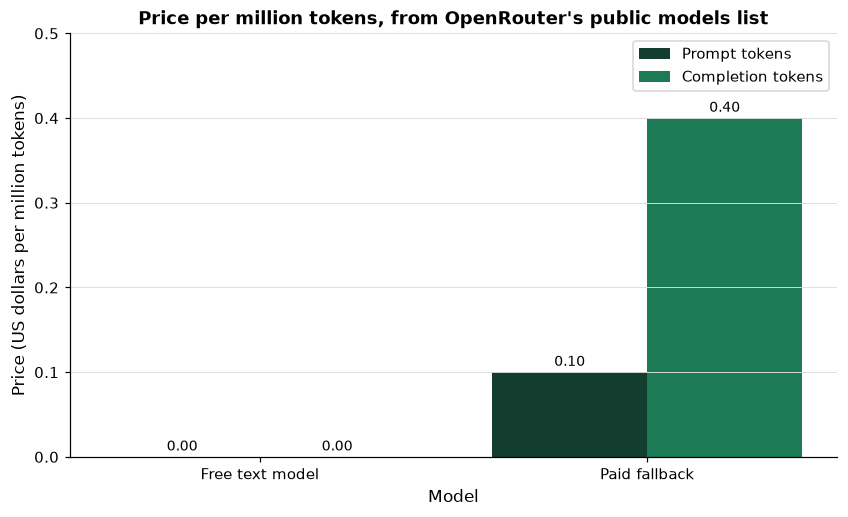

,Prompt tokens,Completion tokens
Model,,
Free text model,0.00,0.00
Paid fallback,0.10,0.40


In [18]:
# the two models' prices per million tokens, in US dollars, from the PRICES above
names = dict(zip(PRICES, ["Free text model", "Paid fallback"]))
per_million = pd.DataFrame({kind: {names[model]: float(price[kind]) * 1_000_000 for model, price in PRICES.items()}
                            for kind in ("prompt", "completion")})
per_million.columns = ["Prompt tokens", "Completion tokens"]
per_million.index.name = "Model"
ax = plotkit.bars(per_million, "Price per million tokens, from OpenRouter's public models list",
                  "Price (US dollars per million tokens)", fmt="{:.2f}")
ax.set_ylim(0, 0.5)
plt.show()
plotkit.styled(per_million, ["Prompt tokens", "Completion tokens"],
               "Price per million tokens in US dollars, read 2026-10-08", higher_is_better=False, fmt="{:.2f}")

* The free model's bars are zero: an id ending in `:free` costs nothing. The paid fallback charges 4 times as much for a token it returns as for one it reads. In Excel this is a clustered column chart of the same two columns.

## 11.3 The Key

An API key is a password for a program: anyone who has it can send requests that your account pays for. Course 3 kept the FRED key out of every notebook with `get_secret`, which looks in three places in order: the environment, Colab's Secrets panel, and the `.env` file in `my_bondmath`. Today's key goes in the same `.env` file, on a line of its own that starts `OPENROUTER_API_KEY=`, and `textkit` reads it with the same function, unchanged.

Q. Add the first part of today's code: the imports, the course's constants, and `llm_client`.

In [19]:
%%writefile -a textkit.py


import hashlib  # the request key, from day 11
import json  # saved responses, from day 11
from datetime import date  # the date a response was recorded, from day 11

import openai  # the client for OpenRouter and OpenAI, from day 11
from marketdata import get_secret  # Course 3's function, unchanged: the key from the environment, Colab, or .env

# where Course 3 keeps the student's .env file
ENV_FILE = Path.home() / "projects" / "my_bondmath" / ".env"
# one client, two providers: only the address and the name of the key change
PROVIDERS = {
    "openrouter": {"base_url": "https://openrouter.ai/api/v1", "key_name": "OPENROUTER_API_KEY"},
    "openai": {"base_url": "https://api.openai.com/v1", "key_name": "OPENAI_API_KEY"},
}
# the course's OpenRouter models (COURSE7_SPEC.md, open question 4, probed with a key 2026-10-07): the default text
# model (free), the model that reads page images, and the paid fallback. The free image model of the spec,
# google/gemma-4-31b-it:free, answered HTTP 429 to every probe request, so images go to the paid fallback.
MODELS |= {
    "text": "nvidia/nemotron-3-super-120b-a12b:free",
    "vision": "google/gemini-2.5-flash-lite",
    "fallback": "google/gemini-2.5-flash-lite",
}
# the default text model reasons before it answers unless told not to (probed: 265 reasoning tokens for one short
# answer); every request to it passes this as ask's extra_body
NO_REASONING = {"reasoning": {"enabled": False}}
# sent first in every request: extract and quote, say NOT IN TEXT, refuse anything that is not about the text
SYSTEM_PROMPT = (
    "You extract information from the document text in the user message. Quote the text exactly, character for "
    "character, and give the number of the section each quote comes from. Write every number exactly as the text "
    "writes it. If the text does not answer the question, reply NOT IN TEXT. If the user asks for an opinion, a "
    "grade, a comparison of quality, an ordering of securities or issuers, advice about trading, or a view about "
    "the future, reply exactly: REFUSED: this course asks only what the document says"
)
# waits in seconds before each retry of a request refused for too many requests (429) or a server error (5xx)
RETRY_WAITS = (2, 4, 8, 16, 32)


def llm_client(provider: str = "openrouter", env_file=ENV_FILE):
    """An openai.OpenAI client for OpenRouter or OpenAI, with the key read by Course 3's get_secret.

    Inputs: provider, a key of PROVIDERS; env_file, the .env file get_secret reads last (after the environment and
    Colab's Secrets panel).
    Output: a client with the provider's base_url and max_retries=0 (ask does its own retries), or None when no key
    is found, which puts a notebook in replay mode. The key itself is never returned or printed.
    Convention: typing client.api_key in a cell would display the key; never do it.
    Raises ValueError for an unknown provider.
    """
    if provider not in PROVIDERS:
        raise ValueError(f"provider must be one of {sorted(PROVIDERS)}, not {provider!r}")
    try:
        key = get_secret(PROVIDERS[provider]["key_name"], env_file)
    except RuntimeError:
        return None
    return openai.OpenAI(base_url=PROVIDERS[provider]["base_url"], api_key=key, max_retries=0)

Appending to textkit.py


* `ENV_FILE` is Course 3's place for the `.env` file, `my_bondmath\.env` under your home folder.
* `PROVIDERS` holds the two routes. Each has an address (`base_url`) and the name of the key it needs: OpenRouter's address and `OPENROUTER_API_KEY`, or OpenAI's and `OPENAI_API_KEY`. Section 11.12 switches routes with nothing else changed.
* `MODELS |= {...}` adds the three LLM ids to day 6's table of models.
* `NO_REASONING` and `SYSTEM_PROMPT` are for `ask`, in sections 11.4 and 11.8; `RETRY_WAITS` for 11.11.
* `llm_client` asks `get_secret` for the key. If none of the three places holds one, `get_secret` raises, and `llm_client` returns `None`: no client, so the notebook replays. If one is found, it returns a client from the `openai` package with the provider's address and the key inside it, and `max_retries=0`, because `ask` does its own retries. It never returns or prints the key.

**What never to do with the key.** Never print the client: typing `client.api_key` in a cell would show the whole key, and a saved notebook keeps what a cell showed. Never paste the key into a cell, a prompt, or a command line (a command line is saved in your shell's history). Keep it in `.env`, and keep `.env` out of Git.

Q. Reload `textkit`.

In [20]:
importlib.reload(textkit)
print(f"llm_client in textkit: {hasattr(textkit, 'llm_client')}; models: {textkit.MODELS['text']}, {textkit.MODELS['fallback']}")

llm_client in textkit: True; models: nvidia/nemotron-3-super-120b-a12b:free, google/gemini-2.5-flash-lite


Q. Before anything is sent: does Git ignore a `.env` file and the response cache in this folder?

In [21]:
# which line of which file ignores each path
!git -C "{work}" check-ignore -v .env cache/llm/

.gitignore:4:.env	.env
.gitignore:5:cache/	cache/llm/


* `git check-ignore -v` prints, for each path Git ignores, the file and line number of the rule that ignores it, then the path. Line 4 of `.gitignore`, `.env`, covers the key file; line 5, `cache/`, covers the response cache. A path Git would not ignore prints nothing, so an empty answer here would mean stop and fix `.gitignore` first.
* The two paths do not exist yet. Git checks the rules, not the folder, which is why this check can run before the first key or response arrives. Run the same line in `my_bondmath` (Bring It Home).

Q. Load the key, if there is one, and choose the mode.

In [22]:
# the key: from the environment, Colab's Secrets panel, or my_bondmath\.env; never printed
client = textkit.llm_client("openrouter", env_file=textkit.ENV_FILE)
LLM_MODE = "live" if client is not None else "replay"
# the saved responses: the course's in replay mode; a live run starts its own cache in the work folder
LLM_CACHE = work / "cache" / "llm"
if LLM_MODE == "replay":
    shutil.copytree(local_data / "course7_llm_responses" / "day11", LLM_CACHE)
print(f"OpenRouter key loaded: {client is not None}. Mode: {LLM_MODE}.")

OpenRouter key loaded: False. Mode: replay.


* This is the only cell of the notebook that touches the key, and it prints only whether one loaded. The course's saved notebook prints `False` and `replay`: it was built with no key in its environment.
* In **replay** mode the cell copies the course's saved responses, `data/course7_llm_responses/day11/`, into the work folder's `cache/llm/`, and every request today is answered from there. In **live** mode the cache starts empty and fills with your own responses; the course's folder is never written to.

## 11.4 `ask`, Docstring First

Every request in the course goes through one function, `ask`, so that four things happen every time: the system prompt goes first, the request gets a fingerprint, a saved response is used when there is one, and a refusal comes back as a plain message, never with the key in it.

Q. Add `request_key` and `ask`, with their tests.

In [23]:
%%writefile -a textkit.py


def request_key(provider: str, model: str, messages: list[dict], **params) -> str:
    """The SHA-256 of a request: its provider, model, messages, and parameters, never a header or a key.

    Inputs: provider; model; messages, the list sent; params, the request's parameters (temperature, seed,
    max_tokens, response_format, ...).
    Output: 64 hexadecimal characters. The same request always gives the same key, and a change to any word of a
    message or any parameter gives another.
    Convention: the canonical JSON of the request (keys sorted, no spaces, ASCII).
    """
    canonical = json.dumps({"provider": provider, "model": model, "messages": messages, "params": params},
                           sort_keys=True, separators=(",", ":"), ensure_ascii=True)
    return hashlib.sha256(canonical.encode("ascii")).hexdigest()


def _provider_of(client) -> str:
    """The provider a client sends to, from its base_url ("openrouter" when there is no client)."""
    if client is None:
        return "openrouter"
    return next((name for name, p in PROVIDERS.items() if str(client.base_url).rstrip("/") == p["base_url"]),
                "openrouter")


def ask(client, messages: list[dict], model: str, temperature: float = 0.0, seed: int = 42, max_tokens: int = 2000,
        response_format: dict | None = None, cache_dir=None, mode: str = "live",
        extra_body: dict | None = None) -> dict:
    """Send one request to a model, or replay its saved response.

    Inputs: client, from llm_client (None in replay mode); messages, the user messages (SYSTEM_PROMPT is put first
    unless the first message already is it); model, the model id; temperature, seed, max_tokens, response_format,
    and extra_body (provider settings such as {"reasoning": {...}}), sent as they are; cache_dir, the folder of
    saved responses, one JSON file per request named by request_key; mode, "live" or "replay".
    Output: {"content", "model" (as returned), "provider" (the provider behind the model, as OpenRouter returns it),
    "usage" (token counts), "finish_reason", "recorded" (the date the response was saved), "mode", "key"}.
    Convention: replay mode returns the saved response or raises LookupError naming the first 12 characters of the
    key, so a changed prompt cannot pass silently. Live mode returns the saved response if there is one; otherwise
    it sends the request, retries a 429 or a 5xx after 2, 4, 8, 16, 32 seconds (or the Retry-After header when the
    provider gives one), and saves the response. 400, 401, 402, 403, and 404 are never retried. Temperature 0 and a
    seed narrow the spread of answers; they do not promise the same text every time.
    Raises ValueError for an unknown mode or empty messages; RuntimeError("The provider refused the key: check
    OPENROUTER_API_KEY in your .env") on an authentication error, raised from None so no part of a key reaches the
    traceback; RuntimeError naming the HTTP status for any other refusal.
    """
    if mode not in ("live", "replay"):
        raise ValueError(f"mode must be 'live' or 'replay', not {mode!r}")
    if not messages:
        raise ValueError("messages is empty")
    system = {"role": "system", "content": SYSTEM_PROMPT}
    messages = list(messages) if messages[0] == system else [system] + list(messages)
    params = {"temperature": temperature, "seed": seed, "max_tokens": max_tokens, "response_format": response_format,
              "extra_body": extra_body}
    provider = _provider_of(client)
    key = request_key(provider, model, messages, **params)
    path = Path(cache_dir) / f"{key}.json" if cache_dir is not None else None
    if path is not None and path.is_file():
        saved = json.loads(path.read_text(encoding="utf-8"))
        return {name: saved[name] for name in ("content", "model", "provider", "usage", "finish_reason", "recorded")} \
            | {"mode": mode, "key": key}
    if mode == "replay" or client is None:
        raise LookupError(f"no saved response for request {key[:12]} in "
                          f"{Path(cache_dir).name if cache_dir is not None else 'no cache folder'}")
    request = {"model": model, "messages": messages, "temperature": temperature, "seed": seed,
               "max_tokens": max_tokens}
    if response_format is not None:
        request["response_format"] = response_format
    if extra_body is not None:
        request["extra_body"] = extra_body
    for attempt in range(len(RETRY_WAITS) + 1):
        try:
            response = client.chat.completions.create(**request)
            break
        except openai.AuthenticationError:
            raise RuntimeError("The provider refused the key: check OPENROUTER_API_KEY in your .env") from None
        except openai.APIStatusError as error:
            status = error.status_code
            if (status != 429 and status < 500) or attempt == len(RETRY_WAITS):
                raise RuntimeError(f"The provider refused the request with HTTP {status}") from None
            retry_after = error.response.headers.get("retry-after")
            _sleep(float(retry_after) if retry_after and retry_after.isdigit() else RETRY_WAITS[attempt])
    choice = response.choices[0]
    extra = response.model_extra or {}
    result = {"content": choice.message.content, "model": response.model, "provider": extra.get("provider"),
              "usage": response.usage.model_dump() if response.usage else None,
              "finish_reason": choice.finish_reason, "recorded": date.today().isoformat()}
    if path is not None:
        path.parent.mkdir(parents=True, exist_ok=True)
        record = {"request": {"provider": provider, "model": model, "messages": messages, "params": params}} | result
        path.write_text(json.dumps(record, sort_keys=True, indent=1, ensure_ascii=True) + "\n", encoding="utf-8",
                        newline="\n")
    return result | {"mode": mode, "key": key}

Appending to textkit.py


In [24]:
%%writefile -a test_textkit.py


import types

import httpx2  # the HTTP library the openai package uses: the fake errors below are built with it
import openai

FAKE_KEY = "sk-or-FAKEFAKEFAKE"


def http_error(kind, status: int, headers: dict | None = None):
    """An openai error as the client raises it, built without the network."""
    request = httpx2.Request("POST", "https://openrouter.ai/api/v1/chat/completions")
    response = httpx2.Response(status, request=request, headers=headers or {})
    return kind(f"HTTP {status}", response=response, body=None)


class FakeClient:
    """Stands in for openai.OpenAI: raises the given errors in turn, then returns one canned response."""

    def __init__(self, errors=(), content: str = "NOT IN TEXT"):
        self.errors, self.calls, self.api_key = list(errors), [], FAKE_KEY
        self.base_url = "https://openrouter.ai/api/v1/"
        self.chat = types.SimpleNamespace(completions=types.SimpleNamespace(create=self.create))
        self.content = content

    def create(self, **request):
        self.calls.append(request)
        if self.errors:
            raise self.errors.pop(0)
        message = types.SimpleNamespace(content=self.content)
        usage = types.SimpleNamespace(model_dump=lambda: {"prompt_tokens": 120, "completion_tokens": 4,
                                                          "total_tokens": 124})
        return types.SimpleNamespace(choices=[types.SimpleNamespace(message=message, finish_reason="stop")],
                                     model="test/model", usage=usage, model_extra={"provider": "TestProvider"})


@pytest.fixture
def no_wait(monkeypatch):
    waits = []
    monkeypatch.setattr(textkit, "_sleep", waits.append)
    return waits


USER = [{"role": "user", "content": "What is the interest rate on the Notes?"}]


def test_request_key_ignores_headers():
    key = textkit.request_key("openrouter", "test/model", USER, temperature=0, seed=42)
    assert len(key) == 64 and key == textkit.request_key("openrouter", "test/model", USER, seed=42, temperature=0)
    assert FAKE_KEY not in key


def test_request_key_changes_with_temperature():
    assert textkit.request_key("openrouter", "m", USER, temperature=0) != \
        textkit.request_key("openrouter", "m", USER, temperature=1)


def test_ask_replay_hit(tmp_path, no_wait):
    live = textkit.ask(FakeClient(content="4.750%"), USER, "test/model", cache_dir=tmp_path)
    replayed = textkit.ask(None, USER, "test/model", cache_dir=tmp_path, mode="replay")
    assert replayed["content"] == "4.750%" and replayed["mode"] == "replay" and replayed["key"] == live["key"]
    saved = (tmp_path / f"{live['key']}.json").read_text(encoding="utf-8")
    assert textkit.SYSTEM_PROMPT[:40] in saved and FAKE_KEY not in saved


def test_ask_replay_miss_raises(tmp_path):
    with pytest.raises(LookupError, match="no saved response"):
        textkit.ask(None, USER, "test/model", cache_dir=tmp_path, mode="replay")


def test_ask_retries_429_then_succeeds(tmp_path, no_wait):
    client = FakeClient(errors=[http_error(openai.RateLimitError, 429),
                                http_error(openai.RateLimitError, 429, {"retry-after": "7"})])
    result = textkit.ask(client, USER, "test/model", cache_dir=tmp_path)
    assert result["content"] == "NOT IN TEXT" and len(client.calls) == 3
    assert no_wait == [2, 7.0]
    assert client.calls[0]["messages"][0] == {"role": "system", "content": textkit.SYSTEM_PROMPT}


def test_ask_never_retries_401_and_hides_key(tmp_path, no_wait):
    client = FakeClient(errors=[http_error(openai.AuthenticationError, 401)])
    with pytest.raises(RuntimeError, match="refused the key") as caught:
        textkit.ask(client, USER, "test/model", cache_dir=tmp_path)
    assert len(client.calls) == 1 and no_wait == []
    assert caught.value.__cause__ is None and FAKE_KEY not in str(caught.value)

Appending to test_textkit.py


* **`request_key`** is the request's fingerprint: the SHA-256 hash (Course 3's `hashlib`) of the provider, the model, the messages, and the parameters, written as JSON with its keys sorted. The same request always gives the same 64 characters; one changed word or parameter gives others. Headers are not in it, so the key is not either.
* **`ask`** puts `SYSTEM_PROMPT` first unless it is there already. `SYSTEM_PROMPT` tells the model to quote the text exactly, to give the section, to answer `NOT IN TEXT` when the text does not say, and to refuse any request for an opinion, a grade, a comparison of quality, an ordering of issuers, trading advice, or a view about the future.
* Then the cache. The response to a request is saved as one JSON file named by its key in `cache_dir`. In **replay** mode `ask` returns the saved file or raises `LookupError`; in **live** mode it returns the saved file if there is one, and otherwise sends the request and saves the response. So a live notebook run twice sends each request once.
* A refusal: a 429 (too many requests) or a 5xx (the provider's trouble) is retried after 2, 4, 8, 16, then 32 seconds, or after the provider's `Retry-After` header. Any other refusal stops at once with `RuntimeError` naming the status. A refused key gives one fixed message, raised `from None`, so no part of the key can reach a traceback.
* The tests use `FakeClient`, a stand-in for the `openai` client that returns canned responses and raises canned errors, and a fake `_sleep`, so they never touch the network and never wait.

Q. Reload `textkit` and run the tests.

In [25]:
importlib.reload(textkit)
print(f"ask in textkit: {hasattr(textkit, 'ask')}; request_key: {hasattr(textkit, 'request_key')}")

ask in textkit: True; request_key: True


In [26]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_textkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.........................................................                [100%]
57 passed in 10.49s



* `57 passed`: the six new tests and day 10's 51.

## 11.5 The First Request

Q. Send the first request: the question about the target range, with the 2026-09-16 statement, to the free text model, reasoning switched off (section 11.8). Show the response and the LLM line.

In [27]:
# LLM response
first = textkit.ask(client, [message], textkit.MODELS["text"], cache_dir=LLM_CACHE, mode=LLM_MODE,
                    extra_body=textkit.NO_REASONING)
show(first)
print(f"finish_reason: {first['finish_reason']}; the provider that ran the model: {first['provider']}")
print(f"Model {first['model']}, temperature 0, seed 42; saved response recorded {first['recorded']}; " + ("replayed (no key loaded)." if first["mode"] == "replay" else "live."))

The Committee decided to raise the target range for the federal funds rate by 1/4 percentage point to 3-3/4 to 4 percent, in support of the Federal Reserve's dual mandate.
finish_reason: stop; the provider that ran the model: Nvidia
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


* The response quotes the statement's sentence. Under it, `finish_reason` `stop` in the saved response: the model finished, it did not run out of room. The provider behind the free model in the saved response is Nvidia: OpenRouter chose it.
* **The LLM line** closes every response cell of the course: the model id as the response names it, the temperature, the seed, the date the saved response was recorded, and whether this run replayed it or sent the request live.

Q. Is the range in the response the range the statement states? Check it with day 1's regular expression on both texts.

In [28]:
import re

# day 1's pattern for the target range, as the statements write it
NUMBER = r"(?:\d+[- ]\d+/\d+|\d+/\d+|\d+)"
RANGE = (rf"target range for the federal funds rate(?: by {NUMBER} percentage point,?)? (?:at|to|of) "
         rf"(?P<low>{NUMBER}) to (?P<high>{NUMBER}) percent")
in_statement = re.search(RANGE, textkit.normalize_text(row["text"]))
in_response = re.search(RANGE, textkit.normalize_text(first["content"]))
print(f"the statement states: {in_statement['low']} to {in_statement['high']} percent")
print("the saved response: " + (f"{in_response['low']} to {in_response['high']} percent" if in_response else "no range found"))
print("the same range: " + ("yes" if in_response and in_response.groups() == in_statement.groups() else "no"))

the statement states: 3-3/4 to 4 percent
the saved response: 3-3/4 to 4 percent
the same range: yes


* The same range, found by the same pattern in both texts. This is the habit of the rest of the course: a number a model returns is checked against the document by code that does not involve the model, here a regular expression written on day 1.
* The check passed on this saved response. On a live run it is run again on your response, and a response that paraphrased the sentence ("raised rates a quarter point") would fail it, visibly.

## 11.6 The System Prompt on One Paragraph of the Indenture

The system prompt asks for quotes and for `NOT IN TEXT` when the text does not answer. One paragraph of the Boyd indenture, Section 3.07(b), two questions: one it answers and one it does not.

Q. Find the paragraph in Section 3.07 and print it with its source line.

In [29]:
# source text: quoted as published
BOYD = ("Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed "
        "2021-06-08, accession 0001193125-21-185495")


def boyd_source(section=None):
    """The source line for an excerpt of the Boyd indenture."""
    return f"Source: {BOYD}" + (f", Section {section}." if section else ".")


indenture = Path("course7_indentures/boyd_2021.txt").read_text(encoding="utf-8")
sections = textkit.find_sections(indenture).set_index("number")
start, end = sections.loc["3.07", "start"], sections.loc["3.07", "end"]
paragraph = next(p for p in indenture[start:end].split(chr(10)) if p.startswith("(b) At any time prior to June 15, 2024"))
print(f"Section 3.07, {sections.loc['3.07', 'title']}: one paragraph of {len(paragraph)} characters, printed whole")
print(paragraph)
print(boyd_source("3.07"))

Section 3.07, Optional Redemption: one paragraph of 513 characters, printed whole
(b) At any time prior to June 15, 2024, the Company may on any one or more occasions redeem up to 40% of the aggregate principal amount of Notes at a redemption price of 104.750% of the principal amount thereof with the Net Cash Proceeds of one or more Equity Offerings, plus accrued and unpaid interest and Additional Interest, if any, to the redemption date, subject to the rights of Holders of such Notes on any relevant record date to receive interest due on the relevant interest payment date; provided that:
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 3.07.


* A paragraph of 513 characters, short enough to print whole. It names two numbers, a share of the Notes and a redemption price, and it does not state the interest rate the Notes pay.

Q. Ask both questions about the paragraph, and check every percentage in the first answer against the paragraph.

In [30]:
# LLM response
def paragraph_message(question):
    """One user message: the question, then the section number and the one paragraph."""
    return {"role": "user", "content": f"{question}\n\nSection 3.07 of the indenture, one paragraph:\n{paragraph}"}


answered = textkit.ask(client, [paragraph_message("What share of the Notes may the Company redeem with the proceeds of Equity Offerings, and at what redemption price?")], textkit.MODELS["text"], cache_dir=LLM_CACHE, mode=LLM_MODE, extra_body=textkit.NO_REASONING)
not_answered = textkit.ask(client, [paragraph_message("What is the interest rate on the Notes?")], textkit.MODELS["text"], cache_dir=LLM_CACHE, mode=LLM_MODE, extra_body=textkit.NO_REASONING)
print("Q: What share of the Notes may the Company redeem with the proceeds of Equity Offerings, and at what redemption price?")
show(answered)
print("Q: What is the interest rate on the Notes?")
show(not_answered)
percents = re.findall(r"\d+(?:\.\d+)?%", textkit.normalize_text(answered["content"]))
print(f"percentages in the first answer: {percents}; each in the paragraph: {'yes' if all(p in paragraph for p in percents) else 'no'}")
for response in (answered, not_answered):
    print(f"Model {response['model']}, temperature 0, seed 42; saved response recorded {response['recorded']}; " + ("replayed (no key loaded)." if response["mode"] == "replay" else "live."))

Q: What share of the Notes may the Company redeem with the proceeds of Equity Offerings, and at what redemption price?
The Company may redeem up to 40% of the aggregate principal amount of Notes with the proceeds of Equity Offerings at a redemption price of 104.750% of the principal amount thereof, plus accrued and unpaid interest and Additional Interest, if any, to the redemption date. This is stated in Section 3.07(b) of the indenture.
Q: What is the interest rate on the Notes?
NOT IN TEXT
percentages in the first answer: ['40%', '104.750%']; each in the paragraph: yes
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


* The first answer in the saved response holds 2 percentages, 40%, 104.750%, each found in the paragraph.
* The second question comes back `NOT IN TEXT` in the saved response: the paragraph names a redemption price of 104.750% and never the interest rate, and the system prompt asked for exactly this answer when the text does not say. The interest rate is in the indenture, in its title, 4.750%, but not in the paragraph the request carried: the model answers from the text it is sent.

## 11.7 Tokens and Cost

Q. Add `usage_cost`, with its test and the test of `llm_client`.

In [31]:
%%writefile -a textkit.py


def usage_cost(usage: dict, pricing: dict) -> float:
    """The cost of one request in US dollars, from its token counts and the model's prices per token.

    Inputs: usage, the response's usage (prompt_tokens, completion_tokens); pricing, {"prompt": price per prompt
    token, "completion": price per completion token} in US dollars, as OpenRouter's public models list publishes
    them (as text, for example "0.0000001").
    Output: prompt_tokens x prompt price + completion_tokens x completion price, in US dollars; 0.0 for a free
    model, whose prices are "0".
    Convention: the tokens billed are the ones usage reports, counted by the model's own tokenizer.
    Raises ValueError if a count or a price is negative or missing.
    """
    try:
        prompt, completion = int(usage["prompt_tokens"]), int(usage["completion_tokens"])
        prompt_price, completion_price = float(pricing["prompt"]), float(pricing["completion"])
    except (KeyError, TypeError) as error:
        raise ValueError(f"usage needs prompt_tokens and completion_tokens, pricing prompt and completion: {error}") \
            from None
    if min(prompt, completion, prompt_price, completion_price) < 0:
        raise ValueError("token counts and prices must not be negative")
    return prompt * prompt_price + completion * completion_price

Appending to textkit.py


In [32]:
%%writefile -a test_textkit.py


def test_usage_cost_hand():
    usage = {"prompt_tokens": 1_000_000, "completion_tokens": 100_000}
    assert textkit.usage_cost(usage, {"prompt": "0.0000001", "completion": "0.0000004"}) == pytest.approx(0.14)
    assert textkit.usage_cost(usage, {"prompt": "0", "completion": "0"}) == 0.0
    with pytest.raises(ValueError):
        textkit.usage_cost({"prompt_tokens": 1}, {"prompt": "0", "completion": "0"})


def test_llm_client_none_without_key(tmp_path, monkeypatch):
    monkeypatch.delenv("OPENROUTER_API_KEY", raising=False)
    assert textkit.llm_client("openrouter", env_file=tmp_path / ".env") is None
    (tmp_path / ".env").write_text(f"OPENROUTER_API_KEY={FAKE_KEY}\n", encoding="utf-8")
    client = textkit.llm_client("openrouter", env_file=tmp_path / ".env")
    assert str(client.base_url).startswith("https://openrouter.ai/api/v1")

Appending to test_textkit.py


* `usage_cost` multiplies the prompt tokens by the prompt price and the completion tokens by the completion price, and adds the two: US dollars. It takes the prices as text, as the list publishes them, and turns them into numbers itself.
* `test_llm_client_none_without_key` writes a `.env` with a fake key into pytest's own temporary folder: with no key `llm_client` returns `None`, and with the fake one it returns a client pointed at OpenRouter. Nothing is sent.

Q. Reload `textkit` and run all of today's tests.

In [33]:
importlib.reload(textkit)
print(f"usage_cost in textkit: {hasattr(textkit, 'usage_cost')}")

usage_cost in textkit: True


In [34]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_textkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...........................................................              [100%]
59 passed in 9.77s



* `59 passed`: today's four functions, tested.

Q. What did the first request use, and what did it cost on the free model? What would the same token counts cost at the fallback's list price?

In [35]:
usage = first["usage"]
print(f"prompt tokens {usage['prompt_tokens']:,}; completion tokens {usage['completion_tokens']:,}; total {usage['total_tokens']:,}")
free = textkit.usage_cost(usage, PRICES[textkit.MODELS["text"]])
at_fallback = textkit.usage_cost(usage, PRICES[textkit.MODELS["fallback"]])
print(f"on the free model: US${free:.7f}; the cost OpenRouter reported in the response: US${usage['cost']:.7f}")
print(f"the same token counts at the fallback's list price: US${at_fallback:.7f}, or US${at_fallback * 1_000:.4f} for 1,000 such requests")

prompt tokens 323; completion tokens 43; total 366
on the free model: US$0.0000000; the cost OpenRouter reported in the response: US$0.0000000
the same token counts at the fallback's list price: US$0.0000495, or US$0.0495 for 1,000 such requests


* In the saved response: 323 prompt tokens and 43 completion tokens. The prompt is most of it: the system prompt, the question, and the statement's 843 characters. The answer is one sentence.
* On the free model the cost is 0.0, and OpenRouter's own `cost` field in the response says the same. At the fallback's price the same counts would come to US$0.0000495. (The fallback's tokenizer would count the text a little differently; the next cell sends the request to the fallback itself.)
* `usage` holds more than the counts: OpenRouter adds `cost` and `cost_details` without being asked, and `completion_tokens_details` holds the reasoning tokens of section 11.8.

Q. Send the same request to the paid fallback. Does `usage_cost` equal the cost OpenRouter reports?

In [36]:
# LLM response
fallback_response = textkit.ask(client, [message], textkit.MODELS["fallback"], cache_dir=LLM_CACHE, mode=LLM_MODE)
show(fallback_response)
fallback_usage = fallback_response["usage"]
computed = textkit.usage_cost(fallback_usage, PRICES[textkit.MODELS["fallback"]])
print(f"prompt tokens {fallback_usage['prompt_tokens']:,}; completion tokens {fallback_usage['completion_tokens']:,}")
print(f"usage_cost: US${computed:.7f}; reported by OpenRouter: US${fallback_usage['cost']:.7f}; "
      f"equal within 1e-12: {'yes' if abs(computed - fallback_usage['cost']) < 1e-12 else 'no'}")
print(f"Model {fallback_response['model']}, temperature 0, seed 42; saved response recorded {fallback_response['recorded']}; " + ("replayed (no key loaded)." if fallback_response["mode"] == "replay" else "live."))

"The Committee decided to raise the target range for the federal funds rate by 1/4 percentage point to 3-3/4 to 4 percent" (Section 1)
prompt tokens 308; completion tokens 38
usage_cost: US$0.0000460; reported by OpenRouter: US$0.0000460; equal within 1e-12: yes
Model google/gemini-2.5-flash-lite, temperature 0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


* In the saved response the fallback counted 308 prompt tokens where the free model counted 323: two tokenizers, one text. Its cost by `usage_cost` is US$0.0000460, equal to the cost OpenRouter reported. That is the price of one request on the paid route: a hundred such requests come to US$0.0046000.
* The fallback's answer holds the same range, 3-3/4 to 4 percent. It also ends with "(Section 1)": the system prompt asks for the number of the section each quote comes from, and a statement has no sections, so the response gave one the document does not have. Day 12 checks every cited section against the indenture's own table of sections.

Q. Put the four requests so far side by side: the tokens each used, and what the same counts cost at the fallback's list price.

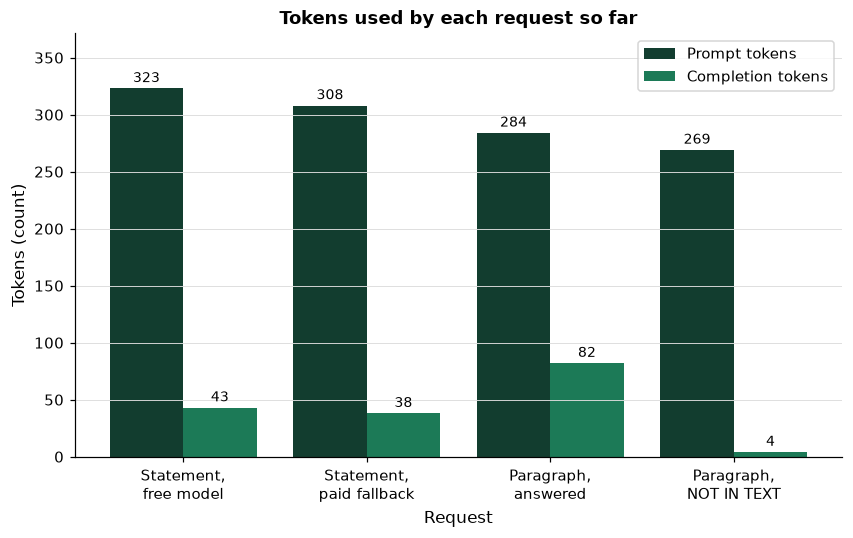

,Prompt tokens,Completion tokens,Cost at the fallback's list price (US dollars)
Request,,,
"Statement, free model",323,43,0.0000495
"Statement, paid fallback",308,38,0.0000460
"Paragraph, answered",284,82,0.0000612
"Paragraph, NOT IN TEXT",269,4,0.0000285


In [37]:
# the four saved responses so far, and the tokens each used
sent = {"Statement,\nfree model": first, "Statement,\npaid fallback": fallback_response,
        "Paragraph,\nanswered": answered, "Paragraph,\nNOT IN TEXT": not_answered}
fallback_prices = PRICES[textkit.MODELS["fallback"]]
requests_used = pd.DataFrame({
    "Prompt tokens": [r["usage"]["prompt_tokens"] for r in sent.values()],
    "Completion tokens": [r["usage"]["completion_tokens"] for r in sent.values()],
    "Cost at the fallback's list price (US dollars)": [textkit.usage_cost(r["usage"], fallback_prices) for r in sent.values()],
}, index=list(sent))
requests_used.index.name = "Request"
token_columns = ["Prompt tokens", "Completion tokens"]
ax = plotkit.bars(requests_used[token_columns], "Tokens used by each request so far", "Tokens (count)", fmt="{:,.0f}")
ax.set_ylim(0, requests_used[token_columns].to_numpy().max() * 1.15)
plt.show()
plotkit.styled(requests_used.set_axis([name.replace(chr(10), " ") for name in requests_used.index]).rename_axis("Request"), [],
               "Tokens and cost at the fallback's list price, one row per saved response", fmt="{:.7f}")

* The prompt is most of every request, 269 to 323 tokens against completions of 4 to 82: the system prompt and the document go in whole. A statement costs more to send than one paragraph, and the answer `NOT IN TEXT` is the shortest completion, 4 tokens in the saved response.
* The cost column prices every row at the fallback's list price, the free model's rows too, so that the four are on one scale. A table like this, kept for a run, is how a desk sees what a tool costs to run. In Excel the bars are a clustered column chart of the first two columns.

## 11.8 Reasoning Switched Off

The default text model **reasons** before it answers unless told not to: it writes working text that is not returned to you, then the answer. Those reasoning tokens are counted among the completion tokens, and completion tokens are what a paid model bills. `textkit.NO_REASONING`, `{"reasoning": {"enabled": false}}`, is OpenRouter's setting that switches it off, sent through `ask`'s `extra_body` (settings a provider accepts beyond the standard ones). Every request to the text model in the course passes it.

Q. Send the first request again with reasoning left at the model's default, and compare.

In [38]:
# LLM response
reasoned = textkit.ask(client, [message], textkit.MODELS["text"], cache_dir=LLM_CACHE, mode=LLM_MODE)
show(reasoned)


def reasoning_tokens(usage):
    """The reasoning tokens among a response's completion tokens (0 when the field is missing)."""
    return (usage.get("completion_tokens_details") or {}).get("reasoning_tokens") or 0


for label, response in (("reasoning off", first), ("reasoning on", reasoned)):
    u = response["usage"]
    print(f"{label:13} completion tokens {u['completion_tokens']:4}, of which reasoning {reasoning_tokens(u):4}; "
          f"at the fallback's price US${textkit.usage_cost(u, PRICES[textkit.MODELS['fallback']]):.7f}")
print(f"the same answer text: {'yes' if textkit.normalize_text(reasoned['content']) == textkit.normalize_text(first['content']) else 'no'}")
print(f"Model {reasoned['model']}, temperature 0, seed 42; saved response recorded {reasoned['recorded']}; " + ("replayed (no key loaded)." if reasoned["mode"] == "replay" else "live."))

"The Committee decided to raise the target range for the federal funds rate by 1/4 percentage point to 3-3/4 to 4 percent," - Section 1
reasoning off completion tokens   43, of which reasoning    0; at the fallback's price US$0.0000495
reasoning on  completion tokens 1261, of which reasoning 1222; at the fallback's price US$0.0005367
the same answer text: no
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


* In the saved responses: 43 completion tokens with reasoning off, 1,261 with it on, of which 1,222 were reasoning. The answer text differs in its wording around the quote; both quote the same sentence of the statement.
* Why off: for a task whose answer is in the text, the course asks the model to find and quote, and reasoning adds tokens that are never shown and that a paid model bills. The course's foundation also found, with the reasoning effort set to "low", a response of several hundred reasoning tokens that answered `NOT IN TEXT` to this same question: more tokens did not give a closer answer here. Switching it off is a setting, chosen for this task; a task that asks the model to work through steps may want it on.

Q. Draw the two runs: how the completion splits into answer and reasoning tokens, and what each would cost at the fallback's list price.

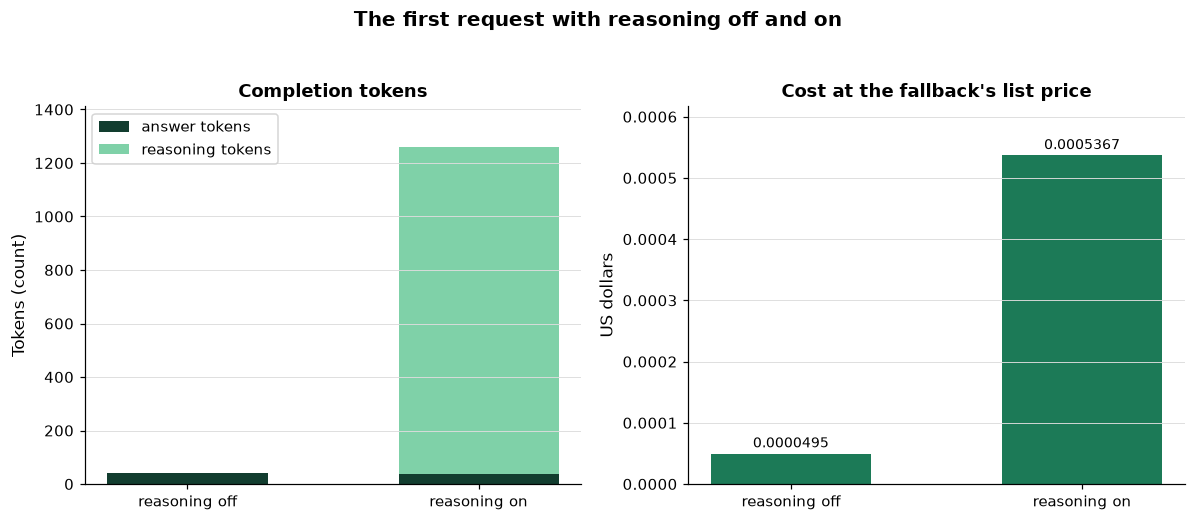

,Answer tokens,Reasoning tokens,Cost at the fallback's list price (US dollars)
Setting,,,
reasoning off,43,0,0.0000495
reasoning on,39,"1,222",0.0005367


In [39]:
# the first request with reasoning off and on: answer and reasoning tokens, and the cost at the fallback's price
runs = {"reasoning off": first, "reasoning on": reasoned}
reasoning_runs = pd.DataFrame({
    "Answer tokens": [r["usage"]["completion_tokens"] - reasoning_tokens(r["usage"]) for r in runs.values()],
    "Reasoning tokens": [reasoning_tokens(r["usage"]) for r in runs.values()],
    "Cost at the fallback's list price (US dollars)": [textkit.usage_cost(r["usage"], PRICES[textkit.MODELS["fallback"]]) for r in runs.values()],
}, index=list(runs))
reasoning_runs.index.name = "Setting"
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
positions = np.arange(len(reasoning_runs))
left.bar(positions, reasoning_runs["Answer tokens"], 0.55, color=plotkit.GREEN_DARK, label="answer tokens")
left.bar(positions, reasoning_runs["Reasoning tokens"], 0.55, bottom=reasoning_runs["Answer tokens"],
         color=plotkit.GREEN_LIGHT, label="reasoning tokens")
left.set_xticks(positions, labels=list(reasoning_runs.index))
left.set_ylim(0, (reasoning_runs["Answer tokens"] + reasoning_runs["Reasoning tokens"]).max() * 1.12)
left.set_title("Completion tokens")
left.set_ylabel("Tokens (count)")
left.grid(axis="x", visible=False)
left.legend(loc="upper left")
cost_column = "Cost at the fallback's list price (US dollars)"
drawn = right.bar(positions, reasoning_runs[cost_column], 0.55, color=plotkit.GREEN)
right.bar_label(drawn, fmt="{:.7f}", fontsize=9, padding=2)
right.set_xticks(positions, labels=list(reasoning_runs.index))
right.set_ylim(0, reasoning_runs[cost_column].max() * 1.15)
right.set_title("Cost at the fallback's list price")
right.set_ylabel("US dollars")
right.grid(axis="x", visible=False)
fig.suptitle("The first request with reasoning off and on", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()
plotkit.styled(reasoning_runs, [cost_column], "Completion tokens and cost at the fallback's list price, reasoning off against on",
               higher_is_better=False, fmt="{:.7f}")

* In the saved responses the answer is 43 tokens with reasoning off and 39 with it on; the other 1,222 tokens of the second run are reasoning, never shown and billed as completion. At the fallback's list price the second run would cost US$0.0005367 against US$0.0000495 for the first. The left bars stack the two token kinds; the table marks the setting with the smaller cost.

## 11.9 Temperature and Seed

**How it works.** A model writes its answer one token at a time. At each step it gives every possible next token a probability, and one is drawn. **Temperature** scales those probabilities before the draw: at 0 the most likely token is taken nearly every time; at 1 the draw follows the model's own probabilities, so a less likely token is chosen now and then and the text can go another way. Day 7 (section 7.7) did this arithmetic by hand on eight committed scores, and section 11.13 draws its sibling, `top_p`, which cuts the unlikely tail. A **seed** asks the provider to make the same draws on a rerun. It is a request, not a promise: the provider may route the request to another machine, or batch it with other requests, and the arithmetic can differ in its last digits. You control the temperature, the seed, and the length; what comes out is a text that narrows toward one answer as the temperature falls and does not repeat exactly.

Q. Send one open request, a one-sentence summary of what the statement says about inflation, at temperature 0 and at temperature 1, each with seeds 42, 43, and 44. Put the six responses side by side.

In [40]:
# LLM response
SUMMARY = "In one sentence, summarise what this statement says about inflation."
rows = []
for temperature in (0.0, 1.0):
    for seed in (42, 43, 44):
        r = textkit.ask(client, [statement_message(SUMMARY, row)], textkit.MODELS["text"], temperature=temperature,
                        seed=seed, cache_dir=LLM_CACHE, mode=LLM_MODE, extra_body=textkit.NO_REASONING)
        rows.append({"temperature": temperature, "seed": seed, "tokens": r["usage"]["completion_tokens"],
                     "text": textkit.normalize_text(r["content"]), "response": r})
for x in rows:
    print(f"temperature {x['temperature']:g}, seed {x['seed']}, {x['tokens']} tokens: {x['text']}")
for temperature in (0.0, 1.0):
    texts = {x["text"] for x in rows if x["temperature"] == temperature}
    print(f"temperature {temperature:g}: {len(texts)} distinct text(s) among 3 saved responses")
print(f"all six: {len({x['text'] for x in rows})} distinct text(s)")
for x in rows:
    r, temperature, seed = x["response"], x["temperature"], x["seed"]
    print(f"Model {r['model']}, temperature {temperature:g}, seed {seed}; saved response recorded {r['recorded']}; " + ("replayed (no key loaded)." if r["mode"] == "replay" else "live."))

temperature 0, seed 42, 35 tokens: Inflation remains elevated, and today's policy action will support a timelier return to the Committee's 2 percent goal, with the Committee committed to delivering price stability.
temperature 0, seed 43, 35 tokens: Inflation remains elevated, and today's policy action will support a timelier return to the Committee's 2 percent goal, with the Committee committed to delivering price stability.
temperature 0, seed 44, 31 tokens: Inflation remains elevated, and the Committee's policy action is intended to support a timelier return to its 2 percent goal and deliver price stability.
temperature 1, seed 42, 31 tokens: Inflation remains elevated, and the rate increase aims to support a timelier return to the Committee's 2 percent inflation goal and achieve price stability.
temperature 1, seed 43, 30 tokens: Inflation remains elevated, but the Committee's policy action will support a timelier return to its 2 percent inflation goal and deliver price stability.


* In the saved responses: 2 distinct texts among the three at temperature 0, and 3 among the three at temperature 1; 5 in all six.
* At temperature 0, seeds 42 and 43 returned the same text and seed 44 another. At temperature 1, each of the three seeds returned its own text. Every one of the six starts with the statement's own words, "Inflation remains elevated", and then puts the statement's next sentences in its own words. These are six saved responses to one request; a live run of yours can show a different spread. The course's foundation sent a shorter question five times at each temperature and got one text five times at both.
* **What to rely on.** Temperature 0 and a fixed seed narrow the spread of answers; they do not promise identical text. That is why the course checks every answer against the document with code (11.5), saves every response (11.10), and builds its notebooks from the saved responses. `ask` sends temperature 0 and seed 42 unless told otherwise.

Q. Draw the six saved responses: their length by seed, and how many distinct texts each temperature gave.

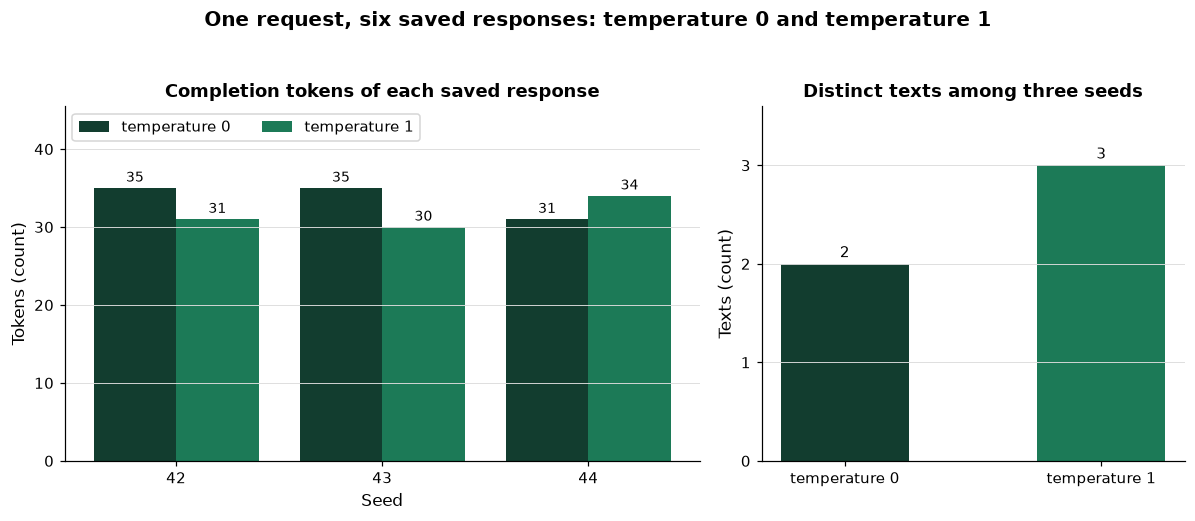

,Distinct texts (of 3),Mean completion tokens
Setting,,
temperature 0,2,33.7
temperature 1,3,31.7


In [41]:
# the six saved responses: completion tokens by seed, and distinct texts by temperature (rows came from the cell above)
tokens_by_seed = pd.DataFrame({f"temperature {t:g}": {x["seed"]: x["tokens"] for x in rows if x["temperature"] == t}
                               for t in (0.0, 1.0)})
tokens_by_seed.index.name = "Seed"
by_temperature = pd.DataFrame({
    "Distinct texts (of 3)": [len({x["text"] for x in rows if x["temperature"] == t}) for t in (0.0, 1.0)],
    "Mean completion tokens": [float(np.mean([x["tokens"] for x in rows if x["temperature"] == t])) for t in (0.0, 1.0)],
}, index=["temperature 0", "temperature 1"])
by_temperature.index.name = "Setting"
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [3, 2]})
plotkit.bars(tokens_by_seed, "Completion tokens of each saved response", "Tokens (count)", ax=left, fmt="{:,.0f}")
left.set_ylim(0, tokens_by_seed.to_numpy().max() * 1.3)
left.legend(loc="upper left", ncols=2)
drawn = right.bar(by_temperature.index, by_temperature["Distinct texts (of 3)"], 0.5, color=[plotkit.GREEN_DARK, plotkit.GREEN])
right.bar_label(drawn, fmt="{:.0f}", fontsize=10, padding=2)
right.set_ylim(0, 3.6)
right.set_yticks([0, 1, 2, 3])
right.set_title("Distinct texts among three seeds")
right.set_ylabel("Texts (count)")
right.grid(axis="x", visible=False)
fig.suptitle("One request, six saved responses: temperature 0 and temperature 1", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()
plotkit.styled(by_temperature, [], "Distinct texts and mean completion tokens by temperature, three seeds each", fmt="{:.1f}")

* Left: the completion tokens of each saved response, 35, 35, 31 at temperature 0 (seeds 42, 43, 44) and 31, 30, 34 at temperature 1. Right: 2 distinct texts among the three at temperature 0 and 3 among the three at temperature 1. The count is of texts, not of words: two responses that differ by one word are two texts.
* Six responses to one request show how the spread looked in this run, not how wide it can be. That is the case for checking every answer against the document rather than for trusting a setting.

## 11.10 The Cache and Replay

Q. What does the cache hold for the first request? Find its file by the request's key and read its fields.

In [42]:
import json

saved_file = LLM_CACHE / f"{first['key']}.json"
record = json.loads(saved_file.read_text(encoding="utf-8"))
print(f"the request's key: {first['key'][:12]}... (64 characters); its file is in cache/llm: {saved_file.exists()}")
print(f"fields of the saved record: {sorted(record)}")
print(f"what the request held: {sorted(record['request'])}; its parameters: {record['request']['params']}")
print(f"messages in the request: {[m['role'] for m in record['request']['messages']]}")
print(f"saved responses in cache/llm: {len(list(LLM_CACHE.glob('*.json')))}")

the request's key: 0e28d64e7792... (64 characters); its file is in cache/llm: True
fields of the saved record: ['content', 'finish_reason', 'model', 'provider', 'recorded', 'request', 'usage']
what the request held: ['messages', 'model', 'params', 'provider']; its parameters: {'extra_body': {'reasoning': {'enabled': False}}, 'max_tokens': 2000, 'response_format': None, 'seed': 42, 'temperature': 0.0}
messages in the request: ['system', 'user']
saved responses in cache/llm: 14


* The record holds the request as sent (provider, model, messages with the system prompt first, parameters) and what came back (`content`, `model`, `provider`, `usage`, `finish_reason`) with the date it was `recorded`. No header and no key: neither is part of the request's fingerprint or of the file.
* In replay mode the cache holds the course's 14 saved responses for today: the 12 requests of this notebook and the 2 of the exercises.

Q. Ask the first question again, exactly, and then with two words added. What does `ask` do with each, in replay mode?

In [43]:
# LLM response
again = textkit.ask(client, [message], textkit.MODELS["text"], cache_dir=LLM_CACHE, mode=LLM_MODE, extra_body=textkit.NO_REASONING)
print(f"the same request: the same key {again['key'] == first['key']}, the same text {again['content'] == first['content']}; from the cache, nothing sent")
changed = statement_message(QUESTION + " Quote it.", row)
try:
    # replay mode never sends: a request with no saved response stops with LookupError
    textkit.ask(client, [changed], textkit.MODELS["text"], cache_dir=LLM_CACHE, mode="replay", extra_body=textkit.NO_REASONING)
except LookupError as error:
    print(f"two words added, in replay mode: LookupError: {error}")
print(f"Model {again['model']}, temperature 0, seed 42; saved response recorded {again['recorded']}; " + ("replayed (no key loaded)." if again["mode"] == "replay" else "live."))

the same request: the same key True, the same text True; from the cache, nothing sent
two words added, in replay mode: LookupError: no saved response for request dd2ca18e0b82 in llm
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


* The same request has the same key, so `ask` returned the saved response; in live mode too it would send nothing.
* Two words more give another key, `dd2ca18e0b82`, with no saved response, so replay stops and names the key's first 12 characters. A changed prompt can never pass silently with an old answer. In live mode it would be sent, and saved.

## 11.11 When a Request Fails

Requests fail, and `ask` turns each failure into a plain message. The course never makes one fail on purpose against the real service: that would spend real limits. A **fake client** stands in, written here as in the tests: it raises the error a real one raises, built from the `openai` package's own error classes, and records what it was sent.

What each code means:

* **400** (bad request): the request itself is wrong, for example a model id that does not exist. The course's foundation sent one, `no-such-provider/no-such-model:free`, and got 400.
* **401** (unauthorized): the key is wrong, revoked, or missing from the header.
* **402** (payment required): a paid model, and the account has no credit left.
* **429** (too many requests): this key, this model's free tier, or the provider behind it is at its limit. A per-minute limit clears after a wait, which is why `ask` waits and tries again. A free model's daily cap returns the same code, and waiting minutes does not clear it.

Q. Build the fake client, then send it a wrong model id, a refused key, and a request with no credit.

In [44]:
import types

import httpx2
import openai


def http_error(kind, status, headers=None):
    """An error of the openai package, as the client raises it, built without the network."""
    request = httpx2.Request("POST", "https://openrouter.ai/api/v1/chat/completions")
    return kind(f"HTTP {status}", response=httpx2.Response(status, request=request, headers=headers or {}), body=None)


class FakeClient:
    """Stands in for the openai client: raises the given errors in turn, then returns one canned response."""

    def __init__(self, errors=()):
        self.errors, self.sent = list(errors), []
        self.base_url = "https://openrouter.ai/api/v1/"
        self.chat = types.SimpleNamespace(completions=types.SimpleNamespace(create=self.create))

    def create(self, **request):
        self.sent.append(request)
        if self.errors:
            raise self.errors.pop(0)
        message = types.SimpleNamespace(content="NOT IN TEXT")
        usage = types.SimpleNamespace(model_dump=lambda: {"prompt_tokens": 120, "completion_tokens": 4})
        return types.SimpleNamespace(choices=[types.SimpleNamespace(message=message, finish_reason="stop")],
                                     model="fake/model", usage=usage, model_extra={"provider": "Fake"})


cases = [("a wrong model id", openai.BadRequestError, 400, "no-such-provider/no-such-model:free"),
         ("a refused key", openai.AuthenticationError, 401, textkit.MODELS["text"]),
         ("no credit on a paid model", openai.APIStatusError, 402, textkit.MODELS["fallback"])]
for label, kind, status, model in cases:
    fake = FakeClient([http_error(kind, status)])
    try:
        textkit.ask(fake, [message], model, mode="live")
    except RuntimeError as error:
        print(f"{label} (HTTP {status}): {error}")
        print(f"    requests sent: {len(fake.sent)}; an earlier error attached: {'yes' if error.__cause__ is not None else 'no'}")

a wrong model id (HTTP 400): The provider refused the request with HTTP 400
    requests sent: 1; an earlier error attached: no
a refused key (HTTP 401): The provider refused the key: check OPENROUTER_API_KEY in your .env
    requests sent: 1; an earlier error attached: no
no credit on a paid model (HTTP 402): The provider refused the request with HTTP 402
    requests sent: 1; an earlier error attached: no


* Each failure is one request and one plain message; none is retried, because sending the same wrong request again cannot succeed. The key's message is fixed text, and no earlier error is attached to it, so a traceback could not show the key even in part. (It names `OPENROUTER_API_KEY` on either route; on the OpenAI route the key to check is `OPENAI_API_KEY`.)
* The errors are caught and printed here so the notebook keeps running. In your own code let them stop the program: a request that failed has no answer to use.
* `cache_dir` was left out, so nothing was saved, and the fake client sent nothing anywhere.

Q. And a 429? Make the fake client refuse twice, the second time with a `Retry-After` of 7 seconds, then answer. Then make it refuse six times in a row, as a daily cap would. Replace `ask`'s pause with a list, so nothing waits.

In [45]:
waits = []
real_sleep = textkit._sleep
textkit._sleep = waits.append
try:
    busy = FakeClient([http_error(openai.RateLimitError, 429), http_error(openai.RateLimitError, 429, {"retry-after": "7"})])
    answer = textkit.ask(busy, [message], textkit.MODELS["text"], mode="live")
    print(f"429, 429, then an answer: {len(busy.sent)} requests; waits {waits}; the fake answer {answer['content']!r}")
    waits.clear()
    capped = FakeClient([http_error(openai.RateLimitError, 429) for _ in range(6)])
    try:
        textkit.ask(capped, [message], textkit.MODELS["text"], mode="live")
    except RuntimeError as error:
        print(f"429 six times: {len(capped.sent)} requests; waits {waits}, {sum(waits)} seconds in all; then: {error}")
finally:
    # put the real pause back, whatever happened
    textkit._sleep = real_sleep

429, 429, then an answer: 3 requests; waits [2, 7.0]; the fake answer 'NOT IN TEXT'
429 six times: 6 requests; waits [2, 4, 8, 16, 32], 62 seconds in all; then: The provider refused the request with HTTP 429


* The first case waited 2 seconds, then the 7 the provider asked for, then got its answer: three requests. The second waited 2, 4, 8, 16, and 32 seconds, a minute in all, then gave up with the status. Against a daily cap, that minute is wasted: waiting a minute does not clear it. The way out is the paid fallback, or the next day.

Q. Draw the pauses the daily-cap case produced (the list `waits` still holds them), with the total waited so far.

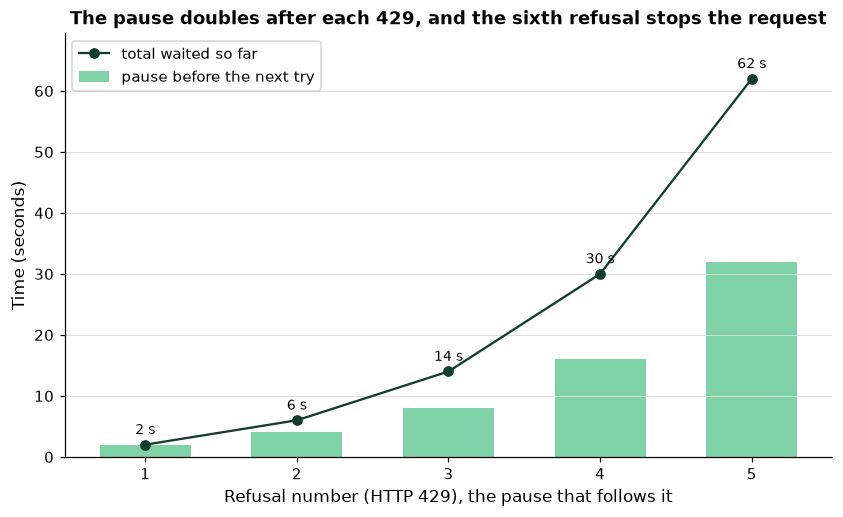

In [46]:
# the pauses the capped fake client produced, and the running total
pauses = pd.Series(waits, index=range(1, len(waits) + 1))
total_waited = pauses.cumsum()
fig, ax = plt.subplots()
ax.bar(pauses.index, pauses, 0.6, color=plotkit.GREEN_LIGHT, label="pause before the next try")
ax.plot(pauses.index, total_waited, color=plotkit.GREEN_DARK, marker="o", label="total waited so far")
for refusal, total in total_waited.items():
    ax.annotate(f"{total} s", (refusal, total), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9)
ax.set_xlabel("Refusal number (HTTP 429), the pause that follows it")
ax.set_ylabel("Time (seconds)")
ax.set_title("The pause doubles after each 429, and the sixth refusal stops the request")
ax.set_ylim(0, total_waited.max() * 1.12)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
plt.show()

* Five pauses of 2, 4, 8, 16, 32 seconds, each double the one before, then the sixth refusal stops the request: 62 seconds waited in all, and no answer. A per-minute limit clears inside that time; a daily cap does not.

## 11.12 The OpenAI Route

OpenRouter speaks OpenAI's request format, so moving to OpenAI's own API is the other entry of `PROVIDERS`: OpenAI's address and the key name `OPENAI_API_KEY`, in the same `.env` file. The request, `ask`, the cache, and the checks stay as they are. Only the model id changes, to one OpenAI serves: the course used `gpt-4.1-mini`.

Q. Send the first request through the OpenAI route. Without an OpenAI key, replay the course's saved response.

In [47]:
# LLM response
openai_client = textkit.llm_client("openai", env_file=textkit.ENV_FILE)
if openai_client is not None:
    route, route_mode, route_cache = openai_client, "live", LLM_CACHE
else:
    # no OpenAI key here: replay the course's saved response. ask reads the provider from the client's address, so a
    # stand-in that carries only OpenAI's address finds the response saved for that route; it sends nothing
    route = types.SimpleNamespace(base_url=textkit.PROVIDERS["openai"]["base_url"])
    route_mode, route_cache = "replay", local_data / "course7_llm_responses" / "day11"
openai_response = textkit.ask(route, [message], "gpt-4.1-mini", cache_dir=route_cache, mode=route_mode)
show(openai_response)
found = re.search(RANGE, textkit.normalize_text(openai_response["content"]))
print(f"the provider field: {openai_response['provider']}; the range by day 1's pattern: " + (f"{found['low']} to {found['high']} percent" if found else "not found"))
print(f"Model {openai_response['model']}, temperature 0, seed 42; saved response recorded {openai_response['recorded']}; " + ("replayed (no key loaded)." if openai_response["mode"] == "replay" else "live."))

The statement says about the target range for the federal funds rate:
"The Committee decided to raise the target range for the federal funds rate by 1/4 percentage point to 3-3/4 to 4 percent, in support of the Federal Reserve's dual mandate." (Section 1)
the provider field: None; the range by day 1's pattern: 3-3/4 to 4 percent
Model gpt-4.1-mini-2025-04-14, temperature 0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


* The model id in the LLM line is the one OpenAI returned, `gpt-4.1-mini-2025-04-14` in the saved response: OpenAI answers with the dated version it ran. `provider` is `None` because that field is OpenRouter's, not OpenAI's. Like the fallback's, the response cites "(Section 1)", a section the statement does not have.
* The same range, found by the same pattern. The request's key differs from the OpenRouter one, because the provider is part of the fingerprint: one response per route.
* A request on this route goes to your OpenAI account, under OpenAI's own prices and limits, which are not in the OpenRouter list above and which this course did not read.

## 11.13 Every Setting of the Chat Request

**How it works.** Sections 11.5 to 11.12 sent one request shape and changed a few of its settings. A request to a chat model holds the messages and the model, and then a long list of optional settings that shape how the answer is drawn and delivered. The settings that shape the draw are `temperature` (which rescales the chances of the next token), `top_p` (which cuts the unlikely tail of those chances before the draw), and `seed` (which asks for the same draws on a rerun). `max_tokens` stops the answer at a length, and `response_format` asks for its form. You control only the ones you send; the package leaves out the rest and the provider uses its own defaults. What comes out is the response of section 11.1.

Q. List every setting the installed `openai` package accepts for a chat request, its default, and which of them the course sends.

In [48]:
# source text: quoted as published
# the setting names are the installed package's own

import inspect

import openai
from openai.resources.chat.completions import Completions

# every setting of the request, read from the installed openai package; the course sends the ones ask has a keyword for
chat = {name: p for name, p in inspect.signature(Completions.create).parameters.items() if name != "self"}
ask_keywords = inspect.signature(textkit.ask).parameters
used_text = {"messages": "set in every request", "model": "set in every request", "extra_body": "reasoning off (11.8)"}


def shown_default(p):
    # the package marks a setting it leaves out of the request with its own Omit or NotGiven object
    if p.default is inspect.Parameter.empty:
        return "required"
    if type(p.default).__name__ in ("Omit", "NotGiven"):
        return "not sent"
    return repr(p.default)


def course_uses(name):
    if name in used_text:
        return used_text[name]
    return repr(ask_keywords[name].default) if name in ask_keywords else "not sent"


# group, what it controls, what changing it does, and whether to tune it
guide = {'messages': ('the request', 'The conversation so far: the system message first, then the user message with the question and the text.', 'The model sees nothing else.', 'always'), 'model': ('the request', 'Which model runs.', 'Another id is another model, price, and limit (11.2).', 'always'), 'temperature': ('randomness', 'How much the draw of each next token may vary: 0 takes the likeliest token nearly every time.', 'Higher gives more varied text (11.9, and day 7 by hand).', 'tune first'), 'top_p': ('randomness', 'Keeps only the likeliest tokens whose chances add up to this share, then draws among them.', 'Lower cuts the unlikely tail (the chart below).', 'tune first'), 'seed': ('randomness', 'Asks the provider for the same draws on a rerun.', 'A request, not a promise (11.9).', 'always set'), 'n': ('randomness', 'How many answers to return for one request.', 'Each answer is billed.', 'not used'), 'max_tokens': ('length', 'The most completion tokens the response may hold; at the limit the response stops mid-sentence with finish_reason length.', 'Raise it for long answers; lower it to cap cost (exercise 2).', 'tune first'), 'max_completion_tokens': ('length', 'The newer name for the same limit; it also counts reasoning tokens.', "Used by OpenAI's reasoning models in place of max_tokens.", 'not used'), 'stop': ('length', 'Text at which the model stops writing.', 'A stop string cuts the answer there.', 'not used'), 'response_format': ('shape of the answer', 'Asks for JSON, or JSON that follows a schema.', 'Day 12 uses it so a covenant comes back as fields.', 'from day 12'), 'frequency_penalty': ('repetition', 'Lowers the chance of a token for each time it has already appeared.', 'Higher repeats less.', 'not used'), 'presence_penalty': ('repetition', 'Lowers the chance of a token that has appeared at all.', 'Higher moves to new words.', 'not used'), 'logit_bias': ('repetition', "Raises or lowers chosen tokens' chances by token id.", 'Used to ban or favour a token.', 'not used'), 'logprobs': ('probabilities', 'Returns the log chance of each token written.', 'Shows how sure the model was of each word.', 'not used'), 'top_logprobs': ('probabilities', 'How many of the next-likeliest tokens to return with each one.', 'Needs logprobs on.', 'not used'), 'reasoning_effort': ('reasoning', 'How much a reasoning model works before answering.', 'Lower uses fewer tokens (the course switches reasoning off instead, 11.8).', 'not used'), 'verbosity': ('reasoning', 'How long the answer text is asked to be.', 'Lower is shorter.', 'not used'), 'tools': ('tools', 'Functions the model may ask the caller to run.', 'Course 8 builds on this.', 'Course 8'), 'tool_choice': ('tools', 'Whether the model must, may, or may not use a tool.', 'Course 8 sets it.', 'Course 8'), 'parallel_tool_calls': ('tools', 'Whether the model may ask for several tools at once.', 'Course 8 sets it.', 'Course 8'), 'functions': ('tools', 'The older form of tools.', 'Replaced by tools.', 'not used'), 'function_call': ('tools', 'The older form of tool_choice.', 'Replaced by tool_choice.', 'not used'), 'audio': ('other outputs', 'Settings for a spoken answer.', 'Only for audio models.', 'not used'), 'modalities': ('other outputs', 'Which kinds of output the model may return: text, audio.', 'Text is the default.', 'not used'), 'prediction': ('other outputs', 'A guess at the output, for faster edits of a known text.', 'Only some models take it.', 'not used'), 'web_search_options': ('other outputs', 'Settings for a search the model runs before it answers.', 'The course answers from the document it is given, never from a search.', 'not used'), 'stream': ('delivery', 'Returns the answer in pieces as it is written.', 'The course waits for the whole response and saves it.', 'not used'), 'stream_options': ('delivery', 'Settings for the pieces of a streamed answer.', 'Used only with stream.', 'not used'), 'service_tier': ('delivery', 'Which processing tier of the provider serves the request.', 'A provider option, with its own price.', 'not used'), 'metadata': ('account', "Labels attached to the request on the provider's side.", "For the provider's own records.", 'not used'), 'store': ('account', 'Whether the provider stores the response.', 'A provider option.', 'not used'), 'user': ('account', 'An identifier for the end user.', "For the provider's abuse monitoring.", 'not used'), 'safety_identifier': ('account', 'A newer identifier for the end user.', "For the provider's abuse monitoring.", 'not used'), 'moderation': ('account', 'An OpenAI option for checking content.', 'The course does not use it.', 'not used'), 'prompt_cache_key': ('account', "A key that groups requests for the provider's own prompt cache.", "Separate from the course's cache of saved responses (11.10).", 'not used'), 'prompt_cache_options': ('account', "Options for the provider's own prompt cache.", "Separate from the course's cache (11.10).", 'not used'), 'prompt_cache_retention': ('account', 'How long the provider keeps its prompt cache.', "Separate from the course's cache (11.10).", 'not used'), 'extra_headers': ('the transport', 'Extra HTTP headers for this one call.', 'The course sends none: a header could carry a key (11.3).', 'not used'), 'extra_query': ('the transport', 'Extra parameters in the address.', 'The course sends none.', 'not used'), 'extra_body': ('the transport', "Extra fields in the body that the standard settings do not cover; a provider's own settings go here.", 'The course sends reasoning off through it (11.8).', 'always'), 'timeout': ('the transport', 'How long to wait for the provider.', "The client's default is kept.", 'not used')}
# the table is built from the installed package, so a setting this table does not describe stops the notebook
assert set(guide) == set(chat), "the installed openai package has settings this table does not describe"
settings = pd.DataFrame([{"group": guide[name][0], "setting": name, "default": shown_default(chat[name]),
                          "the course sends": course_uses(name), "what it controls": guide[name][1],
                          "changing it": guide[name][2], "tune?": guide[name][3]} for name in chat])


def shade_course(row):
    # the settings the course sends are shaded
    return ["background-color: #d6efe2; font-weight: bold" if row["the course sends"] != "not sent" else "" for _ in row]


display(plotkit.styled(settings, [], "The chat request: every setting, its default, and what the course sends")
        .hide(axis="index").apply(shade_course, axis=1).set_properties(**{"text-align": "left", "white-space": "normal"}))
sent = [name for name in chat if course_uses(name) != "not sent"]
print(f"settings of the chat request: {len(chat)}; the course sends {len(sent)} of them: {', '.join(sent)}")

group,setting,default,the course sends,what it controls,changing it,tune?
the request,messages,required,set in every request,"The conversation so far: the system message first, then the user message with the question and the text.",The model sees nothing else.,always
the request,model,required,set in every request,Which model runs.,"Another id is another model, price, and limit (11.2).",always
other outputs,audio,not sent,not sent,Settings for a spoken answer.,Only for audio models.,not used
repetition,frequency_penalty,not sent,not sent,Lowers the chance of a token for each time it has already appeared.,Higher repeats less.,not used
tools,function_call,not sent,not sent,The older form of tool_choice.,Replaced by tool_choice.,not used
tools,functions,not sent,not sent,The older form of tools.,Replaced by tools.,not used
repetition,logit_bias,not sent,not sent,Raises or lowers chosen tokens' chances by token id.,Used to ban or favour a token.,not used
probabilities,logprobs,not sent,not sent,Returns the log chance of each token written.,Shows how sure the model was of each word.,not used
length,max_completion_tokens,not sent,not sent,The newer name for the same limit; it also counts reasoning tokens.,Used by OpenAI's reasoning models in place of max_tokens.,not used
length,max_tokens,not sent,2000,The most completion tokens the response may hold; at the limit the response stops mid-sentence with finish_reason length.,Raise it for long answers; lower it to cap cost (exercise 2).,tune first


settings of the chat request: 41; the course sends 7 of them: messages, model, max_tokens, response_format, seed, temperature, extra_body


* 41 settings in groups, read from `openai` 3.26.0. The shaded rows are the 7 that `ask` sends: the messages, the model, and five settings (`max_tokens` 2000, `response_format`, `seed`, `temperature`, `extra_body`); the "course sends" column shows the value `ask` uses unless a cell changes it. The course sends no `top_p`: it changes the temperature and the seed only, so the effect of one setting at a time is easy to see.
* OpenRouter's public models list (read 2026-10-08, https://openrouter.ai/api/v1/models) names 8 of these settings for the free text model: `max_tokens`, `reasoning_effort`, `response_format`, `seed`, `temperature`, `tool_choice`, `tools`, `top_p`. A setting the model's entry does not list may be ignored by the provider, so a setting that works on one model is not promised to work on another.
* The table's text is the course's, written about the names; the package's own help is the place to read a setting's exact rules. The package marks a setting it leaves out with its own placeholder, shown here as "not sent".

Q. What does `top_p` do? Draw it by hand on one invented set of next-token chances for "Inflation remains ...", at three values.

the chances add up to 1.00
top_p 1.0: keeps 7 of 7 tokens (elevated, high, sticky, above, firm, moderate, subdued); the largest chance is now 0.460
top_p 0.9: keeps 5 of 7 tokens (elevated, high, sticky, above, firm); the largest chance is now 0.489
top_p 0.7: keeps 3 of 7 tokens (elevated, high, sticky); the largest chance is now 0.575


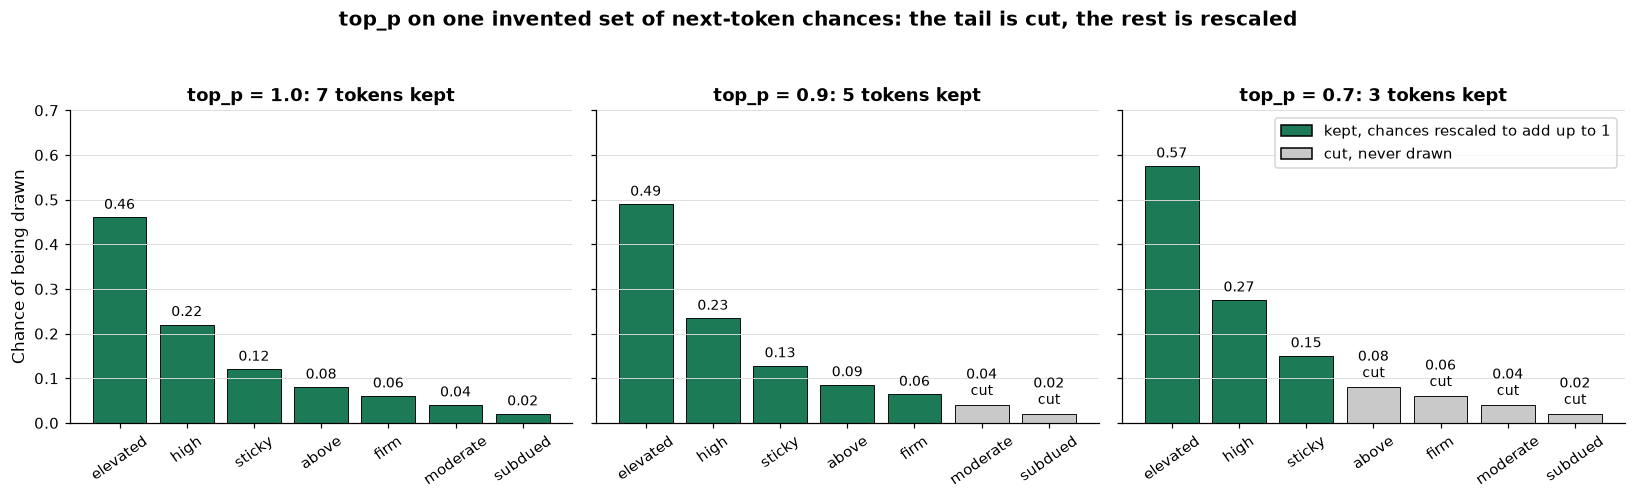

In [49]:
# an invented next-token distribution for "Inflation remains ...", at temperature 1: seven tokens and their chances
chances = pd.Series({"elevated": 0.46, "high": 0.22, "sticky": 0.12, "above": 0.08, "firm": 0.06, "moderate": 0.04, "subdued": 0.02})
print(f"the chances add up to {chances.sum():.2f}")


def nucleus(chances, top_p):
    """The chances after top_p: keep the likeliest tokens until their chances reach top_p, then rescale to add up to 1."""
    ordered = chances.sort_values(ascending=False)
    # a token is kept while the tokens before it still add up to less than top_p
    before = ordered.cumsum() - ordered
    kept = ordered[before < top_p]
    return kept / kept.sum()


fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, top_p in zip(axes, [1.0, 0.9, 0.7]):
    kept = nucleus(chances, top_p)
    print(f"top_p {top_p}: keeps {len(kept)} of {len(chances)} tokens ({', '.join(kept.index)}); the largest chance is now {kept.max():.3f}")
    # kept tokens at their rescaled chance in green; cut tokens at their original chance in grey
    heights = [kept[t] if t in kept.index else chances[t] for t in chances.index]
    colours = [plotkit.GREEN if t in kept.index else "#c9c9c9" for t in chances.index]
    bars = ax.bar(chances.index, heights, color=colours, edgecolor="black", linewidth=0.6)
    for bar, token in zip(bars, chances.index):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.012, f"{bar.get_height():.2f}" + ("" if token in kept.index else "\ncut"),
                ha="center", va="bottom", fontsize=9)
    ax.set_title(f"top_p = {top_p}: {len(kept)} tokens kept")
    ax.set_ylim(0, 0.7)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Chance of being drawn")
axes[2].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=plotkit.GREEN, ec="black"), plt.Rectangle((0, 0), 1, 1, color="#c9c9c9", ec="black")],
               labels=["kept, chances rescaled to add up to 1", "cut, never drawn"], loc="upper right")
fig.suptitle("top_p on one invented set of next-token chances: the tail is cut, the rest is rescaled", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

* Sort the tokens by chance, keep them until their chances add up to `top_p`, cut the rest, and rescale the kept chances to add up to 1. top_p 1.0: keeps 7 of 7 tokens (elevated, high, sticky, above, firm, moderate, subdued); the largest chance is now 0.460. top_p 0.9: keeps 5 of 7 tokens (elevated, high, sticky, above, firm); the largest chance is now 0.489. top_p 0.7: keeps 3 of 7 tokens (elevated, high, sticky); the largest chance is now 0.575.
* How to read the panels: at 1.0 nothing is cut. Lowering `top_p` cuts the tail first, so rare words stop being drawn, and the chance of the likeliest word grows because the kept chances are rescaled. `temperature` and `top_p` both narrow the draw, by different means: temperature reshapes every chance (day 7 did it by hand on eight committed scores), top_p removes the tail. The chances are invented to draw the idea and are not a model's output.
* The course leaves `top_p` unsent, so a provider uses its own default. Which to tune is a choice of the request: send one of the two and keep the other where it is.

Q. The first question went out four ways in this notebook: reasoning off, reasoning on, the paid fallback, and OpenAI. Put the four saved answers in one table.

In [50]:
# the first request four ways: the free model with reasoning off and on, the paid fallback, and OpenAI
runs = {"free model, reasoning off": ("the course's setting", first), "free model, reasoning on": ("reasoning left at the default", reasoned),
        "paid fallback": ("another model", fallback_response), "OpenAI": ("another provider", openai_response)}
stated = re.search(RANGE, textkit.normalize_text(row["text"])).groups()
rows = []
for label, (changed, response) in runs.items():
    answer = textkit.normalize_text(response["content"])
    found = re.search(RANGE, answer)
    rows.append({"run": label, "what changed": changed, "completion tokens": response["usage"]["completion_tokens"],
                 "range as the statement states it": "yes" if found and found.groups() == stated else "no",
                 "cites a section": "yes" if "Section" in answer else "no", "answer": answer})
side_by_side = pd.DataFrame(rows)
display(plotkit.styled(side_by_side, [], "One question, four runs: the saved answers side by side")
        .hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))
print(f"{(side_by_side['range as the statement states it'] == 'yes').sum()} of {len(side_by_side)} runs give the statement's range; "
      f"{(side_by_side['cites a section'] == 'yes').sum()} cite a section, and a statement has none")

run,what changed,completion tokens,range as the statement states it,cites a section,answer
"free model, reasoning off",the course's setting,43,yes,no,"The Committee decided to raise the target range for the federal funds rate by 1/4 percentage point to 3-3/4 to 4 percent, in support of the Federal Reserve's dual mandate."
"free model, reasoning on",reasoning left at the default,"1,261",yes,yes,"""The Committee decided to raise the target range for the federal funds rate by 1/4 percentage point to 3-3/4 to 4 percent,"" - Section 1"
paid fallback,another model,38,yes,yes,"""The Committee decided to raise the target range for the federal funds rate by 1/4 percentage point to 3-3/4 to 4 percent"" (Section 1)"
OpenAI,another provider,61,yes,yes,"The statement says about the target range for the federal funds rate: ""The Committee decided to raise the target range for the federal funds rate by 1/4 percentage point to 3-3/4 to 4 percent, in support of the Federal Reserve's dual mandate."" (Section 1)"


4 of 4 runs give the statement's range; 3 cite a section, and a statement has none


* 4 of 4 saved answers give the statement's range, by day 1's pattern. 3 of 4 cite a section, and a statement has none. The completion tokens are 43, 1261, 38, 61: the one with reasoning on is long because of the hidden reasoning (11.8), not the answer.
* Read the table row by row for what one change moved. The answer with the course's setting (reasoning off) cites no section; each of the other three adds "Section 1", a section the statement does not have. A tidy answer is not a checked one: the check against the document (11.5) is what tells them apart, and day 12 checks every cited section against the indenture's own list.

## Excel Side by Side

Excel has no worksheet function this course uses that sends text to an LLM, so the request, the key, and the cache have no Excel counterpart here. The cost does. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-08) on the fallback's saved response: B2 and B3 hold its prompt and completion tokens, C2 and C3 the fallback's prices per token.

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| Cost of one request | `usage_cost(usage, prices)` | `=B2*C2+B3*C3` | 0.000046 |
| The same, as one function | the same | `=SUMPRODUCT(B2:B3,C2:C3)` | 0.000046 |
| Price per million tokens | `float(price) * 1_000_000` | `=C2*1000000` | 0.1 |
| The cost with 7 decimals | `f"{cost:.7f}"` | `=TEXT(D1,"0.0000000")` | 0.0000460 |
| Prices pasted as text, multiplied | `float("0.0000001")` | `=B2*E2+B3*E3` | 0.000046 |
| Prices pasted as text, in SUMPRODUCT | | `=SUMPRODUCT(B2:B3,E2:E3)` | 0 |

**The cost by formula.** Type the two token counts in B2 and B3 and the two prices in C2 and C3, then `=B2*C2+B3*C3`: each count times its price, added, which is `usage_cost` line for line. `=SUMPRODUCT(B2:B3,C2:C3)` does the same in one function. In the General format Excel showed the cost as `0.000046`; `=TEXT(D1,"0.0000000")` shows it as 0.0000460, seven decimals as the notebook prints it, and `=C2*1000000` turns a price per token into a price per million tokens, the unit section 11.2 printed.

**The trap: prices pasted as text.** OpenRouter's list writes each price as text, "0.0000001". Pasted into a cell formatted as text, it stays text. The multiplication `=B2*E2+B3*E3` (on prices in E2 and E3, typed as text) still returned 0.000046: Excel's `*` converts text that looks like a number. `=SUMPRODUCT(B2:B3,E2:E3)` returned 0: SUMPRODUCT treats text cells as zero, with no message. `usage_cost` converts the text with `float` first, so it cannot make that mistake silently.

Q. Do Excel's results equal Python's?

In [51]:
# Excel's results, from the course's Excel check, beside Python's on the fallback's saved response
prices = PRICES[textkit.MODELS["fallback"]]
excel = {"cost by formula": 4.599999999999999e-05, "cost by SUMPRODUCT": 4.599999999999999e-05,
         "cost with prices as text": 4.599999999999999e-05, "SUMPRODUCT with prices as text": 0.0}
python = {"cost by formula": textkit.usage_cost(fallback_usage, prices),
          "cost by SUMPRODUCT": textkit.usage_cost(fallback_usage, prices),
          "cost with prices as text": textkit.usage_cost(fallback_usage, prices),
          "SUMPRODUCT with prices as text": textkit.usage_cost(fallback_usage, prices)}
for job in excel:
    print(f"{job:32} Excel {excel[job]:.10f}  Python {python[job]:.10f}  equal within 1e-15: {'yes' if abs(excel[job] - python[job]) < 1e-15 else 'no'}")

cost by formula                  Excel 0.0000460000  Python 0.0000460000  equal within 1e-15: yes
cost by SUMPRODUCT               Excel 0.0000460000  Python 0.0000460000  equal within 1e-15: yes
cost with prices as text         Excel 0.0000460000  Python 0.0000460000  equal within 1e-15: yes
SUMPRODUCT with prices as text   Excel 0.0000000000  Python 0.0000460000  equal within 1e-15: no


* Three rows equal and one not: SUMPRODUCT on prices pasted as text returned 0, the trap above. With prices pasted as text, multiply the cells one by one, as `=B2*E2+B3*E3` does, or type the prices as numbers.

## Save the Day with Git

Today's Git step started before the first request: `git check-ignore -v .env cache/llm/` in section 11.3. Now the commit, and the proof that the cache stayed out of it.

Q. Commit today's two textkit files, and show the commit.

In [52]:
# the data files are copies and stay untracked
!git -C "{work}" add textkit.py test_textkit.py
!git -C "{work}" commit -q -m "Add llm_client, request_key, ask, usage_cost, 59 tests"
!git -C "{work}" show --stat --format=%s HEAD

Add llm_client, request_key, ask, usage_cost, 59 tests

 test_textkit.py | 102 ++++++++++++++++++++++++++++++++++
 textkit.py      | 169 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 2 files changed, 271 insertions(+)


* The commit holds today's four functions and eight tests, added after day 10's code.

Q. The work folder now has a `cache/llm/` folder full of responses. What does Git see?

In [53]:
# --ignored lists the ignored paths too, marked !!
!git -C "{work}" status --short --ignored

?? course7_fomc_statements.csv
?? course7_indentures/
?? plotkit.py
!! __pycache__/
!! cache/


* `??` marks the data copies and `plotkit.py` (Course 4's chart helpers, which the setup cell writes every day and no commit of the course's own code includes), untracked. `!!` marks what `.gitignore` keeps out: `cache/`, with every saved response in it, and Python's `__pycache__/`. A response file holds no key, but it is the course's output, not code, and a student's live cache grows with every new request; it stays out of Git.

## Bring It Home

Add today's four functions to your own `my_bondmath` folder, put your key where `get_secret` finds it, and send one request from a script of your own. Open a PowerShell terminal in VS Code, with the course environment active.

**Step 1.** Go to the folder and check that day 10's tests pass.

```powershell
Set-Location "$HOME\projects\my_bondmath"
python -m pytest -q test_textkit.py
```

The last line says `51 passed`.

**Step 2.** Paste the code of today's three `%%writefile -a textkit.py` cells (sections 11.3, 11.4, and 11.7), without their first lines, at the end of `textkit.py`, and the two `%%writefile -a test_textkit.py` cells at the end of `test_textkit.py`. Save both. Run the tests, which send nothing:

```powershell
python -m pytest -q test_textkit.py
```

The last line says `59 passed`.

**Step 3.** The key. Make an account at openrouter.ai, create a key on its Keys page, and copy it. Open `.env` in VS Code (Course 3 made it; it already holds `FRED_API_KEY`) and add one line, with your key after the `=` and nothing else:

```
OPENROUTER_API_KEY=
```

Save the file. Then check, before anything is sent, that Git ignores it:

```powershell
git check-ignore -v .env
```

It prints the line of `.gitignore` that ignores `.env`. If it prints nothing, stop and add `.env` to `.gitignore` first.

**Step 4.** Commit the code (the key stays out, because `.env` is ignored):

```powershell
git add textkit.py test_textkit.py
git commit -m "Add llm_client, request_key, ask, usage_cost, 59 tests"
git status --short
```

**Step 5.** One real request. Make a file `first_request.py` in the folder:

```python
from pathlib import Path

import textkit

client = textkit.llm_client("openrouter")
print(f"key loaded: {client is not None}")
message = {"role": "user", "content": "What is 1/4 percentage point in basis points? Answer with the number."}
response = textkit.ask(client, [message], textkit.MODELS["text"], cache_dir=Path("cache/llm"),
                       extra_body=textkit.NO_REASONING)
print(response["content"])
print(response["usage"]["prompt_tokens"], "prompt tokens;", response["usage"]["completion_tokens"], "completion tokens")
```

```powershell
python first_request.py
python first_request.py
```

The first run sends one request; the second finds the saved response in `cache/llm/` and sends nothing. How long a request takes depends on the model, the provider OpenRouter chooses, and your connection; no cell of the course prints a time. Each live request counts toward the free model's daily cap.

**In Colab**, put the key in the Secrets panel (the key icon on the left) under the name `OPENROUTER_API_KEY` and give the notebook access to it: `get_secret` looks there second. Download `textkit.py` and `test_textkit.py` from the work folder under `/tmp` in the file browser.

## You Can Now

* Say what a request to an LLM holds (a model id, messages with roles, parameters) and what comes back (text, the model id, `usage`, `finish_reason`).
* Keep a key in `.env`, read it with `get_secret`, check Git ignores it before the first request, and never print it.
* Send a request through `ask`, with the system prompt first and every response saved under its key.
* Check a number in a response against the document with code that does not involve the model.
* Read the token counts and price them with `usage_cost`, on a free model and at a paid model's list price.
* Say why the course switches reasoning off, and why temperature 0 and a seed narrow the spread of answers without promising the same text.
* Replay a notebook from saved responses, and see a changed prompt stop with `LookupError`.
* Read 400, 401, 402, and 429 as plain messages, and say which ones waiting can fix.
* Switch to OpenAI by changing the address and the key name.
* Price a request in Excel, and avoid SUMPRODUCT on prices pasted as text.

Next, day 12: the anatomy of an indenture, and the first covenant extracted into a schema and checked against the text.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell. The solutions notebook's requests were saved by the course, so it replays without a key.

Q. Run the next cell first. It loads the statements, defines `statement_source`, `statement_message`, `show`, day 1's `RANGE` pattern, `PRICES`, and `QUESTION`, and defines `check`, a small function that marks your answers.

In [54]:
import contextlib
import io
import json
import re
import types

fomc = pd.read_csv("course7_fomc_statements.csv")

def statement_source(row):
    """The source line for one statement of the file."""
    return (f"Source: FOMC post-meeting statement of {row['date']}, Board of Governors of the Federal Reserve "
            f"System, {row['url']}")


def statement_message(question, row):
    """One user message: the question, then the statement's date and its text, normalized."""
    return {"role": "user",
            "content": f"{question}\n\nFOMC statement of {row['date']}:\n{textkit.normalize_text(row['text'])}"}


def show(response):
    """Print a response's text, normalized as every text in this course (a dash the model writes prints as -)."""
    print(textkit.normalize_text(response["content"]))


# day 1's pattern for the target range, as the statements write it
NUMBER = r"(?:\d+[- ]\d+/\d+|\d+/\d+|\d+)"
RANGE = (rf"target range for the federal funds rate(?: by {NUMBER} percentage point,?)? (?:at|to|of) "
         rf"(?P<low>{NUMBER}) to (?P<high>{NUMBER}) percent")
# prices per token in US dollars, as OpenRouter's public models list publishes them (text), read 2026-10-08
PRICES = {"nvidia/nemotron-3-super-120b-a12b:free": {"prompt": "0", "completion": "0"},
          "google/gemini-2.5-flash-lite": {"prompt": "0.0000001", "completion": "0.0000004"}}
QUESTION = "What does this statement say about the target range for the federal funds rate?"
row = fomc[fomc["date"] == "2026-09-16"].iloc[0]
print(f"statements: {len(fomc)}; LLM mode: {LLM_MODE}; saved responses in cache/llm: {len(list(LLM_CACHE.glob('*.json')))}")

def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

statements: 226; LLM mode: replay; saved responses in cache/llm: 14


### Exercise 1

Q. Ask `QUESTION` about the statement of 2008-12-16, on the free text model with reasoning off, through `ask` with `cache_dir=LLM_CACHE` and `mode=LLM_MODE`. Find the range in the response with `RANGE`, and store `(low, high)` as written in **ex1_range** (or `None` if the pattern finds none). Is it the range the statement states?

In [55]:
ex1_range = ...

In [56]:
check("Exercise 1 the range in the response", ex1_range, ('0', '1/4'))

Exercise 1 the range in the response: not attempted yet


### Exercise 2

Q. Ask `QUESTION` about the 2026-09-16 statement again, with `max_tokens=20`. Store the response's `finish_reason` in **ex2_finish**. What does it say, and what happened to the answer?

In [57]:
ex2_finish = ...

In [58]:
check("Exercise 2 the finish_reason", ex2_finish, 'length')

Exercise 2 the finish_reason: not attempted yet


### Exercise 3

Q. Add a function to your module. `cost_table(responses, pricing)` returns a DataFrame with one row per response: `model`, `prompt_tokens`, `completion_tokens`, and `cost_usd` (`usage_cost` at the given prices), and raises `ValueError` for an empty list. Write the docstring first. Then add `test_cost_table` with two hand-made responses. Run pytest, reload the module, and price the two responses of exercises 1 and 2 at the fallback's prices; store the total cost as text with 8 decimals, `f"{total:.8f}"`, in **ex3_total**.

Write the function in the cell that starts with `%%writefile -a textkit.py` and the test in the one that starts with `%%writefile -a test_textkit.py`, and run each of those cells once.

In [59]:
%%writefile -a textkit.py


# Exercise 3: write cost_table(responses, pricing) below this line

Appending to textkit.py


In [60]:
%%writefile -a test_textkit.py


# Exercise 3: write test_cost_table() below this line

Appending to test_textkit.py


In [61]:
# run pytest, reload the module, then price the two responses
ex3_total = ...

In [62]:
check("Exercise 3 the total at the fallback's prices", ex3_total, '0.00011850')

Exercise 3 the total at the fallback's prices: not attempted yet


### Exercise 4

Q. Two questions about the chat request of section 11.13. First, how many settings does `textkit.ask` send besides the messages and the model: the keywords of `ask` that are also settings of `Completions.create`? Store the count in **ex4_sent**. Second, here are the chances of seven next tokens after "Inflation remains" (invented, as in the lesson). How many tokens does `top_p=0.85` keep? Keep the likeliest tokens until their chances reach 0.85, the lesson's rule. Store the count in **ex4_kept**.

In [63]:
import inspect

from openai.resources.chat.completions import Completions

chances = pd.Series({"elevated": 0.46, "high": 0.22, "sticky": 0.12, "above": 0.08, "firm": 0.06, "moderate": 0.04, "subdued": 0.02})

In [64]:
ex4_sent = ...
ex4_kept = ...

In [65]:
check("Exercise 4 settings ask sends", ex4_sent, 5)
check("Exercise 4 tokens kept at top_p 0.85", ex4_kept, 4)

Exercise 4 settings ask sends: not attempted yet
Exercise 4 tokens kept at top_p 0.85: not attempted yet


### Exercise 5: AI check

A request failed, and you ask an AI assistant for a helper that prints the request so you can see what went wrong. You give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
Print the request ask would send, to see what went wrong with one that failed.

    Inputs: route, a client from textkit.llm_client; messages, the user messages; model, the model id.
    Output: None. Prints the address the request goes to, the model, and each message's role and first 60
    characters.
    Convention: this output is pasted into chats and tickets, so it must never show the key: no header that
    carries it, and no part of it.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, prints a tidy request, and contains one bug.

In [66]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def show_request(route, messages, model):
    """Print the request ask would send, to see what went wrong with one that failed.

    Inputs: route, a client from textkit.llm_client; messages, the user messages; model, the model id.
    Output: None. Prints the address the request goes to, the model, and each message's role and first 60
    characters.
    Convention: this output is pasted into chats and tickets, so it must never show the key: no header that
    carries it, and no part of it.
    """
    print(f"POST {route.base_url}chat/completions")
    # the headers go with every request, so print them too: a wrong header is a common reason for a failure
    headers = {"Authorization": f"Bearer {route.api_key}", "Content-Type": "application/json"}
    for name, value in headers.items():
        print(f"{name}: {value}")
    print(f"model: {model}")
    for message in messages:
        print(f"{message['role']}: {message['content'][:60]}")

Q. Before you run the test: the test hands the helper a stand-in client that holds the fake key `sk-or-FAKEFAKEFAKE`, never a real one, and captures what it prints. Which line of its output will hold the fake key? Do not run the helper on your own client to find out: that would print your real key into the notebook.

Q. Test the function against its docstring before you trust it: the fake key must not appear in its output, not even its last 8 characters.

In [67]:
# the fake key of this exercise: it opens nothing
FAKE_KEY = "sk-or-FAKEFAKEFAKE"

In [68]:
# the test, written from the docstring before the code is trusted
# a stand-in client that holds the fake key, never a real one
fake = types.SimpleNamespace(base_url="https://openrouter.ai/api/v1/", api_key=FAKE_KEY)
captured = io.StringIO()
with contextlib.redirect_stdout(captured):
    show_request(fake, [statement_message(QUESTION, row)], textkit.MODELS["text"])
shown = captured.getvalue()
# the docstring's promise: no part of the key in the output
assert FAKE_KEY not in shown, f"the helper printed the fake key {shown.count(FAKE_KEY)} time in its output"
assert FAKE_KEY[-8:] not in shown
print(f"lines printed: {len(shown.splitlines())}; the fake key in them: {shown.count(FAKE_KEY)} times")

AssertionError: the helper printed the fake key 1 time in its output

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store how many times the fake key appears in the fixed helper's output in **ex5_count**.

In [69]:
# fix the function above and run the test again, then store the answer
ex5_count = ...

In [70]:
check("Exercise 5 the fake key in the output", ex5_count, 0)

Exercise 5 the fake key in the output: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```